In [ ]:
# GUVI PROJECT 1
# Cart2Insights - Decoding E-Commerce Performance

print("Welcome to Cart2Insights!")
print("Project: Decoding E-Commerce Performance")
print("Status: Python workspace is ready!")

project_name = "Cart2Insights"
project_type = "E-Commerce Data Analytics"

print("Project:", project_name)
print("Project type:", project_type)

Welcome to Cart2Insights!
Project: Decoding E-Commerce Performance
Status: Python workspace is ready!
Project: Cart2Insights
Project type: E-Commerce Data Analytics


In [ ]:
import os

project_root = "/content/Cart2Insights"

folders = [
    "data/raw",
    "data/cleaned",
    "notebooks",
    "streamlit"
]

for folder in folders:
    os.makedirs(os.path.join(project_root, folder), exist_ok=True)

print("Cart2Insights project structure created!")

for root, dirs, files in os.walk(project_root):
    level = root.replace(project_root, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

Cart2Insights project structure created!
Cart2Insights/
  notebooks/
  data/
    cleaned/
    raw/
  streamlit/


In [ ]:
import os

# Find all CSV files uploaded to Google Colab
data_folder = "/content"

csv_files = [
    file for file in os.listdir(data_folder)
    if file.lower().endswith(".csv")
]

print("TOTAL CSV FILES FOUND:", len(csv_files))
print("\nDATASET FILES:")

for file in sorted(csv_files):
    print(" -", file)

TOTAL CSV FILES FOUND: 0

DATASET FILES:


In [ ]:
import os

print("Searching for CSV files...\n")

for root, folders, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

Searching for CSV files...

/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_test.csv


In [ ]:
import os

# Location of our original dataset files
raw_folder = "/content/Cart2Insights/data/raw"

# Get all CSV filenames
csv_files = [
    file for file in os.listdir(raw_folder)
    if file.lower().endswith(".csv")
]

print("=" * 45)
print("CART2INSIGHTS - DATASET VERIFICATION")
print("=" * 45)

print("Total CSV files found:", len(csv_files))
print("\nDataset filenames:")

for number, file in enumerate(sorted(csv_files), start=1):
    print(number, "-", file)

print("\nDataset verification completed!")

CART2INSIGHTS - DATASET VERIFICATION
Total CSV files found: 9

Dataset filenames:
1 - olist_customers_dataset.csv
2 - olist_geolocation_dataset.csv
3 - olist_order_items_dataset.csv
4 - olist_order_payments_dataset.csv
5 - olist_order_reviews_dataset.csv
6 - olist_orders_dataset.csv
7 - olist_products_dataset.csv
8 - olist_sellers_dataset.csv
9 - product_category_name_translation.csv

Dataset verification completed!


In [ ]:
for name, df in dataframes.items():
    print("\n" + "=" * 70)
    print("DATASET:", name)
    print("=" * 70)

    display(df.head())

NameError: name 'dataframes' is not defined

In [ ]:
import pandas as pd
import os

raw_folder = "/content/Cart2Insights/data/raw"

dataframes = {}

for file in os.listdir(raw_folder):
    if file.endswith(".csv"):
        table_name = file.replace(".csv", "")
        file_path = os.path.join(raw_folder, file)

        dataframes[table_name] = pd.read_csv(file_path)

print("All datasets loaded successfully!")
print("Total datasets:", len(dataframes))

ParserError: Error tokenizing data. C error: Expected 5 fields in line 924471, saw 6


In [ ]:
import pandas as pd
import os

raw_folder = "/content/Cart2Insights/data/raw"

for file in os.listdir(raw_folder):
    if file.endswith(".csv"):
        file_path = os.path.join(raw_folder, file)

        try:
            pd.read_csv(file_path)
            print("SUCCESS:", file)

        except Exception as e:
            print("\nERROR FILE:", file)
            print("Reason:", e)

SUCCESS: olist_customers_dataset.csv
SUCCESS: olist_products_dataset.csv
SUCCESS: olist_orders_dataset.csv

ERROR FILE: olist_geolocation_dataset.csv
Reason: Error tokenizing data. C error: Expected 5 fields in line 924471, saw 6

SUCCESS: olist_order_payments_dataset.csv
SUCCESS: olist_order_reviews_dataset.csv
SUCCESS: olist_sellers_dataset.csv
SUCCESS: olist_order_items_dataset.csv
SUCCESS: product_category_name_translation.csv


In [ ]:
file_path = "/content/Cart2Insights/data/raw/olist_geolocation_dataset.csv"

with open(file_path, "r", encoding="utf-8") as file:
    for line_number, line in enumerate(file, start=1):
        if 924468 <= line_number <= 924473:
            print("Line", line_number, ":", line.strip())

Line 924468 : "89163",-27.20713382763007,-49.64123787982569,rio do sul,SC
Line 924469 : "89114",-26.946347147349716,-48.9165325137327,gaspar,SC
Line 924470 : "89172",-27.256264213443778,-49.93032451476102,pouso redondo,SC
Line 924471 : "89120",-26.814424631686826,-49.2647853251692,-48.62501966732535,sao jose,SC
Line 924472 : "88135",-27.678705591624066,-48.67970140430513,palhoça,SC
Line 924473 : "88117",-27.581840999999997,-48.607654149729036,sao jose,SC


In [ ]:
import os

raw_folder = "/content/Cart2Insights/data/raw"

original_file = os.path.join(
    raw_folder, "olist_geolocation_dataset.csv"
)

fixed_file = "/content/olist_geolocation_dataset_fixed.csv"

with open(original_file, "r", encoding="utf-8") as source:
    with open(fixed_file, "w", encoding="utf-8") as corrected:
        for line_number, line in enumerate(source, start=1):

            if line_number == 924471:
                values = line.rstrip("\n").split(",")
                values = values[:3] + values[4:]
                line = ",".join(values) + "\n"

            corrected.write(line)

print("Geolocation correction completed!")

Geolocation correction completed!


In [ ]:
import pandas as pd
import os

raw_folder = "/content/Cart2Insights/data/raw"

dataframes = {}

for file in os.listdir(raw_folder):
    if file.endswith(".csv"):

        table_name = file.replace(".csv", "")

        if file == "olist_geolocation_dataset.csv":
            file_path = "/content/olist_geolocation_dataset_fixed.csv"
        else:
            file_path = os.path.join(raw_folder, file)

        dataframes[table_name] = pd.read_csv(file_path)

print("All datasets loaded successfully!")
print("Total datasets:", len(dataframes))

for name, df in dataframes.items():
    print(name, ":", df.shape)

All datasets loaded successfully!
Total datasets: 9
olist_customers_dataset : (99441, 5)
olist_products_dataset : (32951, 9)
olist_orders_dataset : (99441, 8)
olist_geolocation_dataset : (959121, 5)
olist_order_payments_dataset : (103886, 5)
olist_order_reviews_dataset : (99224, 7)
olist_sellers_dataset : (3095, 4)
olist_order_items_dataset : (112650, 7)
product_category_name_translation : (71, 2)


In [ ]:
for name, df in dataframes.items():
    print("\nDataset:", name)
    print("Rows and columns:", df.shape)


Dataset: olist_customers_dataset
Rows and columns: (99441, 5)

Dataset: olist_products_dataset
Rows and columns: (32951, 9)

Dataset: olist_orders_dataset
Rows and columns: (99441, 8)

Dataset: olist_geolocation_dataset
Rows and columns: (959121, 5)

Dataset: olist_order_payments_dataset
Rows and columns: (103886, 5)

Dataset: olist_order_reviews_dataset
Rows and columns: (99224, 7)

Dataset: olist_sellers_dataset
Rows and columns: (3095, 4)

Dataset: olist_order_items_dataset
Rows and columns: (112650, 7)

Dataset: product_category_name_translation
Rows and columns: (71, 2)


In [ ]:
for name, df in dataframes.items():
    print("\nDATASET:", name)
    print("-" * 40)

    print("Column names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)


DATASET: olist_customers_dataset
----------------------------------------
Column names:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Data types:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

DATASET: olist_products_dataset
----------------------------------------
Column names:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

Data types:
product_id                     object
product_category_name          object
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
produc

In [ ]:

DATASET: olist_customers_dataset
----------------------------------------
Column names:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Data types:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

DATASET: olist_products_dataset
----------------------------------------
Column names:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

Data types:
product_id                     object
product_category_name          object
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object

DATASET: olist_orders_dataset
----------------------------------------
Column names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Data types:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

DATASET: olist_geolocation_dataset
----------------------------------------
Column names:
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

Data types:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

DATASET: olist_order_payments_dataset
----------------------------------------
Column names:
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

Data types:
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

DATASET: olist_order_reviews_dataset
----------------------------------------
Column names:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Data types:
review_id                  object
order_id                   object
review_score                int64
review_comment_title       object
review_comment_message     object
review_creation_date       object
review_answer_timestamp    object
dtype: object

DATASET: olist_sellers_dataset
----------------------------------------
Column names:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

Data types:
seller_id                 object
seller_zip_code_prefix     int64
seller_city               object
seller_state              object
dtype: object

DATASET: olist_order_items_dataset
----------------------------------------
Column names:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Data types:
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

DATASET: product_category_name_translation
----------------------------------------
Column names:
['product_category_name', 'product_category_name_english']

Data types:
product_category_name            object
product_category_name_english    object
dtype: object


SyntaxError: invalid syntax (726680057.py, line 2)

In [ ]:
for name, df in dataframes.items():
    print("\nDATASET:", name)
    print("-" * 40)

    print("Column names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)



DATASET: olist_customers_dataset
----------------------------------------
Column names:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Data types:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

DATASET: olist_products_dataset
----------------------------------------
Column names:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

Data types:
product_id                     object
product_category_name          object
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
produc

In [ ]:
for name, df in dataframes.items():
    print("\nDATASET:", name)
    print("Missing values:")
    print(df.isnull().sum())


DATASET: olist_customers_dataset
Missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

DATASET: olist_products_dataset
Missing values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

DATASET: olist_orders_dataset
Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

DATASET: olist_geolocation_dataset
Missing values:
geo

In [ ]:
import pandas as pd

missing_summary = []

for name, df in dataframes.items():

    for column in df.columns:

        missing_count = df[column].isnull().sum()

        missing_percentage = (
            missing_count / len(df)
        ) * 100

        missing_summary.append({
            "Dataset": name,
            "Column": column,
            "Missing Values": missing_count,
            "Missing Percentage": round(missing_percentage, 2)
        })

missing_df = pd.DataFrame(missing_summary)

print("MISSING VALUE ANALYSIS")
print("=" * 50)

print(missing_df.to_string(index=False))

# Save the analysis report
missing_df.to_csv(
    "/content/Cart2Insights/missing_values_report.csv",
    index=False
)

print("\nMissing value report saved successfully!")


MISSING VALUE ANALYSIS
                          Dataset                        Column  Missing Values  Missing Percentage
          olist_customers_dataset                   customer_id               0                0.00
          olist_customers_dataset            customer_unique_id               0                0.00
          olist_customers_dataset      customer_zip_code_prefix               0                0.00
          olist_customers_dataset                 customer_city               0                0.00
          olist_customers_dataset                customer_state               0                0.00
           olist_products_dataset                    product_id               0                0.00
           olist_products_dataset         product_category_name             610                1.85
           olist_products_dataset           product_name_lenght             610                1.85
           olist_products_dataset    product_description_lenght             6

In [ ]:
duplicate_summary = []

for name, df in dataframes.items():

    duplicate_count = df.duplicated().sum()

    duplicate_summary.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Duplicate Rows": duplicate_count
    })

duplicate_df = pd.DataFrame(duplicate_summary)

print("DUPLICATE VALUE ANALYSIS")
print("=" * 45)

print(duplicate_df.to_string(index=False))

# Save duplicate analysis
duplicate_df.to_csv(
    "/content/Cart2Insights/duplicate_report.csv",
    index=False
)

print("\nDuplicate report saved successfully!")

DUPLICATE VALUE ANALYSIS
                          Dataset  Total Rows  Duplicate Rows
          olist_customers_dataset       99441               0
           olist_products_dataset       32951               0
             olist_orders_dataset       99441               0
        olist_geolocation_dataset      959121          266901
     olist_order_payments_dataset      103886               0
      olist_order_reviews_dataset       99224               0
            olist_sellers_dataset        3095               0
        olist_order_items_dataset      112650               0
product_category_name_translation          71               0

Duplicate report saved successfully!


In [ ]:
# Primary key uniqueness analysis

key_columns = {
    "olist_customers_dataset": "customer_id",
    "olist_products_dataset": "product_id",
    "olist_orders_dataset": "order_id",
    "olist_sellers_dataset": "seller_id",
    "product_category_name_translation": "product_category_name"
}

key_summary = []

for table, column in key_columns.items():

    df = dataframes[table]

    key_summary.append({
        "Dataset": table,
        "ID Column": column,
        "Unique IDs": df[column].nunique(),
        "Duplicate IDs": df[column].duplicated().sum(),
        "Missing IDs": df[column].isnull().sum()
    })

key_df = pd.DataFrame(key_summary)

print("PRIMARY KEY ANALYSIS")
print("=" * 50)
print(key_df.to_string(index=False))

key_df.to_csv(
    "/content/Cart2Insights/primary_key_report.csv",
    index=False
)

print("\nPrimary key report saved successfully!")

PRIMARY KEY ANALYSIS
                          Dataset             ID Column  Unique IDs  Duplicate IDs  Missing IDs
          olist_customers_dataset           customer_id       99441              0            0
           olist_products_dataset            product_id       32951              0            0
             olist_orders_dataset              order_id       99441              0            0
            olist_sellers_dataset             seller_id        3095              0            0
product_category_name_translation product_category_name          71              0            0

Primary key report saved successfully!


In [ ]:
# Step 6: Invalid Value Analysis

checks = {
    "olist_order_items_dataset": ["price", "freight_value"],
    "olist_order_payments_dataset": ["payment_value", "payment_installments"],
    "olist_order_reviews_dataset": ["review_score"],
    "olist_products_dataset": [
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
}

invalid_summary = []

for table, columns in checks.items():
    df = dataframes[table]

    for column in columns:
        invalid_summary.append({
            "Dataset": table,
            "Column": column,
            "Negative Values": (df[column] < 0).sum(),
            "Zero Values": (df[column] == 0).sum()
        })

invalid_df = pd.DataFrame(invalid_summary)

print("INVALID VALUE ANALYSIS")
print(invalid_df.to_string(index=False))

invalid_df.to_csv(
    "/content/Cart2Insights/invalid_values_report.csv",
    index=False
)

print("\nInvalid value report saved successfully!")

INVALID VALUE ANALYSIS
                     Dataset               Column  Negative Values  Zero Values
   olist_order_items_dataset                price                0            0
   olist_order_items_dataset        freight_value                0          383
olist_order_payments_dataset        payment_value                0            9
olist_order_payments_dataset payment_installments                0            2
 olist_order_reviews_dataset         review_score                0            0
      olist_products_dataset     product_weight_g                0            4
      olist_products_dataset    product_length_cm                0            0
      olist_products_dataset    product_height_cm                0            0
      olist_products_dataset     product_width_cm                0            0

Invalid value report saved successfully!


In [ ]:
# Step 7: Date Column Inspection

date_columns = {
    "olist_orders_dataset": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "olist_order_items_dataset": [
        "shipping_limit_date"
    ],
    "olist_order_reviews_dataset": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

for table, columns in date_columns.items():

    print("\nDATASET:", table)

    df = dataframes[table]

    for column in columns:

        print("\nColumn:", column)
        print("Current data type:", df[column].dtype)
        print("Sample values:")
        print(df[column].head(3).tolist())

print("\nDate column inspection completed!")


DATASET: olist_orders_dataset

Column: order_purchase_timestamp
Current data type: object
Sample values:
['2017-10-02 10:56:33', '2018-07-24 20:41:37', '2018-08-08 08:38:49']

Column: order_approved_at
Current data type: object
Sample values:
['2017-10-02 11:07:15', '2018-07-26 03:24:27', '2018-08-08 08:55:23']

Column: order_delivered_carrier_date
Current data type: object
Sample values:
['2017-10-04 19:55:00', '2018-07-26 14:31:00', '2018-08-08 13:50:00']

Column: order_delivered_customer_date
Current data type: object
Sample values:
['2017-10-10 21:25:13', '2018-08-07 15:27:45', '2018-08-17 18:06:29']

Column: order_estimated_delivery_date
Current data type: object
Sample values:
['2017-10-18 00:00:00', '2018-08-13 00:00:00', '2018-09-04 00:00:00']

DATASET: olist_order_items_dataset

Column: shipping_limit_date
Current data type: object
Sample values:
['2017-09-19 09:45:35', '2017-05-03 11:05:13', '2018-01-18 14:48:30']

DATASET: olist_order_reviews_dataset

Column: review_creatio

In [ ]:
# Step 8: Foreign Key Relationship Analysis

relationships = [
    ("olist_orders_dataset", "customer_id",
     "olist_customers_dataset", "customer_id"),

    ("olist_order_items_dataset", "order_id",
     "olist_orders_dataset", "order_id"),

    ("olist_order_items_dataset", "product_id",
     "olist_products_dataset", "product_id"),

    ("olist_order_items_dataset", "seller_id",
     "olist_sellers_dataset", "seller_id"),

    ("olist_order_payments_dataset", "order_id",
     "olist_orders_dataset", "order_id"),

    ("olist_order_reviews_dataset", "order_id",
     "olist_orders_dataset", "order_id")
]

relationship_results = []

for child_table, child_column, parent_table, parent_column in relationships:

    child_ids = set(dataframes[child_table][child_column].dropna())
    parent_ids = set(dataframes[parent_table][parent_column].dropna())

    unmatched = child_ids - parent_ids

    relationship_results.append({
        "Child Dataset": child_table,
        "Reference Column": child_column,
        "Parent Dataset": parent_table,
        "Unmatched IDs": len(unmatched)
    })

relationship_df = pd.DataFrame(relationship_results)

print("FOREIGN KEY RELATIONSHIP ANALYSIS")
print("=" * 55)
print(relationship_df.to_string(index=False))

relationship_df.to_csv(
    "/content/Cart2Insights/foreign_key_report.csv",
    index=False
)

print("\nForeign key report saved successfully!")

FOREIGN KEY RELATIONSHIP ANALYSIS
               Child Dataset Reference Column          Parent Dataset  Unmatched IDs
        olist_orders_dataset      customer_id olist_customers_dataset              0
   olist_order_items_dataset         order_id    olist_orders_dataset              0
   olist_order_items_dataset       product_id  olist_products_dataset              0
   olist_order_items_dataset        seller_id   olist_sellers_dataset              0
olist_order_payments_dataset         order_id    olist_orders_dataset              0
 olist_order_reviews_dataset         order_id    olist_orders_dataset              0

Foreign key report saved successfully!


In [ ]:
# Review missing values in all datasets

missing_check = missing_df[
    missing_df["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

print("MISSING VALUE SUMMARY")
print("=" * 50)

if missing_check.empty:
    print("No missing values found!")
else:
    print(missing_check.to_string(index=False))

print("\nTotal columns with missing values:",
      len(missing_check))

MISSING VALUE SUMMARY
                    Dataset                        Column  Missing Values  Missing Percentage
olist_order_reviews_dataset          review_comment_title           87656               88.34
olist_order_reviews_dataset        review_comment_message           58247               58.70
       olist_orders_dataset order_delivered_customer_date            2965                2.98
       olist_orders_dataset  order_delivered_carrier_date            1783                1.79
     olist_products_dataset         product_category_name             610                1.85
     olist_products_dataset           product_name_lenght             610                1.85
     olist_products_dataset    product_description_lenght             610                1.85
     olist_products_dataset            product_photos_qty             610                1.85
       olist_orders_dataset             order_approved_at             160                0.16
     olist_products_dataset           

In [ ]:
# Detailed missing value summary

print("MISSING VALUES BY DATASET")
print("=" * 55)

for name, df in dataframes.items():

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:
        print("\nDataset:", name)

        for column, count in missing.items():
            percentage = (count / len(df)) * 100

            print(
                column,
                "| Missing:", count,
                "| Percentage:", round(percentage, 2), "%"
            )

MISSING VALUES BY DATASET

Dataset: olist_products_dataset
product_category_name | Missing: 610 | Percentage: 1.85 %
product_name_lenght | Missing: 610 | Percentage: 1.85 %
product_description_lenght | Missing: 610 | Percentage: 1.85 %
product_photos_qty | Missing: 610 | Percentage: 1.85 %
product_weight_g | Missing: 2 | Percentage: 0.01 %
product_length_cm | Missing: 2 | Percentage: 0.01 %
product_height_cm | Missing: 2 | Percentage: 0.01 %
product_width_cm | Missing: 2 | Percentage: 0.01 %

Dataset: olist_orders_dataset
order_approved_at | Missing: 160 | Percentage: 0.16 %
order_delivered_carrier_date | Missing: 1783 | Percentage: 1.79 %
order_delivered_customer_date | Missing: 2965 | Percentage: 2.98 %

Dataset: olist_geolocation_dataset
geolocation_city | Missing: 1 | Percentage: 0.0 %
geolocation_state | Missing: 1 | Percentage: 0.0 %

Dataset: olist_order_reviews_dataset
review_comment_title | Missing: 87656 | Percentage: 88.34 %
review_comment_message | Missing: 58247 | Percenta

In [ ]:
# Investigate missing delivery dates by order status

orders = dataframes["olist_orders_dataset"]

print("ORDER STATUS DISTRIBUTION")
print(orders["order_status"].value_counts(dropna=False))

print("\nMISSING DELIVERY DATES BY ORDER STATUS")

for column in [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]:
    print("\nColumn:", column)

    print(
        orders.loc[
            orders[column].isnull(),
            "order_status"
        ].value_counts(dropna=False)
    )

ORDER STATUS DISTRIBUTION
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

MISSING DELIVERY DATES BY ORDER STATUS

Column: order_approved_at
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

Column: order_delivered_carrier_date
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

Column: order_delivered_customer_date
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [ ]:
# Investigate missing product information

products = dataframes["olist_products_dataset"]

print("PRODUCTS WITH MISSING CATEGORY INFORMATION")
print(
    products[
        products["product_category_name"].isnull()
    ].head(5).to_string(index=False)
)

print("\nPRODUCTS WITH MISSING DIMENSIONS OR WEIGHT")

measurement_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

print(
    products[
        products[measurement_columns].isnull().any(axis=1)
    ].to_string(index=False)
)

PRODUCTS WITH MISSING CATEGORY INFORMATION
                      product_id product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_width_cm
a41e356c76fab66334f36de622ecbd3a                   NaN                  NaN                         NaN                 NaN             650.0               17.0               14.0              12.0
d8dee61c2034d6d075997acef1870e9b                   NaN                  NaN                         NaN                 NaN             300.0               16.0                7.0              20.0
56139431d72cd51f19eb9f7dae4d1617                   NaN                  NaN                         NaN                 NaN             200.0               20.0               20.0              20.0
46b48281eb6d663ced748f324108c733                   NaN                  NaN                         NaN                 NaN           18500.0               41.0     

In [ ]:
# Investigate missing geolocation and review information

geo = dataframes["olist_geolocation_dataset"]
reviews = dataframes["olist_order_reviews_dataset"]

print("MISSING GEOLOCATION RECORDS")
print(
    geo[geo.isnull().any(axis=1)].to_string(index=False)
)

print("\nREVIEW COMMENT MISSING VALUE SUMMARY")

print(
    reviews[
        ["review_comment_title", "review_comment_message"]
    ].isnull().sum()
)

print("\nSAMPLE REVIEWS WITH MISSING COMMENTS")

print(
    reviews[
        reviews["review_comment_title"].isnull()
        | reviews["review_comment_message"].isnull()
    ][
        ["review_score", "review_comment_title", "review_comment_message"]
    ].head(5).to_string(index=False)
)

MISSING GEOLOCATION RECORDS
 geolocation_zip_code_prefix  geolocation_lat  geolocation_lng geolocation_city geolocation_state
                       90450       -30.036781            -51.0              NaN               NaN

REVIEW COMMENT MISSING VALUE SUMMARY
review_comment_title      87656
review_comment_message    58247
dtype: int64

SAMPLE REVIEWS WITH MISSING COMMENTS
 review_score review_comment_title                                                                               review_comment_message
            4                  NaN                                                                                                  NaN
            5                  NaN                                                                                                  NaN
            5                  NaN                                                                                                  NaN
            5                  NaN                                             

In [ ]:
# Check date columns for invalid date values

date_columns = {
    "olist_orders_dataset": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "olist_order_items_dataset": [
        "shipping_limit_date"
    ],
    "olist_order_reviews_dataset": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

print("DATE COLUMN VALIDATION")
print("-" * 50)

for table_name, columns in date_columns.items():

    df = dataframes[table_name]

    for column in columns:

        converted = pd.to_datetime(df[column], errors="coerce")

        invalid_count = (
            df[column].notna() & converted.isna()
        ).sum()

        print(
            table_name,
            "|",
            column,
            "| Invalid dates:",
            invalid_count
        )

DATE COLUMN VALIDATION
--------------------------------------------------
olist_orders_dataset | order_purchase_timestamp | Invalid dates: 0
olist_orders_dataset | order_approved_at | Invalid dates: 0
olist_orders_dataset | order_delivered_carrier_date | Invalid dates: 0
olist_orders_dataset | order_delivered_customer_date | Invalid dates: 0
olist_orders_dataset | order_estimated_delivery_date | Invalid dates: 0
olist_order_items_dataset | shipping_limit_date | Invalid dates: 0
olist_order_reviews_dataset | review_creation_date | Invalid dates: 0
olist_order_reviews_dataset | review_answer_timestamp | Invalid dates: 0


In [ ]:
# Create a data cleaning plan

cleaning_plan = pd.DataFrame([
    {
        "Dataset": "olist_products_dataset",
        "Issue": "Missing product categories and descriptions",
        "Action": "Preserve records and use Unknown for missing categories when needed"
    },
    {
        "Dataset": "olist_products_dataset",
        "Issue": "Missing product measurements",
        "Action": "Preserve missing values; do not invent measurements"
    },
    {
        "Dataset": "olist_orders_dataset",
        "Issue": "Missing delivery dates",
        "Action": "Preserve missing dates based on order status"
    },
    {
        "Dataset": "olist_geolocation_dataset",
        "Issue": "One missing city and state",
        "Action": "Preserve the record without guessing location"
    },
    {
        "Dataset": "olist_order_reviews_dataset",
        "Issue": "Missing review comments",
        "Action": "Preserve scores and handle missing text separately"
    },
    {
        "Dataset": "Multiple datasets",
        "Issue": "Date columns stored as text",
        "Action": "Convert valid date columns to datetime"
    }
])

display(cleaning_plan)

,Dataset,Issue,Action
0,olist_products_dataset,Missing product categories and descriptions,Preserve records and use Unknown for missing c...
1,olist_products_dataset,Missing product measurements,Preserve missing values; do not invent measure...
2,olist_orders_dataset,Missing delivery dates,Preserve missing dates based on order status
3,olist_geolocation_dataset,One missing city and state,Preserve the record without guessing location
4,olist_order_reviews_dataset,Missing review comments,Preserve scores and handle missing text separa...
5,Multiple datasets,Date columns stored as text,Convert valid date columns to datetime


In [ ]:
# Create cleaned copies of the datasets

cleaned_dataframes = {}

for name, df in dataframes.items():
    cleaned_dataframes[name] = df.copy()

# Convert date columns

date_columns = {
    "olist_orders_dataset": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "olist_order_items_dataset": ["shipping_limit_date"],
    "olist_order_reviews_dataset": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

for table, columns in date_columns.items():
    for column in columns:
        cleaned_dataframes[table][column] = pd.to_datetime(
            cleaned_dataframes[table][column],
            errors="coerce"
        )

# Fill missing product categories

cleaned_dataframes["olist_products_dataset"][
    "product_category_name"
] = cleaned_dataframes["olist_products_dataset"][
    "product_category_name"
].fillna("Unknown")

# Handle missing review comments

cleaned_dataframes["olist_order_reviews_dataset"][
    ["review_comment_title", "review_comment_message"]
] = cleaned_dataframes["olist_order_reviews_dataset"][
    ["review_comment_title", "review_comment_message"]
].fillna("")

print("Initial data cleaning completed successfully!")
print("Total cleaned datasets:", len(cleaned_dataframes))


Initial data cleaning completed successfully!
Total cleaned datasets: 9


In [ ]:
# Verify cleaned datasets

print("CLEANED DATASET VERIFICATION")
print("-" * 50)

for name, df in cleaned_dataframes.items():
    print("\nDataset:", name)
    print("Rows and columns:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())

print("\nDATE COLUMN DATA TYPES")
print("-" * 50)

for table, columns in date_columns.items():
    for column in columns:
        print(
            column,
            ":", cleaned_dataframes[table][column].dtype
        )

print("\nMissing product categories:",
      cleaned_dataframes["olist_products_dataset"][
          "product_category_name"
      ].isnull().sum())

print("\nMissing review comments:",
      cleaned_dataframes["olist_order_reviews_dataset"][
          ["review_comment_title", "review_comment_message"]
      ].isnull().sum().sum())

CLEANED DATASET VERIFICATION
--------------------------------------------------

Dataset: olist_customers_dataset
Rows and columns: (99441, 5)
Duplicate rows: 0

Dataset: olist_products_dataset
Rows and columns: (32951, 9)
Duplicate rows: 0

Dataset: olist_orders_dataset
Rows and columns: (99441, 8)
Duplicate rows: 0

Dataset: olist_geolocation_dataset
Rows and columns: (959121, 5)
Duplicate rows: 266901

Dataset: olist_order_payments_dataset
Rows and columns: (103886, 5)
Duplicate rows: 0

Dataset: olist_order_reviews_dataset
Rows and columns: (99224, 7)
Duplicate rows: 0

Dataset: olist_sellers_dataset
Rows and columns: (3095, 4)
Duplicate rows: 0

Dataset: olist_order_items_dataset
Rows and columns: (112650, 7)
Duplicate rows: 0

Dataset: product_category_name_translation
Rows and columns: (71, 2)
Duplicate rows: 0

DATE COLUMN DATA TYPES
--------------------------------------------------
order_purchase_timestamp : datetime64[ns]
order_approved_at : datetime64[ns]
order_delivered_ca

In [ ]:
# Investigate duplicate geolocation records

geo = cleaned_dataframes["olist_geolocation_dataset"]

print("GEOLOCATION DUPLICATE ANALYSIS")
print("-" * 45)

print("Total records:", len(geo))
print("Exact duplicate records:", geo.duplicated().sum())

print("\nFirst 10 duplicate records:")

print(
    geo[geo.duplicated(keep=False)]
    .head(10)
    .to_string(index=False)
)

print("\nZIP code prefix analysis:")

print(
    "Unique ZIP code prefixes:",
    geo["geolocation_zip_code_prefix"].nunique()
)

print(
    "Total records:",
    len(geo)
)

GEOLOCATION DUPLICATE ANALYSIS
---------------------------------------------
Total records: 959121
Exact duplicate records: 266901

First 10 duplicate records:
 geolocation_zip_code_prefix  geolocation_lat  geolocation_lng geolocation_city geolocation_state
                        1037       -23.545621       -46.639292        sao paulo                SP
                        1046       -23.546081       -46.644820        sao paulo                SP
                        1046       -23.546129       -46.642951        sao paulo                SP
                        1047       -23.546273       -46.641225        sao paulo                SP
                        1013       -23.546923       -46.634264        sao paulo                SP
                        1029       -23.543769       -46.634278        sao paulo                SP
                        1011       -23.547640       -46.636032        sao paulo                SP
                        1013       -23.547325       -46.

In [ ]:
# Remove exact duplicate records from geolocation dataset

geo = cleaned_dataframes["olist_geolocation_dataset"]

before_cleaning = len(geo)

geo = geo.drop_duplicates()

after_cleaning = len(geo)

cleaned_dataframes["olist_geolocation_dataset"] = geo

print("GEOLOCATION DUPLICATE CLEANING")
print("-" * 40)

print("Records before cleaning:", before_cleaning)
print("Records after cleaning:", after_cleaning)
print("Duplicate records removed:", before_cleaning - after_cleaning)
print("Remaining duplicates:", geo.duplicated().sum())

GEOLOCATION DUPLICATE CLEANING
----------------------------------------
Records before cleaning: 959121
Records after cleaning: 692220
Duplicate records removed: 266901
Remaining duplicates: 0


In [ ]:
# Final duplicate check for all cleaned datasets

print("FINAL DUPLICATE CHECK")
print("-" * 45)

for name, df in cleaned_dataframes.items():
    print(
        name,
        "| Rows:", len(df),
        "| Duplicate rows:", df.duplicated().sum()
    )

FINAL DUPLICATE CHECK
---------------------------------------------
olist_customers_dataset | Rows: 99441 | Duplicate rows: 0
olist_products_dataset | Rows: 32951 | Duplicate rows: 0
olist_orders_dataset | Rows: 99441 | Duplicate rows: 0
olist_geolocation_dataset | Rows: 692220 | Duplicate rows: 0
olist_order_payments_dataset | Rows: 103886 | Duplicate rows: 0
olist_order_reviews_dataset | Rows: 99224 | Duplicate rows: 0
olist_sellers_dataset | Rows: 3095 | Duplicate rows: 0
olist_order_items_dataset | Rows: 112650 | Duplicate rows: 0
product_category_name_translation | Rows: 71 | Duplicate rows: 0


In [ ]:
# Save all cleaned datasets as CSV files

import os

cleaned_folder = "/content/Cart2Insights/data/cleaned"

os.makedirs(cleaned_folder, exist_ok=True)

for name, df in cleaned_dataframes.items():

    file_path = os.path.join(
        cleaned_folder,
        name + ".csv"
    )

    df.to_csv(file_path, index=False)

    print(name, "saved successfully")

print("\nAll cleaned datasets saved successfully!")
print("Total cleaned datasets:", len(cleaned_dataframes))

olist_customers_dataset saved successfully
olist_products_dataset saved successfully
olist_orders_dataset saved successfully
olist_geolocation_dataset saved successfully
olist_order_payments_dataset saved successfully
olist_order_reviews_dataset saved successfully
olist_sellers_dataset saved successfully
olist_order_items_dataset saved successfully
product_category_name_translation saved successfully

All cleaned datasets saved successfully!
Total cleaned datasets: 9


In [ ]:
import os

cleaned_folder = "/content/Cart2Insights/data/cleaned"

files = os.listdir(cleaned_folder)

print("SAVED CLEANED FILES")
print("-" * 30)

for file in files:
    print(file)

print("\nTotal files:", len(files))

FileNotFoundError: [Errno 2] No such file or directory: '/content/Cart2Insights/data/cleaned'

In [ ]:
import os

print("Does /content exist?", os.path.exists("/content"))
print("Does Cart2Insights exist?", os.path.exists("/content/Cart2Insights"))

if os.path.exists("/content"):
    print("\nFolders inside /content:")
    print(os.listdir("/content"))


Does /content exist? True
Does Cart2Insights exist? False

Folders inside /content:
['.config', 'sample_data']


In [ ]:
import os

project_root = "/content/Cart2Insights"

folders = [
    "data/raw",
    "data/cleaned",
    "notebooks",
    "streamlit"
]

for folder in folders:
    os.makedirs(os.path.join(project_root, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

raw_folder = "/content/Cart2Insights/data/raw"

files = os.listdir(raw_folder)

print("UPLOADED RAW DATASETS")
print("-" * 30)

for file in files:
    print(file)

print("\nTotal files:", len(files))

UPLOADED RAW DATASETS
------------------------------
olist_customers_dataset.csv
olist_products_dataset.csv
olist_orders_dataset.csv
olist_geolocation_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_sellers_dataset.csv
olist_order_items_dataset.csv
product_category_name_translation.csv

Total files: 9


In [ ]:
for name, df in dataframes.items():
    print(name, df.shape)

NameError: name 'dataframes' is not defined

In [ ]:
import pandas as pd
import os

raw_folder = "/content/Cart2Insights/data/raw"
dataframes = {}

for file in os.listdir(raw_folder):
    if file.endswith(".csv"):
        name = file.replace(".csv", "")
        dataframes[name] = pd.read_csv(
            os.path.join(raw_folder, file),
            on_bad_lines="skip"
        )

print("Datasets loaded:", len(dataframes))

ParserError: Error tokenizing data. C error: EOF inside string starting at row 15219

In [ ]:
import os
import pandas as pd

raw_folder = "/content/Cart2Insights/data/raw"

for file in os.listdir(raw_folder):
    if file.endswith(".csv"):
        try:
            pd.read_csv(os.path.join(raw_folder, file))
            print(file, "- OK")
        except Exception as e:
            print(file, "- ERROR")
            print(e)

olist_customers_dataset.csv - OK
olist_products_dataset.csv - OK
olist_orders_dataset.csv - OK
olist_geolocation_dataset.csv - OK
olist_order_payments_dataset.csv - OK
olist_order_reviews_dataset.csv - OK
olist_sellers_dataset.csv - OK
olist_order_items_dataset.csv - ERROR
Error tokenizing data. C error: EOF inside string starting at row 15219
product_category_name_translation.csv - OK


In [ ]:
import pandas as pd

file_path = "/content/Cart2Insights/data/raw/olist_order_items_dataset.csv"

order_items = pd.read_csv(file_path, quoting=3)

print("Order items loaded successfully!")
print("Rows and columns:", order_items.shape)

Order items loaded successfully!
Rows and columns: (15219, 7)


In [ ]:
import os

file_path = "/content/Cart2Insights/data/raw/olist_order_items_dataset.csv"

print("File size:", os.path.getsize(file_path), "bytes")
print("Rows loaded:", len(order_items))

File size: 2097152 bytes
Rows loaded: 15219


In [ ]:
import os

file_path = "/content/Cart2Insights/data/raw/olist_order_items_dataset.csv"

print("File size:", os.path.getsize(file_path), "bytes")

File size: 15438671 bytes


In [ ]:
import pandas as pd
import os

file_path = "/content/Cart2Insights/data/raw/olist_order_items_dataset.csv"

order_items = pd.read_csv(file_path)

print("Rows and columns:", order_items.shape)
print(order_items.head())

Rows and columns: (112650, 7)
                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87  
3  2018-08-15 

In [ ]:
import pandas as pd
import os

raw_folder = "/content/Cart2Insights/data/raw"
dataframes = {}

for file in os.listdir(raw_folder):
    if file.endswith(".csv"):
        name = file.replace(".csv", "")
        file_path = os.path.join(raw_folder, file)

        if name == "olist_geolocation_dataset":
            continue

        dataframes[name] = pd.read_csv(file_path)

print("Datasets loaded:", len(dataframes))

for name, df in dataframes.items():
    print(name, df.shape)

Datasets loaded: 8
olist_customers_dataset (23083, 5)
olist_products_dataset (32951, 9)
olist_orders_dataset (59058, 8)
olist_order_payments_dataset (37697, 5)
olist_order_reviews_dataset (14396, 7)
olist_sellers_dataset (3095, 4)
olist_order_items_dataset (112650, 7)
product_category_name_translation (71, 2)


In [ ]:
import os

raw_folder = "/content/Cart2Insights/data/raw"

for file in os.listdir(raw_folder):
    if file.endswith(".csv"):
        size = os.path.getsize(os.path.join(raw_folder, file))
        print(file, ":", size, "bytes")

olist_customers_dataset.csv : 2097152 bytes
olist_products_dataset.csv : 2379446 bytes
olist_orders_dataset.csv : 10485760 bytes
olist_geolocation_dataset.csv : 2097152 bytes
olist_order_payments_dataset.csv : 2097152 bytes
olist_order_reviews_dataset.csv : 2097152 bytes
olist_sellers_dataset.csv : 174703 bytes
olist_order_items_dataset.csv : 15438671 bytes
product_category_name_translation.csv : 2613 bytes


In [ ]:
import os

file_path = "/content/Cart2Insights/data/raw/olist_customers_dataset.csv"

print("File size:", os.path.getsize(file_path), "bytes")

File size: 9033957 bytes


In [ ]:
import pandas as pd

file_path = "/content/Cart2Insights/data/raw/olist_customers_dataset.csv"

customers = pd.read_csv(file_path)
print("Rows and columns:", customers.shape)

Rows and columns: (99441, 5)


In [ ]:
import pandas as pd

file_path = "/content/Cart2Insights/data/raw/olist_orders_dataset.csv"

orders = pd.read_csv(file_path)
print("Rows and columns:", orders.shape)

Rows and columns: (99441, 8)


In [ ]:
import pandas as pd

file_path = "/content/Cart2Insights/data/raw/olist_order_payments_dataset.csv"

payments = pd.read_csv(file_path)
print("Rows and columns:", payments.shape)

Rows and columns: (103886, 5)


In [ ]:
import pandas as pd

file_path = "/content/Cart2Insights/data/raw/olist_order_reviews_dataset.csv"

reviews = pd.read_csv(file_path)
print("Rows and columns:", reviews.shape)

Rows and columns: (99224, 7)


In [ ]:
import pandas as pd

file_path = "/content/Cart2Insights/data/raw/olist_geolocation_dataset.csv"

geolocation = pd.read_csv(file_path)

print("Rows and columns:", geolocation.shape)

Rows and columns: (1000163, 5)


In [ ]:
import pandas as pd
import os

raw_folder = "/content/Cart2Insights/data/raw"
dataframes = {}

for file in os.listdir(raw_folder):
    if file.endswith(".csv"):
        name = file.replace(".csv", "")
        file_path = os.path.join(raw_folder, file)

        if name == "olist_geolocation_dataset":
            dataframes[name] = pd.read_csv(file_path, on_bad_lines="skip")
        else:
            dataframes[name] = pd.read_csv(file_path)

print("Total datasets:", len(dataframes))

for name, df in dataframes.items():
    print(name, df.shape)

Total datasets: 9
olist_customers_dataset (99441, 5)
olist_products_dataset (32951, 9)
olist_orders_dataset (99441, 8)
olist_geolocation_dataset (1000163, 5)
olist_order_payments_dataset (103886, 5)
olist_order_reviews_dataset (99224, 7)
olist_sellers_dataset (3095, 4)
olist_order_items_dataset (112650, 7)
product_category_name_translation (71, 2)


In [ ]:
cleaned_dataframes = {}

for name, df in dataframes.items():
    cleaned_dataframes[name] = df.copy()

print("Cleaned dataset copies created:", len(cleaned_dataframes))

Cleaned dataset copies created: 9


In [ ]:
# Convert date columns into datetime format

date_columns = {
    "olist_orders_dataset": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "olist_order_items_dataset": ["shipping_limit_date"],
    "olist_order_reviews_dataset": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

for name, columns in date_columns.items():
    for column in columns:
        cleaned_dataframes[name][column] = pd.to_datetime(
            cleaned_dataframes[name][column],
            errors="coerce"
        )

# Handle missing text values

cleaned_dataframes["olist_products_dataset"]["product_category_name"] = (
    cleaned_dataframes["olist_products_dataset"]["product_category_name"].fillna("Unknown")
)

cleaned_dataframes["olist_order_reviews_dataset"]["review_comment_title"] = (
    cleaned_dataframes["olist_order_reviews_dataset"]["review_comment_title"].fillna("")
)

cleaned_dataframes["olist_order_reviews_dataset"]["review_comment_message"] = (
    cleaned_dataframes["olist_order_reviews_dataset"]["review_comment_message"].fillna("")
)

# Remove exact duplicate geolocation rows

cleaned_dataframes["olist_geolocation_dataset"] = (
    cleaned_dataframes["olist_geolocation_dataset"].drop_duplicates()
)

print("Data cleaning completed!")

Data cleaning completed!


In [ ]:
import os

cleaned_folder = "/content/Cart2Insights/data/cleaned"
os.makedirs(cleaned_folder, exist_ok=True)

for name, df in cleaned_dataframes.items():
    file_path = os.path.join(cleaned_folder, name + ".csv")
    df.to_csv(file_path, index=False)

print("All cleaned datasets saved successfully!")
print("Total datasets:", len(cleaned_dataframes))

All cleaned datasets saved successfully!
Total datasets: 9


In [ ]:
import os

cleaned_folder = "/content/Cart2Insights/data/cleaned"

for file in sorted(os.listdir(cleaned_folder)):
    print(file)

print("\nTotal cleaned files:", len(os.listdir(cleaned_folder)))

olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv

Total cleaned files: 9


In [ ]:
from google.colab import files

files.download("/content/Cart2Insights_Backup.zip")

FileNotFoundError: Cannot find file: /content/Cart2Insights_Backup.zip

In [ ]:
import shutil
import os
from google.colab import files

project_root = "/content/Cart2Insights"

zip_path = shutil.make_archive(
    "/content/Cart2Insights_Backup",
    "zip",
    project_root
)

print("Backup created:", os.path.exists(zip_path))
print("File size:", os.path.getsize(zip_path), "bytes")

files.download(zip_path)

Backup created: True
File size: 85801206 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sqlite3

database_path = "/content/Cart2Insights/cart2insights.db"

connection = sqlite3.connect(database_path)

print("SQL database created successfully!")

OperationalError: unable to open database file

In [ ]:
import os
import sqlite3

project_root = "/content/Cart2Insights"

os.makedirs(project_root, exist_ok=True)

database_path = os.path.join(project_root, "cart2insights.db")

connection = sqlite3.connect(database_path)

print("SQL database created successfully!")

SQL database created successfully!


In [ ]:
for name, df in cleaned_dataframes.items():
    table_name = name.replace("olist_", "").replace("_dataset", "")

    df.to_sql(table_name, connection, if_exists="replace", index=False)

    print(table_name, "uploaded successfully")

NameError: name 'cleaned_dataframes' is not defined

In [ ]:
import pandas as pd
import os
import sqlite3

cleaned_folder = "/content/Cart2Insights/data/cleaned"
database_path = "/content/Cart2Insights/cart2insights.db"

cleaned_dataframes = {}

for file in os.listdir(cleaned_folder):
    if file.endswith(".csv"):
        name = file.replace(".csv", "")
        cleaned_dataframes[name] = pd.read_csv(
            os.path.join(cleaned_folder, file)
        )

connection = sqlite3.connect(database_path)

for name, df in cleaned_dataframes.items():
    table_name = name.replace("olist_", "").replace("_dataset", "")
    df.to_sql(table_name, connection, if_exists="replace", index=False)
    print(table_name, "uploaded successfully")

print("Total SQL tables:", len(cleaned_dataframes))

FileNotFoundError: [Errno 2] No such file or directory: '/content/Cart2Insights/data/cleaned'

In [ ]:
import zipfile
import os

zip_path = "/content/Cart2Insights_Backup.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Project restored successfully!")
print(os.listdir("/content/Cart2Insights"))

BadZipFile: File is not a zip file

In [ ]:
import os

print(os.listdir("/content"))


['.config', 'Cart2Insights_Backup.zip', 'Cart2Insights', 'sample_data']


In [ ]:
import os

zip_path = "/content/Cart2Insights_Backup.zip"

print("Uploaded ZIP size:", os.path.getsize(zip_path), "bytes")

Uploaded ZIP size: 34603008 bytes


In [ ]:
import os

zip_path = "/content/Cart2Insights_Backup.zip"

print("Uploaded ZIP size:", os.path.getsize(zip_path), "bytes")

Uploaded ZIP size: 85801206 bytes


In [ ]:
import zipfile
import os

zip_path = "/content/Cart2Insights_Backup.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Project restored successfully!")
print("Project folders:", os.listdir("/content/Cart2Insights"))

Project restored successfully!
Project folders: ['cart2insights.db']


In [ ]:
import zipfile

zip_path = "/content/Cart2Insights_Backup.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Files inside backup:")
    for name in zip_ref.namelist()[:20]:
        print(name)

    print("\nTotal entries:", len(zip_ref.namelist()))

Files inside backup:
data/
notebooks/
streamlit/
data/cleaned/
data/raw/
data/cleaned/olist_customers_dataset.csv
data/cleaned/olist_products_dataset.csv
data/cleaned/olist_orders_dataset.csv
data/cleaned/olist_geolocation_dataset.csv
data/cleaned/olist_order_payments_dataset.csv
data/cleaned/olist_order_reviews_dataset.csv
data/cleaned/olist_sellers_dataset.csv
data/cleaned/olist_order_items_dataset.csv
data/cleaned/product_category_name_translation.csv
data/raw/.ipynb_checkpoints/
data/raw/olist_customers_dataset.csv
data/raw/olist_products_dataset.csv
data/raw/olist_orders_dataset.csv
data/raw/olist_geolocation_dataset.csv
data/raw/olist_order_payments_dataset.csv

Total entries: 24


In [ ]:
import zipfile

zip_path = "/content/Cart2Insights_Backup.zip"
project_root = "/content/Cart2Insights"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(project_root)

print("Project data restored successfully!")
print("Cleaned files:", len(__import__("os").listdir(project_root + "/data/cleaned")))

Project data restored successfully!
Cleaned files: 9


In [ ]:
import pandas as pd
import os
import sqlite3

cleaned_folder = "/content/Cart2Insights/data/cleaned"
database_path = "/content/Cart2Insights/cart2insights.db"

connection = sqlite3.connect(database_path)

for file in os.listdir(cleaned_folder):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(cleaned_folder, file))
        table_name = file.replace(".csv", "")
        table_name = table_name.replace("olist_", "").replace("_dataset", "")

        df.to_sql(table_name, connection, if_exists="replace", index=False)

        print(table_name, "uploaded successfully")

print("SQL integration completed!")

product_category_name_translation uploaded successfully
order_reviews uploaded successfully
order_payments uploaded successfully
sellers uploaded successfully
customers uploaded successfully
products uploaded successfully
geolocation uploaded successfully
orders uploaded successfully
order_items uploaded successfully
SQL integration completed!


In [ ]:
cursor = connection.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table'
ORDER BY name
""")

tables = cursor.fetchall()

print("SQL TABLES:")
for table in tables:
    print(table[0])

print("\nTotal SQL tables:", len(tables))

SQL TABLES:
customers
geolocation
order_items
order_payments
order_reviews
orders
product_category_name_translation
products
sellers

Total SQL tables: 9


In [ ]:
query = """
SELECT COUNT(*) AS total_orders
FROM orders;
"""

result = pd.read_sql_query(query, connection)

print(result)

   total_orders
0         99441


In [ ]:
query = """
SELECT ROUND(SUM(price), 2) AS total_revenue
FROM order_items;
"""

result = pd.read_sql_query(query, connection)

print(result)

   total_revenue
0     13591643.7


In [ ]:
query = """
SELECT COUNT(*) AS total_customers
FROM customers;
"""

result = pd.read_sql_query(query, connection)

print(result)

   total_customers
0            99441


In [ ]:
query = """
SELECT COUNT(*) AS total_products
FROM products;
"""

result = pd.read_sql_query(query, connection)

print(result)

   total_products
0           32951


In [ ]:
query = """
SELECT COUNT(*) AS total_sellers
FROM sellers;
"""

result = pd.read_sql_query(query, connection)

print(result)

   total_sellers
0           3095


In [ ]:
query = """
SELECT ROUND(SUM(payment_value), 2) AS total_payments
FROM order_payments;
"""

result = pd.read_sql_query(query, connection)

print(result)

   total_payments
0     16008872.12


In [ ]:
query = """
SELECT order_status, COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, connection)

print(result)

  order_status  total_orders
0    delivered         96478
1      shipped          1107
2     canceled           625
3  unavailable           609
4     invoiced           314
5   processing           301
6      created             5
7     approved             2


In [ ]:
query = """
SELECT
    p.product_category_name,
    ROUND(SUM(oi.price), 2) AS total_revenue
FROM order_items oi
JOIN products p
ON oi.product_id = p.product_id
GROUP BY p.product_category_name
ORDER BY total_revenue DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, connection)

print(result)

    product_category_name  total_revenue
0            beleza_saude     1258681.34
1      relogios_presentes     1205005.68
2         cama_mesa_banho     1036988.68
3           esporte_lazer      988048.97
4  informatica_acessorios      911954.32
5        moveis_decoracao      729762.49
6              cool_stuff      635290.85
7   utilidades_domesticas      632248.66
8              automotivo      592720.11
9      ferramentas_jardim      485256.46


In [ ]:
query = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS month,
    ROUND(SUM(oi.price), 2) AS monthly_revenue
FROM orders o
JOIN order_items oi
ON o.order_id = oi.order_id
GROUP BY month
ORDER BY month;
"""

result = pd.read_sql_query(query, connection)

print(result)

      month  monthly_revenue
0   2016-09           267.36
1   2016-10         49507.66
2   2016-12            10.90
3   2017-01        120312.87
4   2017-02        247303.02
5   2017-03        374344.30
6   2017-04        359927.23
7   2017-05        506071.14
8   2017-06        433038.60
9   2017-07        498031.48
10  2017-08        573971.68
11  2017-09        624401.69
12  2017-10        664219.43
13  2017-11       1010271.37
14  2017-12        743914.17
15  2018-01        950030.36
16  2018-02        844178.71
17  2018-03        983213.44
18  2018-04        996647.75
19  2018-05        996517.68
20  2018-06        865124.31
21  2018-07        895507.22
22  2018-08        854686.33
23  2018-09           145.00


In [ ]:
query = """
SELECT
    o.customer_id,
    ROUND(SUM(oi.price), 2) AS total_spending
FROM orders o
JOIN order_items oi
ON o.order_id = oi.order_id
GROUP BY o.customer_id
ORDER BY total_spending DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, connection)

print(result)

                        customer_id  total_spending
0  1617b1357756262bfa56ab541c47bc16         13440.0
1  ec5b2ba62e574342386871631fafd3fc          7160.0
2  c6e2731c5b391845f6800c97401a43a9          6735.0
3  f48d464a0baaea338cb25f816991ab1f          6729.0
4  3fd6777bbce08a352fddd04e4a7cc8f6          6499.0
5  05455dfa7cd02f13d132aa7a6a9729c6          5934.6
6  df55c14d1476a9a3467f131269c2477f          4799.0
7  24bbf5fd2f2e1b359ee7de94defc4a15          4690.0
8  e0a2412720e9ea4f26c1ac985f6a7358          4599.9
9  3d979689f636322c62418b6346b1c6d2          4590.0


In [ ]:
query = """
SELECT
    ROUND(AVG(order_total), 2) AS average_order_value
FROM (
    SELECT order_id, SUM(price) AS order_total
    FROM order_items
    GROUP BY order_id
);
"""

result = pd.read_sql_query(query, connection)

print(result)

   average_order_value
0               137.75


In [ ]:
query = """
SELECT
    payment_type,
    COUNT(*) AS total_payments,
    ROUND(SUM(payment_value), 2) AS total_value
FROM order_payments
GROUP BY payment_type
ORDER BY total_payments DESC;
"""

result = pd.read_sql_query(query, connection)

print(result)

  payment_type  total_payments  total_value
0  credit_card           76795  12542084.19
1       boleto           19784   2869361.27
2      voucher            5775    379436.87
3   debit_card            1529    217989.79
4  not_defined               3         0.00


In [ ]:
query = """
SELECT
    ROUND(AVG(review_score), 2) AS average_review_score
FROM order_reviews;
"""

result = pd.read_sql_query(query, connection)
print(result)

   average_review_score
0                  4.09


In [ ]:
query = """
SELECT
    product_id,
    COUNT(*) AS total_sold,
    ROUND(SUM(price), 2) AS total_revenue
FROM order_items
GROUP BY product_id
ORDER BY total_sold DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, connection)
print(result)

                         product_id  total_sold  total_revenue
0  aca2eb7d00ea1a7b8ebd4e68314663af         527       37608.90
1  99a4788cb24856965c36a24e339b6058         488       43025.56
2  422879e10f46682990de24d770e7f83d         484       26577.22
3  389d119b48cf3043d311335e499d9c6b         392       21440.59
4  368c6c730842d78016ad823897a372db         388       21056.80
5  53759a2ecddad2bb87a079a1f1519f73         373       20387.20
6  d1c427060a0f73f6b889a5c7c61f2ac4         343       47214.51
7  53b36df67ebb7c41585e8d54d6772e08         323       37683.42
8  154e7e31ebfa092203795c972e5804a6         281        6325.19
9  3dd2a17168ec895c781a9191c1e95ad7         274       41082.60


In [ ]:
query = """
SELECT
    seller_id,
    COUNT(*) AS total_items_sold,
    ROUND(SUM(price), 2) AS total_revenue
FROM order_items
GROUP BY seller_id
ORDER BY total_revenue DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, connection)
print(result)

                          seller_id  total_items_sold  total_revenue
0  4869f7a5dfa277a7dca6462dcf3b52b2              1156      229472.63
1  53243585a1d6dc2643021fd1853d8905               410      222776.05
2  4a3ca9315b744ce9f8e9374361493884              1987      200472.92
3  fa1c13f2614d7b5c4749cbc52fecda94               586      194042.03
4  7c67e1448b00f6e969d365cea6b010ab              1364      187923.89
5  7e93a43ef30c4f03f38b393420bc753a               340      176431.87
6  da8622b14eb17ae2831f4ac5b9dab84a              1551      160236.57
7  7a67c85e85bb2ce8582c35f2203ad736              1171      141745.53
8  1025f0e2d44d7041d6cf58b6550e0bfa              1428      138968.55
9  955fee9216a65b617aa5c0531780ce60              1499      135171.70


In [ ]:
query = """
SELECT
    c.customer_state,
    COUNT(o.order_id) AS total_orders
FROM orders o
JOIN customers c
    ON o.customer_id = c.customer_id
GROUP BY c.customer_state
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)

   customer_state  total_orders
0              SP         41746
1              RJ         12852
2              MG         11635
3              RS          5466
4              PR          5045
5              SC          3637
6              BA          3380
7              DF          2140
8              ES          2033
9              GO          2020
10             PE          1652
11             CE          1336
12             PA           975
13             MT           907
14             MA           747
15             MS           715
16             PB           536
17             PI           495
18             RN           485
19             AL           413
20             SE           350
21             TO           280
22             RO           253
23             AM           148
24             AC            81
25             AP            68
26             RR            46


In [ ]:
query = """
SELECT
    ROUND(AVG(
        julianday(order_delivered_customer_date) -
        julianday(order_purchase_timestamp)
    ), 2) AS average_delivery_days
FROM orders
WHERE order_status = 'delivered'
AND order_delivered_customer_date IS NOT NULL;
"""

result = pd.read_sql_query(query, connection)
print(result)

   average_delivery_days
0                  12.56


In [ ]:
query = """
SELECT
    CASE
        WHEN order_delivered_customer_date <= order_estimated_delivery_date
        THEN 'On Time'
        ELSE 'Delayed'
    END AS delivery_status,
    COUNT(*) AS total_orders
FROM orders
WHERE order_status = 'delivered'
AND order_delivered_customer_date IS NOT NULL
AND order_estimated_delivery_date IS NOT NULL
GROUP BY delivery_status;
"""

result = pd.read_sql_query(query, connection)
print(result)

  delivery_status  total_orders
0         Delayed          7826
1         On Time         88644


In [ ]:
query = """
SELECT
    CASE
        WHEN o.order_delivered_customer_date <= o.order_estimated_delivery_date
        THEN 'On Time'
        ELSE 'Delayed'
    END AS delivery_status,
    ROUND(AVG(r.review_score), 2) AS average_review_score,
    COUNT(r.review_id) AS total_reviews
FROM orders o
JOIN order_reviews r
    ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
AND o.order_delivered_customer_date IS NOT NULL
AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY delivery_status;
"""

result = pd.read_sql_query(query, connection)
print(result)

  delivery_status  average_review_score  total_reviews
0         Delayed                  2.57           7700
1         On Time                  4.29          88653


In [ ]:
query = """
SELECT
    p.payment_type,
    o.order_status,
    COUNT(DISTINCT o.order_id) AS total_orders
FROM orders o
JOIN order_payments p
    ON o.order_id = p.order_id
GROUP BY p.payment_type, o.order_status
ORDER BY p.payment_type, total_orders DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)

   payment_type order_status  total_orders
0        boleto    delivered         19191
1        boleto      shipped           209
2        boleto  unavailable           150
3        boleto     canceled            95
4        boleto   processing            70
5        boleto     invoiced            67
6        boleto      created             2
7   credit_card    delivered         74304
8   credit_card      shipped           848
9   credit_card     canceled           444
10  credit_card  unavailable           443
11  credit_card     invoiced           239
12  credit_card   processing           222
13  credit_card      created             3
14  credit_card     approved             2
15   debit_card    delivered          1485
16   debit_card      shipped            22
17   debit_card     canceled             7
18   debit_card  unavailable             6
19   debit_card     invoiced             6
20   debit_card   processing             2
21  not_defined     canceled             3
22      vou

In [ ]:
query = """
SELECT
    order_id,
    COUNT(*) AS total_items
FROM order_items
GROUP BY order_id
HAVING COUNT(*) > 1
ORDER BY total_items DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, connection)
print(result)

                           order_id  total_items
0  8272b63d03f5f79c56e9e4120aec44ef           21
1  ab14fdcfbe524636d65ee38360e22ce8           20
2  1b15974a0141d54e36626dca3fdc731a           20
3  9ef13efd6949e4573a18964dd1bbe7f5           15
4  428a2f660dc84138d969ccd69a0ab6d5           15
5  9bdc4d4c71aa1de4606060929dee888c           14
6  73c8ab38f07dc94389065f7eba4f297a           14
7  37ee401157a3a0b28c9c6d0ed8c3b24b           13
8  c05d6a79e55da72ca780ce90364abed9           12
9  af822dacd6f5cff7376413c03a388bb7           12


In [ ]:
query = """
SELECT
    COUNT(*) AS repeat_customers
FROM (
    SELECT customer_id
    FROM orders
    GROUP BY customer_id
    HAVING COUNT(order_id) > 1
);
"""

result = pd.read_sql_query(query, connection)
print(result)

   repeat_customers
0                 0


In [ ]:
query = """
SELECT
    COUNT(*) AS repeat_customers
FROM (
    SELECT c.customer_unique_id
    FROM orders o
    JOIN customers c
        ON o.customer_id = c.customer_id
    GROUP BY c.customer_unique_id
    HAVING COUNT(o.order_id) > 1
);
"""

result = pd.read_sql_query(query, connection)
print(result)

   repeat_customers
0              2997


In [ ]:
query = """
SELECT
    strftime('%Y-%m', order_purchase_timestamp) AS month,
    COUNT(order_id) AS total_orders
FROM orders
GROUP BY month
ORDER BY month;
"""

result = pd.read_sql_query(query, connection)
print(result)

      month  total_orders
0   2016-09             4
1   2016-10           324
2   2016-12             1
3   2017-01           800
4   2017-02          1780
5   2017-03          2682
6   2017-04          2404
7   2017-05          3700
8   2017-06          3245
9   2017-07          4026
10  2017-08          4331
11  2017-09          4285
12  2017-10          4631
13  2017-11          7544
14  2017-12          5673
15  2018-01          7269
16  2018-02          6728
17  2018-03          7211
18  2018-04          6939
19  2018-05          6873
20  2018-06          6167
21  2018-07          6292
22  2018-08          6512
23  2018-09            16
24  2018-10             4


In [ ]:
query = """
SELECT
    p.product_category_name,
    COUNT(oi.order_id) AS total_orders
FROM order_items oi
JOIN products p
    ON oi.product_id = p.product_id
GROUP BY p.product_category_name
ORDER BY total_orders DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, connection)
print(result)

    product_category_name  total_orders
0         cama_mesa_banho         11115
1            beleza_saude          9670
2           esporte_lazer          8641
3        moveis_decoracao          8334
4  informatica_acessorios          7827
5   utilidades_domesticas          6964
6      relogios_presentes          5991
7               telefonia          4545
8      ferramentas_jardim          4347
9              automotivo          4235


In [ ]:
query = """
SELECT
    p.product_category_name,
    ROUND(AVG(oi.price), 2) AS average_price,
    COUNT(*) AS total_items
FROM order_items oi
JOIN products p
    ON oi.product_id = p.product_id
GROUP BY p.product_category_name
ORDER BY average_price DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, connection)
print(result)

                           product_category_name  average_price  total_items
0                                            pcs        1098.34          203
1                    portateis_casa_forno_e_cafe         624.29           76
2                             eletrodomesticos_2         476.12          238
3                      agro_industria_e_comercio         342.12          212
4                          instrumentos_musicais         281.62          680
5                                eletroportateis         280.78          679
6  portateis_cozinha_e_preparadores_de_alimentos         264.57           15
7                                 telefonia_fixa         225.69          264
8               construcao_ferramentas_seguranca         208.99          194
9                             relogios_presentes         201.14         5991


In [ ]:
query = """
SELECT
    seller_id,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(price), 2) AS total_revenue
FROM order_items
GROUP BY seller_id
ORDER BY total_orders DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, connection)
print(result)

                          seller_id  total_orders  total_revenue
0  6560211a19b47992c3666cc44a7e94c0          1854      123304.83
1  4a3ca9315b744ce9f8e9374361493884          1806      200472.92
2  cc419e0650a3c5ba77189a1882b7556a          1706      104288.42
3  1f50f920176fa81dab994f9023523100          1404      106939.21
4  da8622b14eb17ae2831f4ac5b9dab84a          1314      160236.57
5  955fee9216a65b617aa5c0531780ce60          1287      135171.70
6  7a67c85e85bb2ce8582c35f2203ad736          1160      141745.53
7  ea8482cd71df3c1969d7b9473ff13abc          1146       37177.52
8  4869f7a5dfa277a7dca6462dcf3b52b2          1132      229472.63
9  3d871de0142ce09b7081e2b9d1733cb1          1080       94914.20


In [ ]:
query = """
SELECT
    p.product_category_name,
    ROUND(AVG(r.review_score), 2) AS average_review_score,
    COUNT(r.review_id) AS total_reviews
FROM order_reviews r
JOIN order_items oi
    ON r.order_id = oi.order_id
JOIN products p
    ON oi.product_id = p.product_id
GROUP BY p.product_category_name
HAVING COUNT(r.review_id) >= 100
ORDER BY average_review_score DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, connection)
print(result)


    product_category_name  average_review_score  total_reviews
0  livros_interesse_geral                  4.45            549
1         livros_tecnicos                  4.37            266
2        malas_acessorios                  4.32           1088
3       alimentos_bebidas                  4.32            279
4        fashion_calcados                  4.23            261
5               alimentos                  4.22            495
6                pet_shop                  4.19           1939
7               papelaria                  4.19           2507
8                     pcs                  4.17            200
9        eletrodomesticos                  4.17            806


In [ ]:
query = """
SELECT
    strftime('%Y', order_purchase_timestamp) AS year,
    COUNT(order_id) AS total_orders
FROM orders
GROUP BY year
ORDER BY year;
"""

result = pd.read_sql_query(query, connection)
print(result)

   year  total_orders
0  2016           329
1  2017         45101
2  2018         54011


In [ ]:
query = """
SELECT
    payment_type,
    ROUND(AVG(payment_value), 2) AS average_payment,
    COUNT(*) AS total_payments
FROM order_payments
GROUP BY payment_type
ORDER BY average_payment DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)

  payment_type  average_payment  total_payments
0  credit_card           163.32           76795
1       boleto           145.03           19784
2   debit_card           142.57            1529
3      voucher            65.70            5775
4  not_defined             0.00               3


In [ ]:
query = """
SELECT
    CASE strftime('%w', order_purchase_timestamp)
        WHEN '0' THEN 'Sunday'
        WHEN '1' THEN 'Monday'
        WHEN '2' THEN 'Tuesday'
        WHEN '3' THEN 'Wednesday'
        WHEN '4' THEN 'Thursday'
        WHEN '5' THEN 'Friday'
        WHEN '6' THEN 'Saturday'
    END AS weekday,
    COUNT(order_id) AS total_orders
FROM orders
GROUP BY strftime('%w', order_purchase_timestamp)
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)

     weekday  total_orders
0     Monday         16196
1    Tuesday         15963
2  Wednesday         15552
3   Thursday         14761
4     Friday         14122
5     Sunday         11960
6   Saturday         10887


In [ ]:
query = """
WITH monthly_orders AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(order_id) AS total_orders
    FROM orders
    GROUP BY month
)
SELECT *
FROM monthly_orders
ORDER BY total_orders DESC
LIMIT 5;
"""

result = pd.read_sql_query(query, connection)
print(result)

     month  total_orders
0  2017-11          7544
1  2018-01          7269
2  2018-03          7211
3  2018-04          6939
4  2018-05          6873


In [ ]:
query = """
WITH seller_revenue AS (
    SELECT
        seller_id,
        ROUND(SUM(price), 2) AS total_revenue
    FROM order_items
    GROUP BY seller_id
)
SELECT
    seller_id,
    total_revenue,
    RANK() OVER (ORDER BY total_revenue DESC) AS seller_rank
FROM seller_revenue
ORDER BY seller_rank
LIMIT 3;
"""

result = pd.read_sql_query(query, connection)
print(result)

                          seller_id  total_revenue  seller_rank
0  4869f7a5dfa277a7dca6462dcf3b52b2      229472.63            1
1  53243585a1d6dc2643021fd1853d8905      222776.05            2
2  4a3ca9315b744ce9f8e9374361493884      200472.92            3


In [ ]:
orders_features = cleaned_dataframes["olist_orders_dataset"].copy()

order_items_features = cleaned_dataframes["olist_order_items_dataset"].copy()

print("Orders:", orders_features.shape)
print("Order items:", order_items_features.shape)

KeyError: 'olist_orders_dataset'

In [ ]:
print(cleaned_dataframes.keys())

dict_keys([])


In [ ]:
import os
import pandas as pd

cleaned_folder = "/content/Cart2Insights/data/cleaned"

cleaned_dataframes = {}

for file in os.listdir(cleaned_folder):
    if file.endswith(".csv"):
        name = file.replace(".csv", "")
        cleaned_dataframes[name] = pd.read_csv(
            os.path.join(cleaned_folder, file)
        )

print("Datasets loaded:", len(cleaned_dataframes))
print(cleaned_dataframes.keys())

Datasets loaded: 9
dict_keys(['product_category_name_translation', 'olist_order_reviews_dataset', 'olist_order_payments_dataset', 'olist_sellers_dataset', 'olist_customers_dataset', 'olist_products_dataset', 'olist_geolocation_dataset', 'olist_orders_dataset', 'olist_order_items_dataset'])


In [ ]:
orders_features = cleaned_dataframes["olist_orders_dataset"].copy()

order_items_features = cleaned_dataframes["olist_order_items_dataset"].copy()

print("Orders:", orders_features.shape)
print("Order items:", order_items_features.shape)

Orders: (99441, 8)
Order items: (112650, 7)


In [ ]:
order_totals = order_items_features.groupby("order_id")["price"].sum()

orders_features["order_total"] = orders_features["order_id"].map(order_totals)

print(orders_features[["order_id", "order_total"]].head())

                           order_id  order_total
0  e481f51cbdc54678b7cc49136f2d6af7        29.99
1  53cdb2fc8bc7dce0b6741e2150273451       118.70
2  47770eb9100c2d0c44946d9cf07ec65d       159.90
3  949d5b44dbf5de918fe9c16f97b45f8a        45.00
4  ad21c59c0840e6cb83a9ceb5573f8159        19.90


In [ ]:
orders_features["delivery_days"] = (
    pd.to_datetime(orders_features["order_delivered_customer_date"]) -
    pd.to_datetime(orders_features["order_purchase_timestamp"])
).dt.days

print(orders_features[["order_id", "delivery_days"]].head(10))

                           order_id  delivery_days
0  e481f51cbdc54678b7cc49136f2d6af7            8.0
1  53cdb2fc8bc7dce0b6741e2150273451           13.0
2  47770eb9100c2d0c44946d9cf07ec65d            9.0
3  949d5b44dbf5de918fe9c16f97b45f8a           13.0
4  ad21c59c0840e6cb83a9ceb5573f8159            2.0
5  a4591c265e18cb1dcee52889e2d8acc3           16.0
6  136cce7faa42fdb2cefd53fdc79a6098            NaN
7  6514b8ad8028c9f2cc2374ded245783f            9.0
8  76c6e866289321a7c93b82b54852dc33            9.0
9  e69bfb5eb88e0ed6a785585b27e16dbf           18.0


In [ ]:
orders_features["delivery_status"] = "Not Delivered"

delivered = (
    orders_features["order_delivered_customer_date"].notna() &
    orders_features["order_estimated_delivery_date"].notna()
)

orders_features.loc[delivered, "delivery_status"] = "Delayed"

on_time = (
    delivered &
    (pd.to_datetime(orders_features["order_delivered_customer_date"]) <=
     pd.to_datetime(orders_features["order_estimated_delivery_date"]))
)

orders_features.loc[on_time, "delivery_status"] = "On Time"

print(orders_features["delivery_status"].value_counts())

delivery_status
On Time          88649
Delayed           7827
Not Delivered     2965
Name: count, dtype: int64


In [ ]:
customer_order_count = (
    orders_features.groupby("customer_id")["order_id"].count()
)

orders_features["customer_order_count"] = (
    orders_features["customer_id"].map(customer_order_count)
)

print(
    orders_features[
        ["customer_id", "customer_order_count"]
    ].head(10)
)

                        customer_id  customer_order_count
0  9ef432eb6251297304e76186b10a928d                     1
1  b0830fb4747a6c6d20dea0b8c802d7ef                     1
2  41ce2a54c0b03bf3443c3d931a367089                     1
3  f88197465ea7920adcdbec7375364d82                     1
4  8ab97904e6daea8866dbdbc4fb7aad2c                     1
5  503740e9ca751ccdda7ba28e9ab8f608                     1
6  ed0271e0b7da060a393796590e7b737a                     1
7  9bdf08b4b3b52b5526ff42d37d47f222                     1
8  f54a9f0e6b351c431402b8461ea51999                     1
9  31ad1d1b63eb9962463f764d4e6e0c9d                     1


In [ ]:
customers_features = cleaned_dataframes["olist_customers_dataset"].copy()

customer_spending = (
    orders_features.merge(
        customers_features[["customer_id", "customer_unique_id"]],
        on="customer_id"
    )
    .groupby("customer_unique_id")["order_total"]
    .sum()
)

print(customer_spending.head(10))

customer_unique_id
0000366f3b9a7992bf8c76cfdf3221e2    129.90
0000b849f77a49e4a4ce2b2a4ca5be3f     18.90
0000f46a3911fa3c0805444483337064     69.00
0000f6ccb0745a6a4b88665a16c9f078     25.99
0004aac84e0df4da2b147fca70cf8255    180.00
0004bd2a26a76fe21f786e4fbd80607f    154.00
00050ab1314c0e55a6ca13cf7181fecf     27.99
00053a61a98854899e70ed204dd4bafe    382.00
0005e1862207bf6ccc02e4228effd9a0    135.00
0005ef4cd20d2893f0d9fbd94d3c0d97    104.90
Name: order_total, dtype: float64


In [ ]:
customer_order_count = (
    orders_features.merge(
        customers_features[["customer_id", "customer_unique_id"]],
        on="customer_id"
    )
    .groupby("customer_unique_id")["order_id"]
    .count()
)

orders_features["customer_unique_id"] = (
    orders_features["customer_id"].map(
        customers_features.set_index("customer_id")["customer_unique_id"]
    )
)

orders_features["repeat_customer"] = (
    orders_features["customer_unique_id"].map(customer_order_count) > 1
)

print(orders_features["repeat_customer"].value_counts())

repeat_customer
False    93099
True      6342
Name: count, dtype: int64


In [ ]:
average_order_value = orders_features["order_total"].mean()

print("Average Order Value: R$", round(average_order_value, 2))

Average Order Value: R$ 137.75


In [ ]:
feature_folder = "/content/Cart2Insights/data/cleaned"

feature_file = feature_folder + "/orders_with_features.csv"

orders_features.to_csv(feature_file, index=False)

print("Feature-engineered dataset saved successfully!")
print("Shape:", orders_features.shape)

Feature-engineered dataset saved successfully!
Shape: (99441, 14)


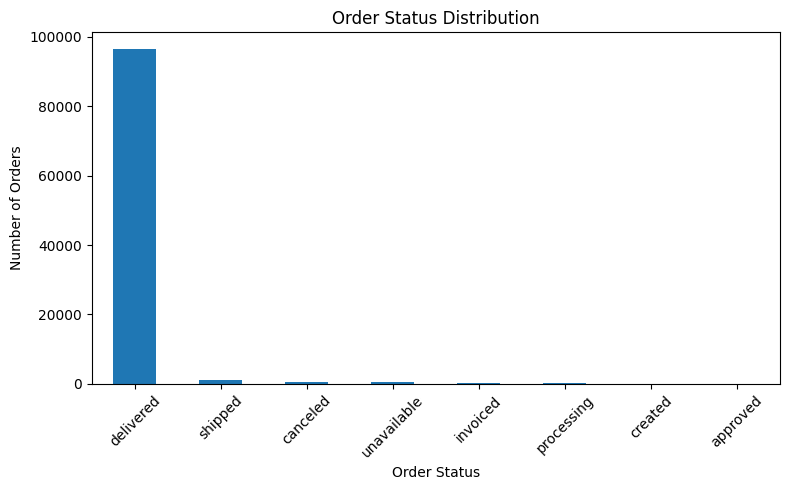

In [ ]:
import matplotlib.pyplot as plt

status_counts = orders_features["order_status"].value_counts()

plt.figure(figsize=(8, 5))
status_counts.plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
monthly_data = orders_features.merge(
    order_items_features[["order_id", "price"]],
    on="order_id"
)

monthly_revenue = monthly_data.groupby(
    pd.to_datetime(monthly_data["order_purchase_timestamp"]).dt.to_period("M")
)["price"].sum()

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'orders_features' is not defined

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

cleaned_folder = "/content/Cart2Insights/data/cleaned"

orders_features = pd.read_csv(
    cleaned_folder + "/orders_with_features.csv"
)

order_items_features = pd.read_csv(
    cleaned_folder + "/olist_order_items_dataset.csv"
)

monthly_data = orders_features.merge(
    order_items_features[["order_id", "price"]],
    on="order_id"
)

monthly_data["month"] = pd.to_datetime(
    monthly_data["order_purchase_timestamp"]
).dt.to_period("M")

monthly_revenue = monthly_data.groupby("month")["price"].sum()

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/Cart2Insights/data/cleaned/orders_with_features.csv'

In [ ]:
import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'sample_data']


In [ ]:
import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'sample_data']


In [ ]:
import os
print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
import os
import zipfile

zip_path = "/content/Cart2Insights_Backup.zip"
project_root = "/content/Cart2Insights"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(project_root)

cleaned_folder = project_root + "/data/cleaned"

print("Restored cleaned files:", len(os.listdir(cleaned_folder)))
print(os.listdir(cleaned_folder))

Restored cleaned files: 9
['olist_sellers_dataset.csv', 'product_category_name_translation.csv', 'olist_products_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_customers_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv']


In [ ]:
import pandas as pd
import os

cleaned_folder = "/content/Cart2Insights/data/cleaned"

cleaned_dataframes = {}

for file in os.listdir(cleaned_folder):
    if file.endswith(".csv") and file != "orders_with_features.csv":
        name = file.replace(".csv", "")
        cleaned_dataframes[name] = pd.read_csv(os.path.join(cleaned_folder, file))

orders_features = cleaned_dataframes["olist_orders_dataset"].copy()
order_items_features = cleaned_dataframes["olist_order_items_dataset"].copy()
customers_features = cleaned_dataframes["olist_customers_dataset"].copy()

# Order value
order_totals = order_items_features.groupby("order_id")["price"].sum()
orders_features["order_total"] = orders_features["order_id"].map(order_totals)

# Delivery time
orders_features["delivery_days"] = (
    pd.to_datetime(orders_features["order_delivered_customer_date"]) -
    pd.to_datetime(orders_features["order_purchase_timestamp"])
).dt.days

# Customer order count and repeat customer
orders_features["customer_unique_id"] = orders_features["customer_id"].map(
    customers_features.set_index("customer_id")["customer_unique_id"]
)

orders_features["customer_order_count"] = (
    orders_features.groupby("customer_unique_id")["order_id"].transform("count")
)

orders_features["repeat_customer"] = orders_features["customer_order_count"] > 1

# Delivery status
has_dates = (
    orders_features["order_delivered_customer_date"].notna() &
    orders_features["order_estimated_delivery_date"].notna()
)

orders_features["delivery_status"] = "Not Delivered"
orders_features.loc[has_dates, "delivery_status"] = "Delayed"

on_time = has_dates & (
    pd.to_datetime(orders_features["order_delivered_customer_date"]) <=
    pd.to_datetime(orders_features["order_estimated_delivery_date"])
)

orders_features.loc[on_time, "delivery_status"] = "On Time"

missing_estimate = (
    (orders_features["order_status"] == "delivered") &
    orders_features["order_delivered_customer_date"].notna() &
    orders_features["order_estimated_delivery_date"].isna()
)

orders_features.loc[missing_estimate, "delivery_status"] = "Missing Estimate"

# Save the feature-engineered data
orders_features.to_csv(
    cleaned_folder + "/orders_with_features.csv",
    index=False
)

print("Feature engineering restored!")
print("Shape:", orders_features.shape)
print(orders_features["delivery_status"].value_counts())

Feature engineering restored!
Shape: (99441, 14)
delivery_status
On Time          88649
Delayed           7827
Not Delivered     2965
Name: count, dtype: int64


import matplotlib.pyplot as plt

monthly_data = orders_features.merge(
    order_items_features[["order_id", "price"]],
    on="order_id"
)

monthly_data["month"] = pd.to_datetime(
    monthly_data["order_purchase_timestamp"]
).dt.to_period("M")

monthly_revenue = monthly_data.groupby("month")["price"].sum()

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

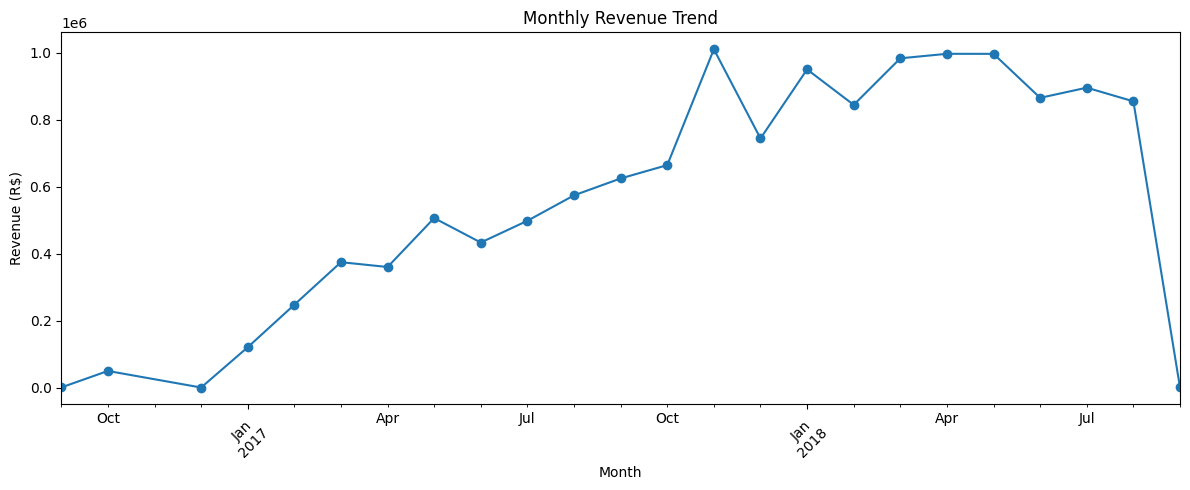

In [ ]:
import matplotlib.pyplot as plt

monthly_data = orders_features.merge(
    order_items_features[["order_id", "price"]],
    on="order_id"
)

monthly_data["month"] = pd.to_datetime(
    monthly_data["order_purchase_timestamp"]
).dt.to_period("M")

monthly_revenue = monthly_data.groupby("month")["price"].sum()

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

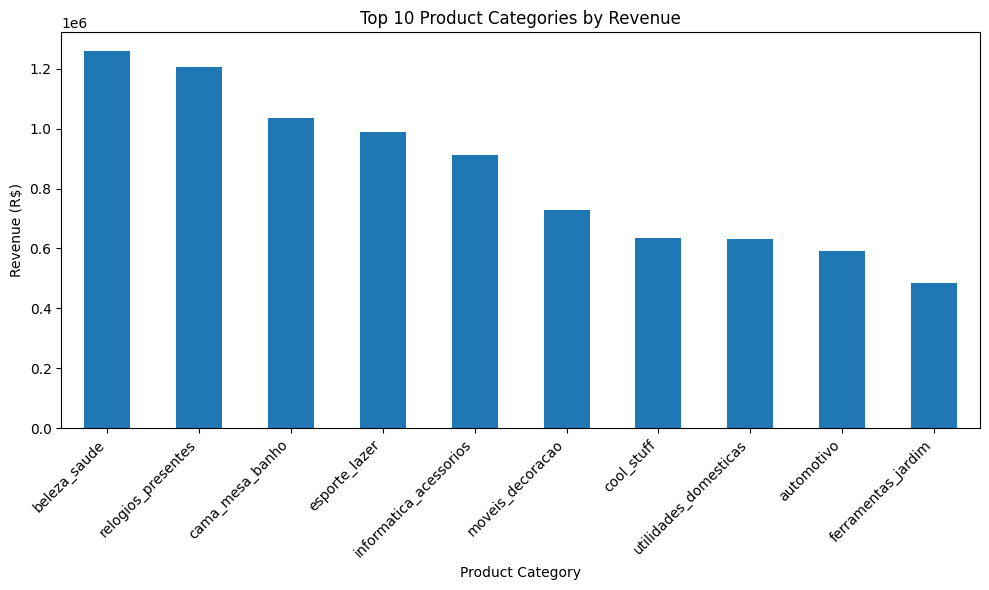

In [ ]:
category_data = order_items_features.merge(
    cleaned_dataframes["olist_products_dataset"][["product_id", "product_category_name"]],
    on="product_id"
)

category_revenue = (
    category_data.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
category_revenue.plot(kind="bar")
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

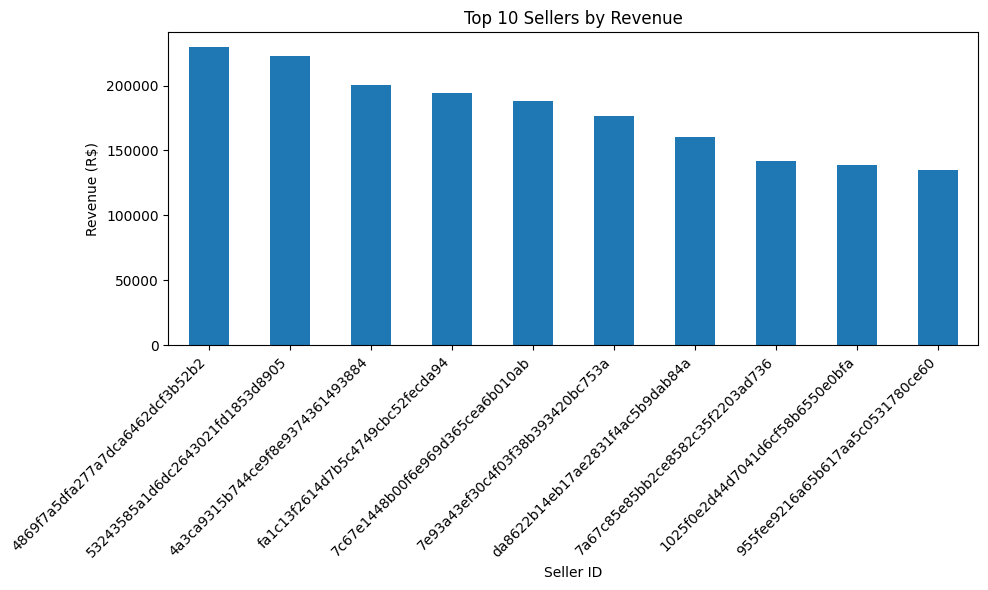

In [ ]:
seller_data = order_items_features.groupby("seller_id")["price"].sum()

top_sellers = seller_data.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
top_sellers.plot(kind="bar")
plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Seller ID")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

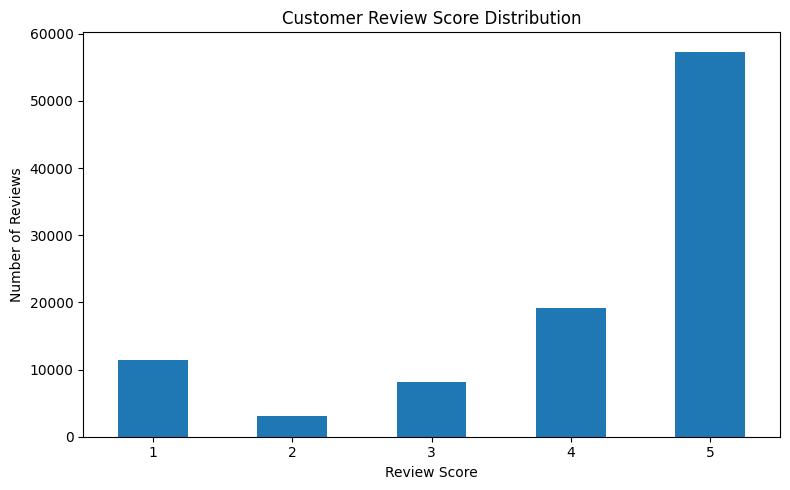

In [ ]:
review_data = cleaned_dataframes["olist_order_reviews_dataset"]

review_counts = review_data["review_score"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
review_counts.plot(kind="bar")
plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

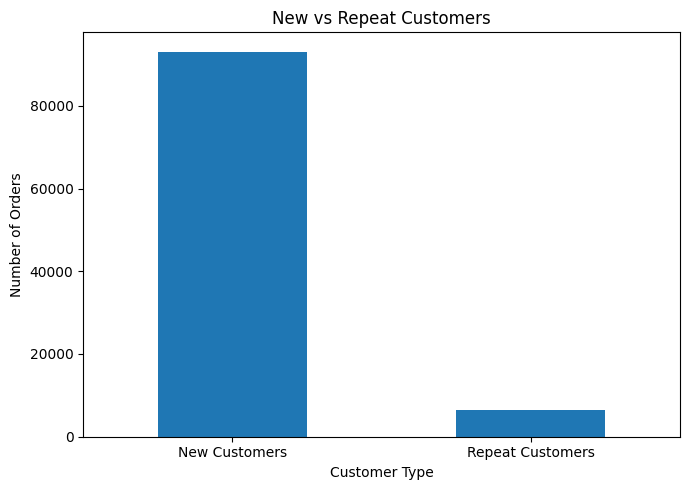

In [ ]:
customer_types = orders_features["repeat_customer"].value_counts()
customer_types.index = ["New Customers" if x == False else "Repeat Customers"
                        for x in customer_types.index]

plt.figure(figsize=(7, 5))
customer_types.plot(kind="bar")
plt.title("New vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

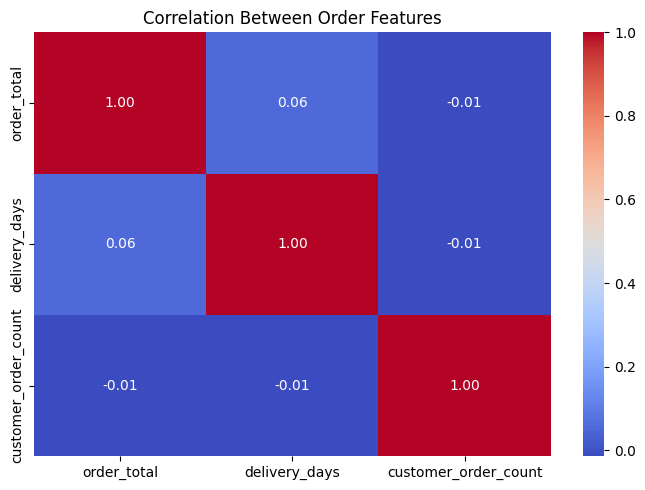

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_data = orders_features[
    ["order_total", "delivery_days", "customer_order_count"]
]

correlation = numeric_data.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Order Features")
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import ttest_ind

review_data = cleaned_dataframes["olist_order_reviews_dataset"]

test_data = orders_features[
    ["order_id", "delivery_status"]
].merge(
    review_data[["order_id", "review_score"]],
    on="order_id"
)

on_time_scores = test_data[
    test_data["delivery_status"] == "On Time"
]["review_score"].dropna()

delayed_scores = test_data[
    test_data["delivery_status"] == "Delayed"
]["review_score"].dropna()

t_stat, p_value = ttest_ind(
    on_time_scores,
    delayed_scores,
    equal_var=False
)

print("On-time average review:", on_time_scores.mean())
print("Delayed average review:", delayed_scores.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

On-time average review: 4.293577567732184
Delayed average review: 2.566549798727438
T-statistic: 89.55081413351807
P-value: 0.0


In [ ]:
from scipy.stats import f_oneway

category_data = order_items_features.merge(
    cleaned_dataframes["olist_products_dataset"][["product_id", "product_category_name"]],
    on="product_id"
)

category_groups = category_data.groupby("product_category_name")["price"].apply(list)

f_stat, p_value = f_oneway(*category_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 188.60771157282124
P-value: 0.0


In [ ]:
from scipy.stats import chi2_contingency

payment_data = cleaned_dataframes["olist_order_payments_dataset"]
order_data = cleaned_dataframes["olist_orders_dataset"]

merged_data = payment_data.merge(
    order_data[["order_id", "order_status"]],
    on="order_id"
)

table = pd.crosstab(
    merged_data["payment_type"],
    merged_data["order_status"]
)

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 677.0831369637666
P-value: 1.2047397488650834e-124
Degrees of freedom: 28


In [ ]:
import os

notebook_folder = "/content/Cart2Insights/notebooks"
os.makedirs(notebook_folder, exist_ok=True)

print("Statistical analysis completed.")
print("All three tests executed successfully.")

Statistical analysis completed.
All three tests executed successfully.


In [ ]:
import sqlite3
import os
import pandas as pd

cleaned_folder = "/content/Cart2Insights/data/cleaned"
database_path = "/content/Cart2Insights/cart2insights.db"

connection = sqlite3.connect(database_path)

for file in os.listdir(cleaned_folder):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(cleaned_folder, file))
        table_name = file.replace(".csv", "")
        table_name = table_name.replace("olist_", "").replace("_dataset", "")
        df.to_sql(table_name, connection, if_exists="replace", index=False)

connection.close()

print("SQL database created successfully!")

SQL database created successfully!


In [ ]:
import sqlite3

connection = sqlite3.connect(
    "/content/Cart2Insights/cart2insights.db"
)

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    connection
)

connection.close()

print(tables)
print("Total tables:", len(tables))

                                name
0                            sellers
1  product_category_name_translation
2               orders_with_features
3                           products
4                      order_reviews
5                     order_payments
6                        geolocation
7                          customers
8                             orders
9                        order_items
Total tables: 10


In [ ]:
!pip show streamlit

In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 24.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 53.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
import os

streamlit_folder = "/content/Cart2Insights/streamlit"
os.makedirs(streamlit_folder, exist_ok=True)

print("Streamlit folder ready!")

Streamlit folder ready!


In [ ]:
%%writefile /content/Cart2Insights/streamlit/app.py

import streamlit as st
import pandas as pd
import sqlite3

st.set_page_config(page_title="Cart2Insights Analytics", layout="wide")

st.title("Cart2Insights Analytics")
st.subheader("Decoding E-Commerce Performance")

# Connect to database
connection = sqlite3.connect("/content/Cart2Insights/cart2insights.db")

# Load data
orders = pd.read_sql("SELECT * FROM orders_with_features", connection)
items = pd.read_sql("SELECT * FROM order_items", connection)
customers = pd.read_sql("SELECT * FROM customers", connection)
reviews = pd.read_sql("SELECT * FROM order_reviews", connection)

connection.close()

# Business Overview
st.header("Business Overview")

total_orders = orders["order_id"].nunique()
total_customers = customers["customer_unique_id"].nunique()
total_sellers = 3095
total_revenue = items["price"].sum()
average_order_value = orders["order_total"].mean()
average_review = reviews["review_score"].mean()

col1, col2, col3 = st.columns(3)
col1.metric("Total Orders", f"{total_orders:,}")
col2.metric("Total Customers", f"{total_customers:,}")
col3.metric("Total Sellers", f"{total_sellers:,}")

col4, col5, col6 = st.columns(3)
col4.metric("Total Revenue", f"R$ {total_revenue:,.2f}")
col5.metric("Average Order Value", f"R$ {average_order_value:,.2f}")
col6.metric("Average Review Score", f"{average_review:.2f}/5")

st.success("Business overview loaded successfully!")

Writing /content/Cart2Insights/streamlit/app.py


In [ ]:
import os

print(os.path.exists("/content/Cart2Insights/streamlit/app.py"))

True


In [ ]:
%%writefile -a /content/Cart2Insights/streamlit/app.py

# Sales Analysis
st.header("Sales Analysis")

connection = sqlite3.connect("/content/Cart2Insights/cart2insights.db")

products = pd.read_sql("SELECT * FROM products", connection)

connection.close()

# Monthly Revenue
monthly_data = orders.merge(items, on="order_id")
monthly_data["month"] = pd.to_datetime(
    monthly_data["order_purchase_timestamp"]
).dt.to_period("M").astype(str)

monthly_revenue = monthly_data.groupby("month")["price"].sum()

st.subheader("Monthly Revenue")
st.line_chart(monthly_revenue)

# Revenue by Category
category_data = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id"
)

category_revenue = (
    category_data.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

st.subheader("Top 10 Categories by Revenue")
st.bar_chart(category_revenue)

# Top 10 Products
product_revenue = (
    items.groupby("product_id")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

st.subheader("Top 10 Products by Revenue")
st.bar_chart(product_revenue)

Appending to /content/Cart2Insights/streamlit/app.py


In [ ]:
%%writefile -a /content/Cart2Insights/streamlit/app.py

# Customer Analysis
st.header("Customer Analysis")

customer_data = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id"
)

# Customer Spending
customer_spending = (
    customer_data.groupby("customer_unique_id")["order_total"]
    .sum()
)

st.subheader("Customer Spending Distribution")
st.bar_chart(customer_spending.head(20))

# New vs Repeat Customers
customer_types = orders["repeat_customer"].value_counts()
customer_types.index = ["Repeat Customers" if x else "New Customers"
                        for x in customer_types.index]

st.subheader("New vs Repeat Customer Orders")
st.bar_chart(customer_types)

# Top Customers
top_customers = customer_spending.sort_values(ascending=False).head(10)

st.subheader("Top 10 Customers by Spending")
st.bar_chart(top_customers)

Appending to /content/Cart2Insights/streamlit/app.py


In [ ]:
%%writefile -a /content/Cart2Insights/streamlit/app.py

# Seller and Product Analysis
st.header("Seller and Product Analysis")

seller_data = items.groupby("seller_id")["price"].sum()
top_sellers = seller_data.sort_values(ascending=False).head(10)

st.subheader("Top 10 Sellers by Revenue")
st.bar_chart(top_sellers)

# Product Category Performance
category_performance = (
    category_data.groupby("product_category_name")
    .agg(
        total_revenue=("price", "sum"),
        total_items=("order_id", "count")
    )
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

st.subheader("Product Category Performance")
st.dataframe(category_performance)

Appending to /content/Cart2Insights/streamlit/app.py


In [ ]:
%%writefile -a /content/Cart2Insights/streamlit/app.py

# Delivery Analysis
st.header("Delivery Analysis")

average_delivery = orders["delivery_days"].mean()

st.metric("Average Delivery Time", f"{average_delivery:.2f} days")

delivery_counts = orders["delivery_status"].value_counts()

st.subheader("Delivery Status Distribution")
st.bar_chart(delivery_counts)

# Delivery Time by Order Status
delivery_time = (
    orders.groupby("delivery_status")["delivery_days"]
    .mean()
)

st.subheader("Average Delivery Days by Delivery Status")
st.bar_chart(delivery_time)

Appending to /content/Cart2Insights/streamlit/app.py


In [ ]:
%%writefile -a /content/Cart2Insights/streamlit/app.py

# Customer Experience Analysis
st.header("Customer Experience Analysis")

st.subheader("Customer Review Score Distribution")
review_counts = reviews["review_score"].value_counts().sort_index()
st.bar_chart(review_counts)

# Average Review Score
average_rating = reviews["review_score"].mean()
st.metric("Average Customer Rating", f"{average_rating:.2f}/5")

# Review Score by Delivery Status
review_delivery = orders[
    ["order_id", "delivery_status"]
].merge(
    reviews[["order_id", "review_score"]],
    on="order_id"
)

rating_by_delivery = (
    review_delivery.groupby("delivery_status")["review_score"]
    .mean()
)

st.subheader("Average Review Score by Delivery Status")
st.bar_chart(rating_by_delivery)

st.success("All dashboard sections have been added!")

Appending to /content/Cart2Insights/streamlit/app.py


In [ ]:
!streamlit run /content/Cart2Insights/streamlit/app.py &>/content/streamlit.log &

In [ ]:
!tail -20 /content/streamlit.log



2026-11-03 16:04:21.895 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.125.103.80:8501



In [ ]:
!pip install pyngrok

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-usw4c4-2tt8wzilrrkhr-c.us-west4.prod.r.colab.dev


In [ ]:
!tail -40 /content/streamlit.log

2026-11-03 16:17:23.150 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usw4c4-2tt8wzilrrkhr-c.us-west4.prod.r.colab.dev, host=m-s-usw4c4-2tt8wzilrrkhr.us-west4-c.c.codatalab-user-runtimes.internal:8007
2026-11-03 16:17:29.327 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usw4c4-2tt8wzilrrkhr-c.us-west4.prod.r.colab.dev, host=m-s-usw4c4-2tt8wzilrrkhr.us-west4-c.c.codatalab-user-runtimes.internal:8007
2026-11-03 16:17:38.602 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usw4c4-2tt8wzilrrkhr-c.us-west4.prod.r.colab.dev, host=m-s-usw4c4-2tt8wzilrrkhr.us-west4-c.c.codatalab-user-runtimes.internal:8007
2026-11-03 16:17:47.898 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usw4c4-2tt8wzilrrkhr-c.us-west4.prod.r.colab.dev, host=m-s-usw4c4-2tt8wzilrrkhr.us-west4-c.c.codatalab-user-runtimes.internal:8007
2026

In [ ]:
!pkill -f streamlit || true

^C


In [ ]:
!streamlit run /content/Cart2Insights/streamlit/app.py --server.enableCORS=false --server.enableXsrfProtection=false &>/content/streamlit.log &

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-usw4c4-2tt8wzilrrkhr-c.us-west4.prod.r.colab.dev


In [ ]:
import pandas as pd
import sqlite3

connection = sqlite3.connect("/content/Cart2Insights/cart2insights.db")
orders = pd.read_sql("SELECT * FROM orders_with_features", connection)
connection.close()

print(orders.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_total', 'delivery_days', 'customer_unique_id', 'customer_order_count', 'repeat_customer', 'delivery_status']


In [ ]:
customer_data = orders.copy()

customer_spending = customer_data.groupby("customer_unique_id")["order_total"].sum().reset_index()

customer_spending = customer_spending.sort_values("order_total", ascending=False)

st.subheader("Top 20 Customers by Spending")
st.bar_chart(customer_spending.head(20).set_index("customer_unique_id"))

NameError: name 'st' is not defined

In [ ]:
!sed -n '90,125p' /content/Cart2Insights/streamlit/app.py


# Customer Analysis
st.header("Customer Analysis")

customer_data = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id"
)

# Customer Spending
customer_spending = (
    customer_data.groupby("customer_unique_id")["order_total"]
    .sum()
)

st.subheader("Customer Spending Distribution")
st.bar_chart(customer_spending.head(20))

# New vs Repeat Customers
customer_types = orders["repeat_customer"].value_counts()
customer_types.index = ["Repeat Customers" if x else "New Customers"
                        for x in customer_types.index]

st.subheader("New vs Repeat Customer Orders")
st.bar_chart(customer_types)

# Top Customers
top_customers = customer_spending.sort_values(ascending=False).head(10)

st.subheader("Top 10 Customers by Spending")
st.bar_chart(top_customers)

# Seller and Product Analysis
st.header("Seller and Product Analysis")

seller_data = items.groupby("seller_id")["price"].sum()


In [ ]:
# Customer Analysis
st.header("Customer Analysis")

# Customer Spending
customer_data = orders.copy()

customer_spending = (
    customer_data.groupby("customer_unique_id")["order_total"]
    .sum()
    .sort_values(ascending=False)
)

st.subheader("Top 20 Customers by Spending")
st.bar_chart(customer_spending.head(20))

# New vs Repeat Customers
customer_types = orders["repeat_customer"].value_counts()

customer_types.index = [
    "Repeat Customers" if x else "New Customers"
    for x in customer_types.index
]

st.subheader("New vs Repeat Customer Orders")
st.bar_chart(customer_types)

# Top 10 Customers
top_customers = customer_spending.head(10)

st.subheader("Top 10 Customers by Spending")
st.bar_chart(top_customers)

# Seller and Product Analysis
st.header("Seller and Product Analysis")

NameError: name 'st' is not defined

In [ ]:
file_path = "/content/Cart2Insights/streamlit/app.py"

with open(file_path, "r") as file:
    code = file.read()

start = code.index("# Customer Analysis")
end = code.index("# Seller and Product Analysis")

new_section = '''# Customer Analysis
st.header("Customer Analysis")

customer_data = orders.copy()

customer_spending = (
    customer_data.groupby("customer_unique_id")["order_total"]
    .sum()
    .sort_values(ascending=False)
)

st.subheader("Customer Spending Distribution")
st.bar_chart(customer_spending.head(20))

customer_types = orders["repeat_customer"].value_counts()
customer_types.index = [
    "Repeat Customers" if x else "New Customers"
    for x in customer_types.index
]

st.subheader("New vs Repeat Customer Orders")
st.bar_chart(customer_types)

top_customers = customer_spending.head(10)

st.subheader("Top 10 Customers by Spending")
st.bar_chart(top_customers)

'''

code = code[:start] + new_section + code[end:]

with open(file_path, "w") as file:
    file.write(code)

print("Customer Analysis section updated successfully!")

Customer Analysis section updated successfully!


In [ ]:
!pkill -f streamlit || true

^C


In [ ]:
!streamlit run /content/Cart2Insights/streamlit/app.py --server.enableCORS=false --server.enableXsrfProtection=false &>/content/streamlit.log &

In [ ]:
from google.colab.output import eval_js
url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-usw4c4-2tt8wzilrrkhr-c.us-west4.prod.r.colab.dev


In [ ]:
file_path = "/content/Cart2Insights/streamlit/app.py"

with open(file_path, "r") as file:
    code = file.read()

start = code.index("# Customer Analysis")
end = code.index("# Seller and Product Analysis")

new_section = '''# Customer Analysis
st.header("Customer Analysis")

customer_data = orders.copy()

customer_spending = (
    customer_data.groupby("customer_unique_id")["order_total"]
    .sum()
    .sort_values(ascending=False)
)

st.subheader("Customer Spending Distribution")
st.bar_chart(customer_spending.head(20))

customer_types = orders["repeat_customer"].value_counts()
customer_types.index = [
    "Repeat Customers" if x else "New Customers"
    for x in customer_types.index
]

st.subheader("New vs Repeat Customer Orders")
st.bar_chart(customer_types)

top_customers = customer_spending.head(10)

st.subheader("Top 10 Customers by Spending")
st.bar_chart(top_customers)

'''

code = code[:start] + new_section + code[end:]

with open(file_path, "w") as file:
    file.write(code)

print("Customer Analysis section updated successfully!")

FileNotFoundError: [Errno 2] No such file or directory: '/content/Cart2Insights/streamlit/app.py'

In [ ]:
import os

print("Folders in /content:")
print(os.listdir("/content"))

Folders in /content:
['.config', 'sample_data']


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'Cart2Insights_Backup.zip', 'sample_data']


In [ ]:
import os
import zipfile

zip_path = "/content/Cart2Insights_Backup.zip"
project_root = "/content/Cart2Insights"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(project_root)

print("Project restored successfully!")
print("Folders:", os.listdir(project_root))
print("Cleaned files:", os.listdir(project_root + "/data/cleaned"))

BadZipFile: File is not a zip file

In [ ]:
import os

file_path = "/content/Cart2Insights_Backup.zip"

print("File size:", os.path.getsize(file_path), "bytes")

with open(file_path, "rb") as f:
    print("File signature:", f.read(4))

File size: 30408704 bytes
File signature: b'PK\x03\x04'


In [ ]:
import zipfile

zip_path = "/content/Cart2Insights_Backup.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print("ZIP integrity:", z.testzip())
    print("Files found:", len(z.namelist()))

BadZipFile: File is not a zip file

In [ ]:
import os

print(os.path.getsize("/content/Cart2Insights_Backup.zip"))

85801206


In [ ]:
import zipfile

zip_path = "/content/Cart2Insights_Backup.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print("ZIP integrity:", z.testzip())
    print("Total files:", len(z.namelist()))

ZIP integrity: None
Total files: 24


In [ ]:
import zipfile
import os

zip_path = "/content/Cart2Insights_Backup.zip"
project_root = "/content/Cart2Insights"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(project_root)

print("Project restored successfully!")
print(os.listdir(project_root))

Project restored successfully!
['data', 'notebooks', 'streamlit']


In [ ]:
import os

app_path = "/content/Cart2Insights/streamlit/app.py"

print("app.py exists:", os.path.exists(app_path))

if os.path.exists(app_path):
    print("File size:", os.path.getsize(app_path), "bytes")

app.py exists: False


In [ ]:
import os

for root, dirs, files in os.walk("/content/Cart2Insights"):
    for file in files:
        if file.endswith(".py"):
            print(os.path.join(root, file))

In [ ]:
import os

for folder in ["data", "notebooks", "streamlit"]:
    path = "/content/Cart2Insights/" + folder
    print("\n", folder)
    print(os.listdir(path))


 data
['raw', 'cleaned']

 notebooks
[]

 streamlit
[]


In [ ]:
import zipfile

zip_path = "/content/Cart2Insights_Backup.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    for item in z.infolist():
        print(item.filename, "|", item.file_size, "bytes")

data/ | 0 bytes
notebooks/ | 0 bytes
streamlit/ | 0 bytes
data/cleaned/ | 0 bytes
data/raw/ | 0 bytes
data/cleaned/olist_customers_dataset.csv | 8562270 bytes
data/cleaned/olist_products_dataset.csv | 2800200 bytes
data/cleaned/olist_orders_dataset.csv | 16511915 bytes
data/cleaned/olist_geolocation_dataset.csv | 43333586 bytes
data/cleaned/olist_order_payments_dataset.csv | 5633362 bytes
data/cleaned/olist_order_reviews_dataset.csv | 13955535 bytes
data/cleaned/olist_sellers_dataset.csv | 163590 bytes
data/cleaned/olist_order_items_dataset.csv | 14911576 bytes
data/cleaned/product_category_name_translation.csv | 2540 bytes
data/raw/.ipynb_checkpoints/ | 0 bytes
data/raw/olist_customers_dataset.csv | 9033957 bytes
data/raw/olist_products_dataset.csv | 2379446 bytes
data/raw/olist_orders_dataset.csv | 17654914 bytes
data/raw/olist_geolocation_dataset.csv | 61273883 bytes
data/raw/olist_order_payments_dataset.csv | 5777138 bytes
data/raw/olist_order_reviews_dataset.csv | 14451670 bytes
d

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import os

project_path = "/content/Cart2Insights"

print("Project folder exists:", os.path.exists(project_path))
print("Project contents:", os.listdir(project_path))
print("Raw data files:", os.listdir(project_path + "/data/raw"))

Project folder exists: True
Project contents: ['data', 'notebooks', 'streamlit']
Raw data files: ['olist_order_items_dataset.csv', 'product_category_name_translation.csv', 'olist_orders_dataset.csv', 'olist_sellers_dataset.csv', 'olist_customers_dataset.csv', 'olist_order_payments_dataset.csv', '.ipynb_checkpoints', 'olist_order_reviews_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_products_dataset.csv']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import os

project_path = "/content/Cart2Insights"

print("Project folder exists:", os.path.exists(project_path))
print("Project contents:", os.listdir(project_path))
print("Raw data files:", os.listdir(project_path + "/data/raw"))

Project folder exists: True
Project contents: ['data', 'notebooks', 'streamlit']
Raw data files: ['olist_order_items_dataset.csv', 'product_category_name_translation.csv', 'olist_orders_dataset.csv', 'olist_sellers_dataset.csv', 'olist_customers_dataset.csv', 'olist_order_payments_dataset.csv', '.ipynb_checkpoints', 'olist_order_reviews_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_products_dataset.csv']


In [ ]:
import os

cleaned_path = "/content/Cart2Insights/data/cleaned"

print("Cleaned folder exists:", os.path.exists(cleaned_path))

if os.path.exists(cleaned_path):
    print("Cleaned files:")
    for file in os.listdir(cleaned_path):
        if file.endswith(".csv"):
            print(file)

Cleaned folder exists: True
Cleaned files:
olist_order_items_dataset.csv
product_category_name_translation.csv
olist_orders_dataset.csv
olist_sellers_dataset.csv
olist_customers_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_geolocation_dataset.csv
olist_products_dataset.csv


In [ ]:
import os
import pandas as pd

raw_path = "/content/Cart2Insights/data/raw"
cleaned_path = "/content/Cart2Insights/data/cleaned"

for file in sorted(os.listdir(raw_path)):
    if file.endswith(".csv"):
        raw_df = pd.read_csv(os.path.join(raw_path, file), on_bad_lines="skip")
        clean_df = pd.read_csv(os.path.join(cleaned_path, file), on_bad_lines="skip")

        print(
            file,
            "| Raw:", raw_df.shape,
            "| Cleaned:", clean_df.shape
        )

olist_customers_dataset.csv | Raw: (99441, 5) | Cleaned: (99441, 5)
olist_geolocation_dataset.csv | Raw: (1000163, 5) | Cleaned: (738332, 5)
olist_order_items_dataset.csv | Raw: (112650, 7) | Cleaned: (112650, 7)
olist_order_payments_dataset.csv | Raw: (103886, 5) | Cleaned: (103886, 5)
olist_order_reviews_dataset.csv | Raw: (99224, 7) | Cleaned: (99224, 7)
olist_orders_dataset.csv | Raw: (99441, 8) | Cleaned: (99441, 8)
olist_products_dataset.csv | Raw: (32951, 9) | Cleaned: (32951, 9)
olist_sellers_dataset.csv | Raw: (3095, 4) | Cleaned: (3095, 4)
product_category_name_translation.csv | Raw: (71, 2) | Cleaned: (71, 2)


In [ ]:
import pandas as pd

geo_path = "/content/Cart2Insights/data/cleaned/olist_geolocation_dataset.csv"

geo = pd.read_csv(geo_path)

print("Total rows:", len(geo))
print("Exact duplicate rows:", geo.duplicated().sum())
print("Duplicate ZIP prefixes:", geo["geolocation_zip_code_prefix"].duplicated().sum())
print("Missing values:", geo.isnull().sum().sum())

Total rows: 738332
Exact duplicate rows: 0
Duplicate ZIP prefixes: 719317
Missing values: 0


In [ ]:
import pandas as pd
import os

cleaned_path = "/content/Cart2Insights/data/cleaned"

for file in sorted(os.listdir(cleaned_path)):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(cleaned_path, file))

        print("\n", file)
        print("Rows:", len(df))
        print("Exact duplicates:", df.duplicated().sum())
        print("Missing values:", df.isnull().sum().sum())


 olist_customers_dataset.csv
Rows: 99441
Exact duplicates: 0
Missing values: 0

 olist_geolocation_dataset.csv
Rows: 738332
Exact duplicates: 0
Missing values: 0

 olist_order_items_dataset.csv
Rows: 112650
Exact duplicates: 0
Missing values: 0

 olist_order_payments_dataset.csv
Rows: 103886
Exact duplicates: 0
Missing values: 0

 olist_order_reviews_dataset.csv
Rows: 99224
Exact duplicates: 0
Missing values: 145903

 olist_orders_dataset.csv
Rows: 99441
Exact duplicates: 0
Missing values: 4908

 olist_products_dataset.csv
Rows: 32951
Exact duplicates: 0
Missing values: 1838

 olist_sellers_dataset.csv
Rows: 3095
Exact duplicates: 0
Missing values: 0

 product_category_name_translation.csv
Rows: 71
Exact duplicates: 0
Missing values: 0


In [ ]:
import pandas as pd
import os

cleaned_path = "/content/Cart2Insights/data/cleaned"

for file in sorted(os.listdir(cleaned_path)):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(cleaned_path, file))
        missing = df.isnull().sum()
        missing = missing[missing > 0]

        if len(missing) > 0:
            print("\n", file)
            print(missing)


 olist_order_reviews_dataset.csv
review_comment_title      87656
review_comment_message    58247
dtype: int64

 olist_orders_dataset.csv
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

 olist_products_dataset.csv
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [ ]:
import pandas as pd

orders_path = "/content/Cart2Insights/data/cleaned/olist_orders_dataset.csv"

orders_check = pd.read_csv(orders_path)

date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for column in date_columns:
    print("\nMissing:", column)
    print(
        orders_check[orders_check[column].isnull()]
        ["order_status"]
        .value_counts()
    )


Missing: order_approved_at
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

Missing: order_delivered_carrier_date
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

Missing: order_delivered_customer_date
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [ ]:
delivered_missing = orders_check[
    (orders_check["order_status"] == "delivered") &
    (
        orders_check["order_approved_at"].isnull() |
        orders_check["order_delivered_carrier_date"].isnull() |
        orders_check["order_delivered_customer_date"].isnull()
    )
]

print("Delivered orders with missing dates:", len(delivered_missing))

display(
    delivered_missing[
        [
            "order_id",
            "order_status",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ]
)

Delivered orders with missing dates: 23


,order_id,order_status,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN
5323,e04abd8149ef81b95221e88f6ed9ab6a,delivered,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33
16567,8a9adc69528e1001fc68dd0aaebbb54a,delivered,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06
19031,7013bcfc1c97fe719a7b5e05e61c12db,delivered,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN
22663,5cf925b116421afa85ee25e99b4c34fb,delivered,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47
23156,12a95a3c06dbaec84bcfb0e2da5d228a,delivered,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19
26800,c1d4211b3dae76144deccd6c74144a88,delivered,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01
38290,d69e5d356402adc8cf17e08b5033acfb,delivered,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58
39334,d77031d6a3c8a52f019764e68f211c69,delivered,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23


In [ ]:
products_path = "/content/Cart2Insights/data/cleaned/olist_products_dataset.csv"

products_check = pd.read_csv(products_path)

missing_products = products_check[
    products_check.isnull().any(axis=1)
]

print("Products with missing values:", len(missing_products))
print("\nMissing values by column:")
print(missing_products.isnull().sum())

display(missing_products.head(10))

Products with missing values: 611

Missing values by column:
product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,Unknown,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,Unknown,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,Unknown,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,Unknown,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,Unknown,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,Unknown,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,Unknown,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,Unknown,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,Unknown,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,Unknown,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [ ]:
reviews_path = "/content/Cart2Insights/data/cleaned/olist_order_reviews_dataset.csv"

reviews_check = pd.read_csv(reviews_path)

print("Total reviews:", len(reviews_check))

print("\nMissing values:")
print(reviews_check.isnull().sum())

print("\nReview score distribution:")
print(reviews_check["review_score"].value_counts().sort_index())

Total reviews: 99224

Missing values:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Review score distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


In [ ]:
items_path = "/content/Cart2Insights/data/cleaned/olist_order_items_dataset.csv"
products_path = "/content/Cart2Insights/data/cleaned/olist_products_dataset.csv"

items_check = pd.read_csv(items_path)
products_check = pd.read_csv(products_path)

print("ORDER ITEMS")
print("Zero or negative prices:")
print(items_check[items_check["price"] <= 0].shape[0])

print("Zero or negative freight values:")
print(items_check[items_check["freight_value"] < 0].shape[0])

print("\nPRODUCTS")
measurement_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for column in measurement_columns:
    print(column, "zero or negative:",
          (products_check[column] <= 0).sum())

ORDER ITEMS
Zero or negative prices:
0
Zero or negative freight values:
0

PRODUCTS
product_weight_g zero or negative: 4
product_length_cm zero or negative: 0
product_height_cm zero or negative: 0
product_width_cm zero or negative: 0


In [ ]:
invalid_weights = products_check[
    products_check["product_weight_g"] <= 0
]

display(invalid_weights[
    [
        "product_id",
        "product_category_name",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
])

,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,0.0,30.0,25.0,30.0


In [ ]:
import pandas as pd

products_path = "/content/Cart2Insights/data/cleaned/olist_products_dataset.csv"

products_check = pd.read_csv(products_path)

# Replace invalid zero weights with missing values
products_check.loc[
    products_check["product_weight_g"] <= 0,
    "product_weight_g"
] = float("nan")

# Save the corrected cleaned dataset
products_check.to_csv(products_path, index=False)

print("Invalid zero weights corrected!")
print("Remaining zero weights:",
      (products_check["product_weight_g"] == 0).sum())
print("Missing product weights:",
      products_check["product_weight_g"].isnull().sum())

Invalid zero weights corrected!
Remaining zero weights: 0
Missing product weights: 6


In [ ]:
payments_path = "/content/Cart2Insights/data/cleaned/olist_order_payments_dataset.csv"
reviews_path = "/content/Cart2Insights/data/cleaned/olist_order_reviews_dataset.csv"

payments_check = pd.read_csv(payments_path)
reviews_check = pd.read_csv(reviews_path)

print("PAYMENT VALIDATION")
print("Invalid payment values:",
      (payments_check["payment_value"] <= 0).sum())
print("Invalid installments:",
      (payments_check["payment_installments"] <= 0).sum())

print("\nREVIEW VALIDATION")
print("Invalid review scores:",
      (~reviews_check["review_score"].between(1, 5)).sum())

PAYMENT VALIDATION
Invalid payment values: 9
Invalid installments: 2

REVIEW VALIDATION
Invalid review scores: 0


In [ ]:
invalid_payments = payments_check[
    (payments_check["payment_value"] <= 0) |
    (payments_check["payment_installments"] <= 0)
]

print("Invalid payment records:", len(invalid_payments))

display(invalid_payments)

Invalid payment records: 11


,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.00
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.00
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.00
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00


In [ ]:
payments_path = "/content/Cart2Insights/data/cleaned/olist_order_payments_dataset.csv"

payments_check = pd.read_csv(payments_path)

# Replace invalid zero installments with missing values
payments_check.loc[
    payments_check["payment_installments"] <= 0,
    "payment_installments"
] = float("nan")

# Save the corrected cleaned dataset
payments_check.to_csv(payments_path, index=False)

print("Payment data corrected!")
print("Zero installments remaining:",
      (payments_check["payment_installments"] == 0).sum())
print("Missing installments:",
      payments_check["payment_installments"].isnull().sum())
print("Zero-value payments retained:",
      (payments_check["payment_value"] == 0).sum())

Payment data corrected!
Zero installments remaining: 0
Missing installments: 2
Zero-value payments retained: 9


In [ ]:
print("Invalid payment sequence numbers:",
      (payments_check["payment_sequential"] <= 0).sum())

print("Missing payment sequence numbers:",
      payments_check["payment_sequential"].isnull().sum())

print("\nPayment sequence distribution:")
print(payments_check["payment_sequential"].value_counts().sort_index().head(15))

Invalid payment sequence numbers: 0
Missing payment sequence numbers: 0

Payment sequence distribution:
payment_sequential
1     99360
2      3039
3       581
4       278
5       170
6       118
7        82
8        54
9        43
10       34
11       29
12       21
13       13
14       10
15        8
Name: count, dtype: int64


In [ ]:
orders_check = pd.read_csv(
    "/content/Cart2Insights/data/cleaned/olist_orders_dataset.csv"
)

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for col in date_columns:
    orders_check[col] = pd.to_datetime(
        orders_check[col], errors="coerce"
    )

print("Approval before purchase:",
      (orders_check["order_approved_at"] <
       orders_check["order_purchase_timestamp"]).sum())

print("Carrier delivery before purchase:",
      (orders_check["order_delivered_carrier_date"] <
       orders_check["order_purchase_timestamp"]).sum())

print("Customer delivery before purchase:",
      (orders_check["order_delivered_customer_date"] <
       orders_check["order_purchase_timestamp"]).sum())

print("Customer delivery before carrier:",
      (orders_check["order_delivered_customer_date"] <
       orders_check["order_delivered_carrier_date"]).sum())

Approval before purchase: 0
Carrier delivery before purchase: 166
Customer delivery before purchase: 0
Customer delivery before carrier: 23


In [ ]:
invalid_dates = orders_check[
    (
        orders_check["order_delivered_carrier_date"] <
        orders_check["order_purchase_timestamp"]
    ) |
    (
        orders_check["order_delivered_customer_date"] <
        orders_check["order_delivered_carrier_date"]
    )
]

print("Orders with timestamp inconsistencies:", len(invalid_dates))

display(invalid_dates[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
].head(30))

Orders with timestamp inconsistencies: 189


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00,2018-08-24 14:58:37
1111,ad133696906f6a78826daa0911b7daec,delivered,2018-06-15 15:41:22,2018-06-15 16:19:23,2018-06-15 14:52:00,2018-06-22 18:09:37
1329,74e033208dc13a7b8127eb8e73d09b76,delivered,2018-05-02 10:48:44,2018-05-02 11:13:45,2018-05-02 09:49:00,2018-05-07 23:06:36
1372,a6b58794fd2ba533359a76c08df576e3,delivered,2018-05-14 15:18:23,2018-05-14 15:33:35,2018-05-14 13:46:00,2018-05-19 19:33:32
1864,5792e0b1c8c8a2bf53af468c9a422c88,delivered,2018-07-26 13:25:14,2018-07-26 13:35:14,2018-07-26 12:42:00,2018-07-30 14:45:02
2760,c3eb293fd154223498b6551a728203e8,delivered,2018-07-19 14:06:04,2018-07-19 14:22:51,2018-07-19 13:49:00,2018-07-24 19:35:36
3473,b0c2a7d04b165525254254a728c50a4e,delivered,2018-06-07 13:28:30,2018-06-07 13:57:22,2018-06-07 13:22:00,2018-06-21 17:36:43
3661,2033a4586b5bec3229ebc1675a8ae092,delivered,2018-06-12 10:10:25,2018-06-12 10:39:59,2018-06-12 10:09:00,2018-06-19 14:08:27
4114,08adcddad19d3acf37d1fa01cb9ded1e,delivered,2018-06-27 11:16:44,2018-06-27 11:30:56,2018-06-27 10:57:00,2018-06-29 17:39:53
4159,dee6298ce7d1fb2645141ef9972157aa,shipped,2018-04-30 14:06:12,2018-04-30 14:15:24,2018-04-30 12:59:00,NaT


In [ ]:
carrier_diff = (
    orders_check["order_purchase_timestamp"] -
    orders_check["order_delivered_carrier_date"]
).dt.total_seconds() / 60

delivery_diff = (
    orders_check["order_delivered_carrier_date"] -
    orders_check["order_delivered_customer_date"]
).dt.total_seconds() / 60

print("Carrier before purchase — difference in minutes:")
print(carrier_diff[carrier_diff > 0].describe())

print("\nCustomer delivery before carrier — difference in minutes:")
print(delivery_diff[delivery_diff > 0].describe())

Carrier before purchase — difference in minutes:
count       166.000000
mean       1562.368675
std       19135.430706
min           0.400000
25%          14.066667
50%          35.991667
75%          61.050000
max      246545.883333
dtype: float64

Customer delivery before carrier — difference in minutes:
count       23.000000
mean      4707.307971
std       5358.484182
min         23.300000
25%       1400.300000
50%       2391.866667
75%       7725.541667
max      23178.483333
dtype: float64


In [ ]:
# Identify timestamp chronology issues
orders_check["carrier_before_purchase"] = (
    orders_check["order_delivered_carrier_date"] <
    orders_check["order_purchase_timestamp"]
)

orders_check["customer_before_carrier"] = (
    orders_check["order_delivered_customer_date"] <
    orders_check["order_delivered_carrier_date"]
)

# Keep only orders with at least one timestamp issue
timestamp_issues = orders_check[
    orders_check["carrier_before_purchase"] |
    orders_check["customer_before_carrier"]
].copy()

# Save a separate report without changing the original dataset
report_folder = "/content/Cart2Insights/reports"
os.makedirs(report_folder, exist_ok=True)

report_path = os.path.join(
    report_folder,
    "order_timestamp_issues.csv"
)

timestamp_issues.to_csv(report_path, index=False)

print("Timestamp issue report saved successfully!")
print("Total affected orders:", len(timestamp_issues))
print("Carrier before purchase:",
      timestamp_issues["carrier_before_purchase"].sum())
print("Customer before carrier:",
      timestamp_issues["customer_before_carrier"].sum())
print("Report location:", report_path)

Timestamp issue report saved successfully!
Total affected orders: 189
Carrier before purchase: 166
Customer before carrier: 23
Report location: /content/Cart2Insights/reports/order_timestamp_issues.csv


In [ ]:
orders_path = "/content/Cart2Insights/data/cleaned/olist_orders_dataset.csv"

orders_check = pd.read_csv(orders_path)

print("Total order records:", len(orders_check))
print("Duplicate order IDs:", orders_check["order_id"].duplicated().sum())
print("Missing order IDs:", orders_check["order_id"].isna().sum())
print("Unique order IDs:", orders_check["order_id"].nunique())

Total order records: 99441
Duplicate order IDs: 0
Missing order IDs: 0
Unique order IDs: 99441


In [ ]:
carrier_before = (
    orders_check["order_delivered_carrier_date"] <
    orders_check["order_purchase_timestamp"]
)

customer_before_carrier = (
    orders_check["order_delivered_customer_date"] <
    orders_check["order_delivered_carrier_date"]
)

timestamp_issues = orders_check.loc[
    carrier_before | customer_before_carrier
]

print("Affected orders by order status:")
print(timestamp_issues["order_status"].value_counts())

print("\nTotal affected orders:", len(timestamp_issues))

Affected orders by order status:
order_status
delivered    188
shipped        1
Name: count, dtype: int64

Total affected orders: 189


In [ ]:
delivered_issues = timestamp_issues[
    timestamp_issues["order_status"] == "delivered"
]

print("Delivered orders with timestamp issues:")
print("Total:", len(delivered_issues))

print("\nCarrier before purchase:")
print(
    (
        delivered_issues["order_delivered_carrier_date"]
        < delivered_issues["order_purchase_timestamp"]
    ).sum()
)

print("\nCustomer delivery before carrier:")
print(
    (
        delivered_issues["order_delivered_customer_date"]
        < delivered_issues["order_delivered_carrier_date"]
    ).sum()
)

Delivered orders with timestamp issues:
Total: 188

Carrier before purchase:
165

Customer delivery before carrier:
23


In [ ]:
both_issues = (
    (timestamp_issues["order_delivered_carrier_date"] <
     timestamp_issues["order_purchase_timestamp"])
    &
    (timestamp_issues["order_delivered_customer_date"] <
     timestamp_issues["order_delivered_carrier_date"])
)

print("Orders with both timestamp issues:", both_issues.sum())

print("Orders with only carrier-before-purchase:",
      (carrier_before & ~customer_before_carrier).sum())

print("Orders with only customer-before-carrier:",
      (~carrier_before & customer_before_carrier).sum())

Orders with both timestamp issues: 0
Orders with only carrier-before-purchase: 166
Orders with only customer-before-carrier: 23


In [ ]:
import pandas as pd
import os

timestamp_summary = pd.DataFrame({
    "Issue": [
        "Carrier delivery before purchase",
        "Customer delivery before carrier",
        "Both timestamp issues",
        "Total unique affected orders"
    ],
    "Affected_Orders": [
        166,
        23,
        0,
        189
    ]
})

report_path = "/content/Cart2Insights/reports/timestamp_summary.csv"

os.makedirs(os.path.dirname(report_path), exist_ok=True)

timestamp_summary.to_csv(report_path, index=False)

print(timestamp_summary)
print("\nTimestamp summary report saved successfully!")
print("Location:", report_path)

                              Issue  Affected_Orders
0  Carrier delivery before purchase              166
1  Customer delivery before carrier               23
2             Both timestamp issues                0
3      Total unique affected orders              189

Timestamp summary report saved successfully!
Location: /content/Cart2Insights/reports/timestamp_summary.csv


In [ ]:
orders_path = "/content/Cart2Insights/data/cleaned/olist_orders_dataset.csv"

orders_check = pd.read_csv(orders_path)

print("Total order records:", len(orders_check))

print(
    "Duplicate order IDs:",
    orders_check["order_id"].duplicated().sum()
)

print(
    "Missing order IDs:",
    orders_check["order_id"].isna().sum()
)

print(
    "Unique order IDs:",
    orders_check["order_id"].nunique()
)

Total order records: 99441
Duplicate order IDs: 0
Missing order IDs: 0
Unique order IDs: 99441


In [ ]:
customers_path = "/content/Cart2Insights/data/cleaned/olist_customers_dataset.csv"

customers_check = pd.read_csv(customers_path)

print("Total customer records:", len(customers_check))
print("Duplicate customer IDs:",
      customers_check["customer_id"].duplicated().sum())
print("Missing customer IDs:",
      customers_check["customer_id"].isna().sum())
print("Unique customer IDs:",
      customers_check["customer_id"].nunique())

print("\nDuplicate customer unique IDs:",
      customers_check["customer_unique_id"].duplicated().sum())

Total customer records: 99441
Duplicate customer IDs: 0
Missing customer IDs: 0
Unique customer IDs: 99441

Duplicate customer unique IDs: 3345


In [ ]:
repeat_customers = (
    customers_check["customer_unique_id"]
    .value_counts()
)

print("Total unique customers:",
      customers_check["customer_unique_id"].nunique())

print("Customers appearing more than once:",
      (repeat_customers > 1).sum())

print("\nTop 10 customer order-record counts:")
print(repeat_customers.head(10))

Total unique customers: 96096
Customers appearing more than once: 2997

Top 10 customer order-record counts:
customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    17
3e43e6105506432c953e165fb2acf44c     9
ca77025e7201e3b30c44b472ff346268     7
1b6c7548a2a1f9037c1fd3ddfed95f33     7
6469f99c1f9dfae7733b25662e7f1782     7
f0e310a6839dce9de1638e0fe5ab282a     6
63cfc61cee11cbe306bff5857d00bfe4     6
12f5d6e1cbf93dafd9dcc19095df0b3d     6
de34b16117594161a6a89c50b289d35a     6
47c1a3033b8b77b3ab6e109eb4d5fdf3     6
Name: count, dtype: int64


In [ ]:
sellers_path = "/content/Cart2Insights/data/cleaned/olist_sellers_dataset.csv"

sellers_check = pd.read_csv(sellers_path)

print("Total seller records:", len(sellers_check))
print("Duplicate seller IDs:",
      sellers_check["seller_id"].duplicated().sum())
print("Missing seller IDs:",
      sellers_check["seller_id"].isna().sum())
print("Unique seller IDs:",
      sellers_check["seller_id"].nunique())

Total seller records: 3095
Duplicate seller IDs: 0
Missing seller IDs: 0
Unique seller IDs: 3095


In [ ]:
products_path = "/content/Cart2Insights/data/cleaned/olist_products_dataset.csv"

products_check = pd.read_csv(products_path)

print("Total product records:", len(products_check))
print("Duplicate product IDs:",
      products_check["product_id"].duplicated().sum())
print("Missing product IDs:",
      products_check["product_id"].isna().sum())
print("Unique product IDs:",
      products_check["product_id"].nunique())

Total product records: 32951
Duplicate product IDs: 0
Missing product IDs: 0
Unique product IDs: 32951


In [ ]:
items_path = "/content/Cart2Insights/data/cleaned/olist_order_items_dataset.csv"

items_check = pd.read_csv(items_path)

print("Total order item records:", len(items_check))

print("Missing order IDs:",
      items_check["order_id"].isna().sum())

print("Missing product IDs:",
      items_check["product_id"].isna().sum())

print("Missing seller IDs:",
      items_check["seller_id"].isna().sum())

print("Missing order item IDs:",
      items_check["order_item_id"].isna().sum())

print("\nDuplicate order-item combinations:",
      items_check.duplicated(
          subset=["order_id", "order_item_id"]
      ).sum())

Total order item records: 112650
Missing order IDs: 0
Missing product IDs: 0
Missing seller IDs: 0
Missing order item IDs: 0

Duplicate order-item combinations: 0


In [ ]:
print("Missing price values:",
      items_check["price"].isna().sum())

print("Zero price values:",
      (items_check["price"] == 0).sum())

print("Negative price values:",
      (items_check["price"] < 0).sum())

print("\nMissing freight values:",
      items_check["freight_value"].isna().sum())

print("Zero freight values:",
      (items_check["freight_value"] == 0).sum())

print("Negative freight values:",
      (items_check["freight_value"] < 0).sum())

print("\nPrice summary:")
print(items_check["price"].describe())

print("\nFreight summary:")
print(items_check["freight_value"].describe())

Missing price values: 0
Zero price values: 0
Negative price values: 0

Missing freight values: 0
Zero freight values: 383
Negative freight values: 0

Price summary:
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Freight summary:
count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64


In [ ]:
zero_freight = items_check[
    items_check["freight_value"] == 0
]

print("Zero-freight records:", len(zero_freight))

print("\nPrice summary for zero-freight records:")
print(zero_freight["price"].describe())

print("\nNumber of unique orders:",
      zero_freight["order_id"].nunique())

print("\nNumber of unique sellers:",
      zero_freight["seller_id"].nunique())

print("\nSample records:")
print(zero_freight.head(10))

Zero-freight records: 383

Price summary for zero-freight records:
count    383.000000
mean      98.601488
std       50.004247
min       53.900000
25%       69.900000
50%       99.900000
75%      106.900000
max      712.900000
Name: price, dtype: float64

Number of unique orders: 339

Number of unique sellers: 9

Sample records:
                              order_id  order_item_id  \
114   00404fa7a687c8c44ca69d42695aae73              1   
258   00a870c6c06346e85335524935c600c0              1   
483   011c899816ea29773525bd3322dbb6aa              1   
508   012b3f6ab7776a8ab3443a4ad7bef2e6              1   
509   012b3f6ab7776a8ab3443a4ad7bef2e6              2   
1784  04105b54650921ca3246f52e6f175f46              1   
2232  0517a3e68dac3308995edca2144db36e              1   
2714  061ba2e2d7544790b6ed6b5b4dd9278c              1   
3224  07441f525824bc6b31d4dc19c5d49fc9              1   
3378  079f16689c29acb6cab92978e6af2137              1   

                            product_id   

In [ ]:
print("Zero-freight records by seller:")

print(
    zero_freight["seller_id"]
    .value_counts()
)

print("\nZero-freight records by order item:")
print(
    zero_freight["order_item_id"]
    .value_counts()
    .sort_index()
)

Zero-freight records by seller:
seller_id
7d13fca15225358621be4086e1eb0964    158
955fee9216a65b617aa5c0531780ce60     99
1f50f920176fa81dab994f9023523100     56
4869f7a5dfa277a7dca6462dcf3b52b2     56
37be5a7c751166fbc5f8ccba4119e043      9
c826c40d7b19f62a09e2d7c5e7295ee2      2
bc2ac6b95e1accce9858528ee566c17e      1
cc419e0650a3c5ba77189a1882b7556a      1
8581055ce74af1daba164fdbd55a40de      1
Name: count, dtype: int64

Zero-freight records by order item:
order_item_id
1    339
2     36
3      5
4      2
5      1
Name: count, dtype: int64


In [ ]:
payments_path = "/content/Cart2Insights/data/cleaned/olist_order_payments_dataset.csv"

payments_check = pd.read_csv(payments_path)

print("Total payment records:", len(payments_check))

print("\nMissing order IDs:",
      payments_check["order_id"].isna().sum())

print("Missing payment sequential:",
      payments_check["payment_sequential"].isna().sum())

print("Duplicate order-payment combinations:",
      payments_check.duplicated(
          subset=["order_id", "payment_sequential"]
      ).sum())

print("\nPayment types:")
print(payments_check["payment_type"].value_counts())

print("\nNegative payment values:",
      (payments_check["payment_value"] < 0).sum())

Total payment records: 103886

Missing order IDs: 0
Missing payment sequential: 0
Duplicate order-payment combinations: 0

Payment types:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Negative payment values: 0


In [ ]:
reviews_path = "/content/Cart2Insights/data/cleaned/olist_order_reviews_dataset.csv"

reviews_check = pd.read_csv(reviews_path)

print("Total review records:", len(reviews_check))

print("\nMissing review IDs:",
      reviews_check["review_id"].isna().sum())

print("Missing order IDs:",
      reviews_check["order_id"].isna().sum())

print("Duplicate review IDs:",
      reviews_check["review_id"].duplicated().sum())

print("Review score distribution:")
print(reviews_check["review_score"].value_counts().sort_index())

print("\nInvalid review scores:",
      (~reviews_check["review_score"].between(1, 5)).sum())

Total review records: 99224

Missing review IDs: 0
Missing order IDs: 0
Duplicate review IDs: 814
Review score distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Invalid review scores: 0


In [ ]:
duplicate_reviews = reviews_check[
    reviews_check["review_id"].duplicated(keep=False)
].sort_values("review_id")

print("Rows with repeated review IDs:",
      len(duplicate_reviews))

print("\nNumber of repeated review IDs:",
      duplicate_reviews["review_id"].nunique())

print("\nSample repeated records:")
print(duplicate_reviews.head(20).to_string(index=False))

NameError: name 'reviews_check' is not defined

In [ ]:
import pandas as pd

reviews_path = "/content/Cart2Insights/data/cleaned/olist_order_reviews_dataset.csv"

reviews_check = pd.read_csv(reviews_path)

duplicate_reviews = reviews_check[
    reviews_check["review_id"].duplicated(keep=False)
].sort_values("review_id")

print("Rows with repeated review IDs:",
      len(duplicate_reviews))

print("\nNumber of repeated review IDs:",
      duplicate_reviews["review_id"].nunique())

print("\nSample repeated records:")
print(duplicate_reviews.head(20).to_string(index=False))

FileNotFoundError: [Errno 2] No such file or directory: '/content/Cart2Insights/data/cleaned/olist_order_reviews_dataset.csv'

In [ ]:
import os

print("Cart2Insights folder exists:",
      os.path.exists("/content/Cart2Insights"))

print("\nFiles and folders inside /content:")

print(os.listdir("/content"))

Cart2Insights folder exists: False

Files and folders inside /content:
['.config', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = "/content/Cart2Insights_Backup.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Extraction completed!")
print("Project folders:", os.listdir("/content/Cart2Insights"))

Extraction completed!


FileNotFoundError: [Errno 2] No such file or directory: '/content/Cart2Insights'

In [ ]:
import os

print("Files inside /content:")
print(os.listdir("/content"))

print("\nZIP contents (first 25 items):")
import zipfile

with zipfile.ZipFile("/content/Cart2Insights_Backup.zip", "r") as z:
    for name in z.namelist()[:25]:
        print(name)

Files inside /content:
['.config', 'notebooks', 'Cart2Insights_Backup.zip', 'data', 'streamlit', 'sample_data']

ZIP contents (first 25 items):
data/
notebooks/
streamlit/
data/cleaned/
data/raw/
data/cleaned/olist_customers_dataset.csv
data/cleaned/olist_products_dataset.csv
data/cleaned/olist_orders_dataset.csv
data/cleaned/olist_geolocation_dataset.csv
data/cleaned/olist_order_payments_dataset.csv
data/cleaned/olist_order_reviews_dataset.csv
data/cleaned/olist_sellers_dataset.csv
data/cleaned/olist_order_items_dataset.csv
data/cleaned/product_category_name_translation.csv
data/raw/.ipynb_checkpoints/
data/raw/olist_customers_dataset.csv
data/raw/olist_products_dataset.csv
data/raw/olist_orders_dataset.csv
data/raw/olist_geolocation_dataset.csv
data/raw/olist_order_payments_dataset.csv
data/raw/olist_order_reviews_dataset.csv
data/raw/olist_sellers_dataset.csv
data/raw/olist_order_items_dataset.csv
data/raw/product_category_name_translation.csv


In [ ]:
import os
import pandas as pd

cleaned_path = "/content/data/cleaned"

for file in sorted(os.listdir(cleaned_path)):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(cleaned_path, file))
        print(file, "→", df.shape)

olist_customers_dataset.csv → (99441, 5)
olist_geolocation_dataset.csv → (738332, 5)
olist_order_items_dataset.csv → (112650, 7)
olist_order_payments_dataset.csv → (103886, 5)
olist_order_reviews_dataset.csv → (99224, 7)
olist_orders_dataset.csv → (99441, 8)
olist_products_dataset.csv → (32951, 9)
olist_sellers_dataset.csv → (3095, 4)
product_category_name_translation.csv → (71, 2)


In [ ]:
reviews = pd.read_csv("/content/data/cleaned/olist_order_reviews_dataset.csv")

duplicate_reviews = reviews[
    reviews.duplicated(subset="review_id", keep=False)
].sort_values("review_id")

print("Extra duplicate rows:", reviews.duplicated(subset="review_id").sum())
print("Repeated review IDs:", duplicate_reviews["review_id"].nunique())

display(duplicate_reviews.head(20))

Extra duplicate rows: 814
Repeated review IDs: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [ ]:
review_columns = [
    "review_score",
    "review_comment_title",
    "review_comment_message",
    "review_creation_date",
    "review_answer_timestamp"
]

review_check = duplicate_reviews.groupby("review_id").agg(
    order_count=("order_id", "nunique"),
    different_review_details=(
        "review_score",
        lambda x: x.nunique()
    )
)

for col in review_columns[1:]:
    review_check[col + "_unique"] = (
        duplicate_reviews.groupby("review_id")[col]
        .nunique(dropna=False)
    )

print("Repeated review ID groups:", len(review_check))
print("\nNumber of groups linked to multiple orders:",
      (review_check["order_count"] > 1).sum())

print("\nGroups with different review scores:",
      (review_check["different_review_details"] > 1).sum())

print("\nGroups with different review details:")
display(review_check[
    (review_check.drop(columns="order_count") > 1).any(axis=1)
].head(20))

Repeated review ID groups: 789

Number of groups linked to multiple orders: 789

Groups with different review scores: 0

Groups with different review details:


,order_count,different_review_details,review_comment_title_unique,review_comment_message_unique,review_creation_date_unique,review_answer_timestamp_unique
review_id,,,,,,


In [ ]:
# Create a unique review-level dataset
reviews_unique = reviews.drop_duplicates(
    subset="review_id",
    keep="first"
).copy()

# Preserve all review-to-order relationships
review_order_mapping = reviews[
    ["review_id", "order_id"]
].copy()

# Save both files
reviews_unique.to_csv(
    "/content/data/cleaned/olist_order_reviews_unique_dataset.csv",
    index=False
)

review_order_mapping.to_csv(
    "/content/data/cleaned/review_order_mapping.csv",
    index=False
)

print("Original review records:", len(reviews))
print("Unique review records:", len(reviews_unique))
print("Review-order mappings:", len(review_order_mapping))
print("Unique review IDs:", reviews_unique["review_id"].nunique())

print("\nBoth analysis files saved successfully!")

Original review records: 99224
Unique review records: 98410
Review-order mappings: 99224
Unique review IDs: 98410

Both analysis files saved successfully!


In [ ]:
import os
import pandas as pd

files = [
    "olist_order_reviews_unique_dataset.csv",
    "review_order_mapping.csv"
]

for file in files:
    path = os.path.join("/content/data/cleaned", file)
    df = pd.read_csv(path)

    print(file)
    print("Shape:", df.shape)
    print("File exists:", os.path.exists(path))
    print("-" * 40)

olist_order_reviews_unique_dataset.csv
Shape: (98410, 7)
File exists: True
----------------------------------------
review_order_mapping.csv
Shape: (99224, 2)
File exists: True
----------------------------------------


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv") and (
            "feature" in file.lower()
            or "orders_with" in file.lower()
        ):
            print(os.path.join(root, file))

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv") and (
            "feature" in file.lower()
            or "orders_with" in file.lower()
        ):
            print(os.path.join(root, file))

In [ ]:
import os

print("Cleaned data files:")
print(os.listdir("/content/data/cleaned"))

Cleaned data files:
['olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_items_dataset.csv', 'review_order_mapping.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv', 'olist_order_reviews_unique_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_customers_dataset.csv', 'olist_order_reviews_dataset.csv']


In [ ]:
import pandas as pd
import os

base = "/content/data/cleaned"

orders = pd.read_csv(f"{base}/olist_orders_dataset.csv")
items = pd.read_csv(f"{base}/olist_order_items_dataset.csv")

# Calculate total order value
order_values = (
    items.groupby("order_id")
    .agg(
        total_order_value=("price", "sum"),
        total_freight_value=("freight_value", "sum"),
        total_items=("order_item_id", "count")
    )
    .reset_index()
)

# Merge order values with order details
orders = orders.merge(order_values, on="order_id", how="left")

# Calculate delivery time
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"], errors="coerce"
)
orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"], errors="coerce"
)

orders["delivery_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

orders["is_delayed"] = orders["delivery_delay_days"] > 0

# Save feature-engineered dataset
output_path = f"{base}/orders_with_features.csv"
orders.to_csv(output_path, index=False)

print("Feature engineering output created!")
print("Shape:", orders.shape)
print("Saved:", output_path)
print(orders.head())

Feature engineering output created!
Shape: (99441, 14)
Saved: /content/data/cleaned/orders_with_features.csv
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0  

In [ ]:
import pandas as pd

base = "/content/data/cleaned"

orders = pd.read_csv(f"{base}/orders_with_features.csv")
customers = pd.read_csv(f"{base}/olist_customers_dataset.csv")
sellers = pd.read_csv(f"{base}/olist_sellers_dataset.csv")

# Business overview KPIs
total_revenue = orders["total_order_value"].sum()
total_orders = orders["order_id"].nunique()
total_customers = customers["customer_unique_id"].nunique()
total_sellers = sellers["seller_id"].nunique()

orders_with_value = orders["total_order_value"].notna().sum()
average_order_value = (
    total_revenue / orders_with_value if orders_with_value else 0
)

overview = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Total Sellers",
        "Average Order Value"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        total_customers,
        total_sellers,
        round(average_order_value, 2)
    ]
})

print("CART2INSIGHTS – BUSINESS OVERVIEW")
display(overview)

# Monthly sales trend
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)

orders["order_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_sales = (
    orders.groupby("order_month")
    .agg(
        total_revenue=("total_order_value", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

print("MONTHLY SALES TREND")
display(monthly_sales.head(15))

# Save EDA outputs
overview.to_csv(f"{base}/eda_business_overview.csv", index=False)
monthly_sales.to_csv(f"{base}/eda_monthly_sales.csv", index=False)

print("EDA business overview completed and saved!")

CART2INSIGHTS – BUSINESS OVERVIEW


,Metric,Value
0,Total Revenue,13591643.70
1,Total Orders,99441.00
2,Total Customers,96096.00
3,Total Sellers,3095.00
4,Average Order Value,137.75


MONTHLY SALES TREND


,order_month,total_revenue,total_orders
0,2016-09,267.36,4
1,2016-10,49507.66,324
2,2016-12,10.90,1
3,2017-01,120312.87,800
4,2017-02,247303.02,1780
5,2017-03,374344.30,2682
6,2017-04,359927.23,2404
7,2017-05,506071.14,3700
8,2017-06,433038.60,3245
9,2017-07,498031.48,4026


EDA business overview completed and saved!


In [ ]:
import pandas as pd

base = "/content/data/cleaned"

items = pd.read_csv(f"{base}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{base}/olist_products_dataset.csv")
sellers = pd.read_csv(f"{base}/olist_sellers_dataset.csv")
categories = pd.read_csv(
    f"{base}/product_category_name_translation.csv"
)

# SELLER PERFORMANCE
seller_analysis = (
    items.groupby("seller_id")
    .agg(
        total_revenue=("price", "sum"),
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count")
    )
    .reset_index()
)

seller_analysis = seller_analysis.merge(
    sellers[["seller_id", "seller_city", "seller_state"]],
    on="seller_id",
    how="left"
)

seller_analysis = seller_analysis.sort_values(
    "total_revenue", ascending=False
)

# PRODUCT CATEGORY PERFORMANCE
product_data = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

product_data = product_data.merge(
    categories,
    on="product_category_name",
    how="left"
)

product_data["product_category_name_english"] = (
    product_data["product_category_name_english"]
    .fillna("Unknown")
)

category_analysis = (
    product_data.groupby("product_category_name_english")
    .agg(
        total_revenue=("price", "sum"),
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count")
    )
    .reset_index()
)

category_analysis = category_analysis.sort_values(
    "total_revenue", ascending=False
)

print("CART2INSIGHTS – TOP 10 SELLERS")
display(seller_analysis.head(10))

print("\nCART2INSIGHTS – TOP 10 PRODUCT CATEGORIES")
display(category_analysis.head(10))

# Save EDA outputs
seller_analysis.to_csv(
    f"{base}/eda_seller_analysis.csv", index=False
)

category_analysis.to_csv(
    f"{base}/eda_category_analysis.csv", index=False
)

print("\nSeller and product category EDA completed and saved!")

CART2INSIGHTS – TOP 10 SELLERS


,seller_id,total_revenue,total_orders,total_items,seller_city,seller_state
857,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1132,1156,guariba,SP
1013,53243585a1d6dc2643021fd1853d8905,222776.05,358,410,lauro de freitas,BA
881,4a3ca9315b744ce9f8e9374361493884,200472.92,1806,1987,ibitinga,SP
3024,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,585,586,sumare,SP
1535,7c67e1448b00f6e969d365cea6b010ab,187923.89,982,1364,itaquaquecetuba,SP
1560,7e93a43ef30c4f03f38b393420bc753a,176431.87,336,340,barueri,SP
2643,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1314,1551,piracicaba,SP
1505,7a67c85e85bb2ce8582c35f2203ad736,141745.53,1160,1171,sao paulo,SP
192,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,915,1428,sao paulo,SP
1824,955fee9216a65b617aa5c0531780ce60,135171.70,1287,1499,sao paulo,SP



CART2INSIGHTS – TOP 10 PRODUCT CATEGORIES


,product_category_name_english,total_revenue,total_orders,total_items
44,health_beauty,1258681.34,8836,9670
71,watches_gifts,1205005.68,5624,5991
8,bed_bath_table,1036988.68,9417,11115
66,sports_leisure,988048.97,7720,8641
16,computers_accessories,911954.32,6689,7827
40,furniture_decor,729762.49,6449,8334
21,cool_stuff,635290.85,3632,3796
50,housewares,632248.66,5884,6964
6,auto,592720.11,3897,4235
43,garden_tools,485256.46,3518,4347



Seller and product category EDA completed and saved!


In [ ]:
import pandas as pd
import os

base = "/content/data/cleaned"

orders = pd.read_csv(f"{base}/orders_with_features.csv")
customers = pd.read_csv(f"{base}/olist_customers_dataset.csv")

# Connect orders to unique customers
customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Calculate customer-level metrics
customer_analysis = (
    customer_orders.groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_spending=("total_order_value", "sum")
    )
    .reset_index()
)

customer_analysis["customer_aov"] = (
    customer_analysis["total_spending"] /
    customer_analysis["total_orders"]
)

customer_analysis["is_repeat_customer"] = (
    customer_analysis["total_orders"] > 1
)

# Customer summary
print("CART2INSIGHTS – CUSTOMER ANALYSIS")

display(customer_analysis.head())

print("\nCUSTOMER METRICS SUMMARY")
display(
    customer_analysis[
        ["total_orders", "total_spending", "customer_aov"]
    ].describe()
)

print("\nREPEAT CUSTOMER COUNTS")
display(
    customer_analysis["is_repeat_customer"].value_counts()
)

# Save results
customer_analysis.to_csv(
    f"{base}/eda_customer_analysis.csv",
    index=False
)

print("\nCustomer EDA completed and saved!")

CART2INSIGHTS – CUSTOMER ANALYSIS


,customer_unique_id,total_orders,total_spending,customer_aov,is_repeat_customer
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,129.90,False
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,18.90,False
2,0000f46a3911fa3c0805444483337064,1,69.00,69.00,False
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,25.99,False
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,180.00,False



CUSTOMER METRICS SUMMARY


,total_orders,total_spending,customer_aov
count,96096.000000,96096.000000,96096.000000
mean,1.034809,141.438184,137.163463
std,0.214384,217.215904,210.735847
min,1.000000,0.000000,0.000000
25%,1.000000,45.990000,45.827500
50%,1.000000,89.000000,85.990000
75%,1.000000,154.000000,149.900000
max,17.000000,13440.000000,13440.000000



REPEAT CUSTOMER COUNTS


,count
is_repeat_customer,
False,93099
True,2997



Customer EDA completed and saved!


In [ ]:
import pandas as pd

base = "/content/data/cleaned"

items = pd.read_csv(f"{base}/olist_order_items_dataset.csv")
products = pd.read_csv(f"{base}/olist_products_dataset.csv")
sellers = pd.read_csv(f"{base}/olist_sellers_dataset.csv")
categories = pd.read_csv(
    f"{base}/product_category_name_translation.csv"
)

# Seller performance
seller_analysis = (
    items.groupby("seller_id")
    .agg(
        total_revenue=("price", "sum"),
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count")
    )
    .reset_index()
)

seller_analysis = seller_analysis.merge(
    sellers[["seller_id", "seller_city", "seller_state"]],
    on="seller_id",
    how="left"
)

seller_analysis = seller_analysis.sort_values(
    "total_revenue", ascending=False
)

# Product category performance
product_data = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

product_data = product_data.merge(
    categories,
    on="product_category_name",
    how="left"
)

product_data["product_category_name_english"] = (
    product_data["product_category_name_english"].fillna("Unknown")
)

category_analysis = (
    product_data.groupby("product_category_name_english")
    .agg(
        total_revenue=("price", "sum"),
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

# Save results
seller_analysis.to_csv(
    f"{base}/eda_seller_analysis.csv", index=False
)

category_analysis.to_csv(
    f"{base}/eda_category_analysis.csv", index=False
)

print("CART2INSIGHTS – TOP 10 SELLERS")
display(seller_analysis.head(10))

print("\nCART2INSIGHTS – TOP 10 PRODUCT CATEGORIES")
display(category_analysis.head(10))

print("\nSeller and Product EDA completed!")

CART2INSIGHTS – TOP 10 SELLERS


,seller_id,total_revenue,total_orders,total_items,seller_city,seller_state
857,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1132,1156,guariba,SP
1013,53243585a1d6dc2643021fd1853d8905,222776.05,358,410,lauro de freitas,BA
881,4a3ca9315b744ce9f8e9374361493884,200472.92,1806,1987,ibitinga,SP
3024,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,585,586,sumare,SP
1535,7c67e1448b00f6e969d365cea6b010ab,187923.89,982,1364,itaquaquecetuba,SP
1560,7e93a43ef30c4f03f38b393420bc753a,176431.87,336,340,barueri,SP
2643,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1314,1551,piracicaba,SP
1505,7a67c85e85bb2ce8582c35f2203ad736,141745.53,1160,1171,sao paulo,SP
192,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,915,1428,sao paulo,SP
1824,955fee9216a65b617aa5c0531780ce60,135171.70,1287,1499,sao paulo,SP



CART2INSIGHTS – TOP 10 PRODUCT CATEGORIES


,product_category_name_english,total_revenue,total_orders,total_items
44,health_beauty,1258681.34,8836,9670
71,watches_gifts,1205005.68,5624,5991
8,bed_bath_table,1036988.68,9417,11115
66,sports_leisure,988048.97,7720,8641
16,computers_accessories,911954.32,6689,7827
40,furniture_decor,729762.49,6449,8334
21,cool_stuff,635290.85,3632,3796
50,housewares,632248.66,5884,6964
6,auto,592720.11,3897,4235
43,garden_tools,485256.46,3518,4347



Seller and Product EDA completed!


In [ ]:
import pandas as pd

base = "/content/data/cleaned"

orders = pd.read_csv(f"{base}/orders_with_features.csv")

# Convert timestamps
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Consider delivered orders only
delivered = orders[orders["order_status"] == "delivered"].copy()

# Keep only valid timestamp sequences
valid = delivered[
    delivered["order_purchase_timestamp"].notna()
    & delivered["order_delivered_carrier_date"].notna()
    & delivered["order_delivered_customer_date"].notna()
    & (
        delivered["order_purchase_timestamp"]
        <= delivered["order_delivered_carrier_date"]
    )
    & (
        delivered["order_delivered_carrier_date"]
        <= delivered["order_delivered_customer_date"]
    )
    & delivered["order_estimated_delivery_date"].notna()
].copy()

# Delivery metrics
valid["actual_delivery_days"] = (
    valid["order_delivered_customer_date"]
    - valid["order_purchase_timestamp"]
).dt.total_seconds() / 86400

valid["delivery_difference_days"] = (
    valid["order_delivered_customer_date"]
    - valid["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

valid["delivery_status"] = valid["delivery_difference_days"].apply(
    lambda x: "Delayed" if x > 0 else "On Time or Early"
)

# Summary
delivery_summary = pd.DataFrame({
    "Metric": [
        "Total delivered orders",
        "Valid timestamp orders",
        "Excluded invalid or incomplete orders",
        "Average delivery days",
        "Median delivery days",
        "Delayed orders",
        "On-time or early orders",
        "Delay percentage"
    ],
    "Value": [
        len(delivered),
        len(valid),
        len(delivered) - len(valid),
        round(valid["actual_delivery_days"].mean(), 2),
        round(valid["actual_delivery_days"].median(), 2),
        (valid["delivery_status"] == "Delayed").sum(),
        (valid["delivery_status"] == "On Time or Early").sum(),
        round(
            (valid["delivery_status"] == "Delayed").mean() * 100, 2
        )
    ]
})

print("CART2INSIGHTS – DELIVERY PERFORMANCE")
display(delivery_summary)

print("\nDELIVERY STATUS COUNTS")
display(valid["delivery_status"].value_counts())

# Save outputs
valid.to_csv(
    f"{base}/eda_delivery_analysis.csv", index=False
)

delivery_summary.to_csv(
    f"{base}/eda_delivery_summary.csv", index=False
)

print("\nDelivery analysis completed and saved!")

CART2INSIGHTS – DELIVERY PERFORMANCE


,Metric,Value
0,Total delivered orders,96478.00
1,Valid timestamp orders,96281.00
2,Excluded invalid or incomplete orders,197.00
3,Average delivery days,12.57
4,Median delivery days,10.23
5,Delayed orders,7822.00
6,On-time or early orders,88459.00
7,Delay percentage,8.12



DELIVERY STATUS COUNTS


,count
delivery_status,
On Time or Early,88459
Delayed,7822



Delivery analysis completed and saved!


In [ ]:
import pandas as pd

base = "/content/data/cleaned"

reviews = pd.read_csv(
    f"{base}/olist_order_reviews_unique_dataset.csv"
)

mapping = pd.read_csv(
    f"{base}/review_order_mapping.csv"
)

delivery = pd.read_csv(
    f"{base}/eda_delivery_analysis.csv"
)

# 1. Overall customer review analysis
review_summary = pd.DataFrame({
    "Metric": [
        "Total unique reviews",
        "Average review score",
        "Five-star reviews",
        "One-star reviews"
    ],
    "Value": [
        len(reviews),
        round(reviews["review_score"].mean(), 2),
        (reviews["review_score"] == 5).sum(),
        (reviews["review_score"] == 1).sum()
    ]
})

# 2. Review score distribution
score_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

score_distribution.columns = ["review_score", "review_count"]

# 3. Connect reviews to their associated orders
review_orders = mapping.merge(
    reviews,
    on="review_id",
    how="inner"
)

review_delivery = review_orders.merge(
    delivery[["order_id", "delivery_status"]],
    on="order_id",
    how="inner"
)

# 4. Average review score by delivery status
delivery_reviews = (
    review_delivery.groupby("delivery_status")
    .agg(
        total_reviews=("review_id", "nunique"),
        average_review_score=("review_score", "mean")
    )
    .reset_index()
)

delivery_reviews["average_review_score"] = (
    delivery_reviews["average_review_score"].round(2)
)

# Display results
print("CART2INSIGHTS – CUSTOMER EXPERIENCE")

print("\nOVERALL REVIEW SUMMARY")
display(review_summary)

print("\nREVIEW SCORE DISTRIBUTION")
display(score_distribution)

print("\nDELIVERY STATUS AND CUSTOMER REVIEWS")
display(delivery_reviews)

# Save outputs
review_summary.to_csv(
    f"{base}/eda_review_summary.csv", index=False
)

score_distribution.to_csv(
    f"{base}/eda_review_distribution.csv", index=False
)

delivery_reviews.to_csv(
    f"{base}/eda_delivery_review_analysis.csv", index=False
)

print("\nCustomer experience EDA completed and saved!")

KeyError: 'order_id'

In [ ]:
import pandas as pd

base = "/content/data/cleaned"

reviews = pd.read_csv(
    f"{base}/olist_order_reviews_unique_dataset.csv"
)

mapping = pd.read_csv(
    f"{base}/review_order_mapping.csv"
)

delivery = pd.read_csv(
    f"{base}/eda_delivery_analysis.csv"
)

# Overall review summary
review_summary = pd.DataFrame({
    "Metric": [
        "Total unique reviews",
        "Average review score",
        "Five-star reviews",
        "One-star reviews"
    ],
    "Value": [
        len(reviews),
        round(reviews["review_score"].mean(), 2),
        (reviews["review_score"] == 5).sum(),
        (reviews["review_score"] == 1).sum()
    ]
})

# Review score distribution
score_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

score_distribution.columns = ["review_score", "review_count"]

# Remove order_id from reviews before merging.
# The mapping file preserves every review-to-order association.
review_details = reviews.drop(columns=["order_id"], errors="ignore")

review_orders = mapping.merge(
    review_details,
    on="review_id",
    how="inner"
)

# Connect reviews to valid delivery records
review_delivery = review_orders.merge(
    delivery[["order_id", "delivery_status"]],
    on="order_id",
    how="inner"
)

# Average review score by delivery status
delivery_reviews = (
    review_delivery.groupby("delivery_status")
    .agg(
        total_reviews=("review_id", "nunique"),
        average_review_score=("review_score", "mean")
    )
    .reset_index()
)

delivery_reviews["average_review_score"] = (
    delivery_reviews["average_review_score"].round(2)
)

# Display
print("CART2INSIGHTS – CUSTOMER EXPERIENCE")

print("\nOVERALL REVIEW SUMMARY")
display(review_summary)

print("\nREVIEW SCORE DISTRIBUTION")
display(score_distribution)

print("\nDELIVERY STATUS AND CUSTOMER REVIEWS")
display(delivery_reviews)

# Save results
review_summary.to_csv(
    f"{base}/eda_review_summary.csv", index=False
)

score_distribution.to_csv(
    f"{base}/eda_review_distribution.csv", index=False
)

delivery_reviews.to_csv(
    f"{base}/eda_delivery_review_analysis.csv", index=False
)

print("\nCustomer experience EDA completed and saved!")

CART2INSIGHTS – CUSTOMER EXPERIENCE

OVERALL REVIEW SUMMARY


,Metric,Value
0,Total unique reviews,98410.00
1,Average review score,4.09
2,Five-star reviews,56910.00
3,One-star reviews,11282.00



REVIEW SCORE DISTRIBUTION


,review_score,review_count
0,1,11282
1,2,3114
2,3,8097
3,4,19007
4,5,56910



DELIVERY STATUS AND CUSTOMER REVIEWS


,delivery_status,total_reviews,average_review_score
0,Delayed,7670,2.57
1,On Time or Early,87848,4.29



Customer experience EDA completed and saved!


In [ ]:
import pandas as pd
from scipy.stats import ttest_ind, f_oneway

base = "/content/data/cleaned"

# --------------------------------
# 1. T-TEST: DELIVERY AND REVIEWS
# --------------------------------

reviews = pd.read_csv(
    f"{base}/olist_order_reviews_unique_dataset.csv"
)

mapping = pd.read_csv(
    f"{base}/review_order_mapping.csv"
)

delivery = pd.read_csv(
    f"{base}/eda_delivery_analysis.csv"
)

review_details = reviews.drop(
    columns=["order_id"], errors="ignore"
)

review_orders = mapping.merge(
    review_details, on="review_id", how="inner"
)

review_data = review_orders.merge(
    delivery[["order_id", "delivery_status"]],
    on="order_id",
    how="inner"
)

# One observation per order
review_data = review_data.drop_duplicates(
    subset="order_id"
)

delayed_scores = review_data.loc[
    review_data["delivery_status"] == "Delayed",
    "review_score"
].dropna()

ontime_scores = review_data.loc[
    review_data["delivery_status"] == "On Time or Early",
    "review_score"
].dropna()

t_stat, p_value = ttest_ind(
    delayed_scores,
    ontime_scores,
    equal_var=False
)

ttest_results = pd.DataFrame({
    "Metric": [
        "Delayed orders",
        "On-time or early orders",
        "Delayed average review score",
        "On-time or early average review score",
        "T-statistic",
        "P-value",
        "Statistical significance"
    ],
    "Value": [
        len(delayed_scores),
        len(ontime_scores),
        round(delayed_scores.mean(), 3),
        round(ontime_scores.mean(), 3),
        round(t_stat, 4),
        p_value,
        "Significant" if p_value < 0.05 else "Not Significant"
    ]
})

# --------------------------------
# 2. ANOVA: CATEGORY-LEVEL AOV
# --------------------------------

items = pd.read_csv(
    f"{base}/olist_order_items_dataset.csv"
)

products = pd.read_csv(
    f"{base}/olist_products_dataset.csv"
)

translation = pd.read_csv(
    f"{base}/product_category_name_translation.csv"
)

category_data = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

category_data = category_data.merge(
    translation,
    on="product_category_name",
    how="left"
)

category_data["product_category_name_english"] = (
    category_data["product_category_name_english"]
    .fillna("Unknown")
)

# Calculate order value within each category
order_category = (
    category_data.groupby(
        ["product_category_name_english", "order_id"]
    )
    .agg(category_order_value=("price", "sum"))
    .reset_index()
)

# Each category's AOV across its orders
category_aov = (
    order_category.groupby("product_category_name_english")
    ["category_order_value"]
    .apply(list)
)

# Keep categories with at least two orders
category_groups = [
    values for values in category_aov
    if len(values) >= 2
]

f_stat, anova_p = f_oneway(*category_groups)

anova_results = pd.DataFrame({
    "Metric": [
        "Number of categories tested",
        "F-statistic",
        "P-value",
        "Statistical significance"
    ],
    "Value": [
        len(category_groups),
        round(f_stat, 4),
        anova_p,
        "Significant" if anova_p < 0.05 else "Not Significant"
    ]
})

# --------------------------------
# DISPLAY AND SAVE
# --------------------------------

print("CART2INSIGHTS – STATISTICAL ANALYSIS")

print("\nINDEPENDENT T-TEST RESULTS")
display(ttest_results)

print("\nONE-WAY ANOVA RESULTS")
display(anova_results)

ttest_results.to_csv(
    f"{base}/statistical_ttest_results.csv",
    index=False
)

anova_results.to_csv(
    f"{base}/statistical_anova_results.csv",
    index=False
)

print("\nStatistical analysis completed and saved!")

CART2INSIGHTS – STATISTICAL ANALYSIS

INDEPENDENT T-TEST RESULTS


,Metric,Value
0,Delayed orders,7657
1,On-time or early orders,87979
2,Delayed average review score,2.565
3,On-time or early average review score,4.295
4,T-statistic,-89.4405
5,P-value,0.0
6,Statistical significance,Significant



ONE-WAY ANOVA RESULTS


,Metric,Value
0,Number of categories tested,72
1,F-statistic,156.0703
2,P-value,0.0
3,Statistical significance,Significant



Statistical analysis completed and saved!


In [ ]:
import pandas as pd
import sqlite3
import os

base = "/content/data/cleaned"
db_path = "/content/Cart2Insights.db"

# Create SQLite database
conn = sqlite3.connect(db_path)

# Load cleaned CSV files into SQL tables
datasets = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_unique_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

for table_name, file_name in datasets.items():
    file_path = os.path.join(base, file_name)

    df = pd.read_csv(file_path)

    df.to_sql(
        table_name,
        conn,
        if_exists="replace",
        index=False
    )

    print(f"{table_name}: {len(df)} rows loaded")

# Verify SQL tables
cursor = conn.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table'
ORDER BY name;
""")

print("\nDATABASE TABLES:")
for table in cursor.fetchall():
    print(table[0])

conn.close()

print("\nCart2Insights SQL database created successfully!")

customers: 99441 rows loaded
orders: 99441 rows loaded
order_items: 112650 rows loaded
products: 32951 rows loaded
sellers: 3095 rows loaded
payments: 103886 rows loaded
reviews: 98410 rows loaded
geolocation: 738332 rows loaded
category_translation: 71 rows loaded

DATABASE TABLES:
category_translation
customers
geolocation
order_items
orders
payments
products
reviews
sellers

Cart2Insights SQL database created successfully!


In [ ]:
import sqlite3
import pandas as pd

db_path = "/content/Cart2Insights.db"
conn = sqlite3.connect(db_path)

# 1. SELECT: Display first 5 orders
print("1. FIRST 5 ORDERS")
display(pd.read_sql_query("""
SELECT *
FROM orders
LIMIT 5;
""", conn))

# 2. WHERE: Find delivered orders
print("2. DELIVERED ORDERS")
display(pd.read_sql_query("""
SELECT order_id, customer_id, order_status
FROM orders
WHERE order_status = 'delivered'
LIMIT 10;
""", conn))

# 3. ORDER BY: Highest-priced order items
print("3. TOP 10 HIGHEST-PRICED ITEMS")
display(pd.read_sql_query("""
SELECT order_id, product_id, price
FROM order_items
ORDER BY price DESC
LIMIT 10;
""", conn))

conn.close()

1. FIRST 5 ORDERS


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


2. DELIVERED ORDERS


,order_id,customer_id,order_status
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered
6,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered
7,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered
8,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered
9,e6ce16cb79ec1d90b1da9085a6118aeb,494dded5b201313c64ed7f100595b95c,delivered


3. TOP 10 HIGHEST-PRICED ITEMS


,order_id,product_id,price
0,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,6735.00
1,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00
2,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,6499.00
3,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,4799.00
4,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,4690.00
5,8dbc85d1447242f3b127dda390d56e19,259037a6a41845e455183f89c5035f18,4590.00
6,426a9742b533fc6fed17d1fd6d143d7e,a1beef8f3992dbd4cd8726796aa69c53,4399.87
7,68101694e5c5dc7330c91e1bbc36214f,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99
8,b239ca7cd485940b31882363b52e6674,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00
9,86c4eab1571921a6a6e248ed312f5a5a,6902c1962dd19d540807d0ab8fade5c6,3999.90


In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("/content/Cart2Insights.db")

# 1. GROUP BY: Count orders by status
print("1. ORDER COUNT BY STATUS")

display(pd.read_sql_query("""
SELECT
    order_status,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
""", conn))

# 2. GROUP BY: Revenue by payment type
print("2. PAYMENT TYPE ANALYSIS")

display(pd.read_sql_query("""
SELECT
    payment_type,
    COUNT(*) AS total_payments,
    ROUND(SUM(payment_value), 2) AS total_payment_value
FROM payments
GROUP BY payment_type
ORDER BY total_payment_value DESC;
""", conn))

# 3. HAVING: Product categories with more than 1000 items
print("3. CATEGORIES WITH MORE THAN 1000 ITEMS")

display(pd.read_sql_query("""
SELECT
    p.product_category_name,
    COUNT(*) AS total_items,
    ROUND(SUM(i.price), 2) AS total_sales
FROM order_items i
JOIN products p
    ON i.product_id = p.product_id
GROUP BY p.product_category_name
HAVING COUNT(*) > 1000
ORDER BY total_sales DESC;
""", conn))

conn.close()

print("\nGROUP BY and HAVING queries completed!")

1. ORDER COUNT BY STATUS


,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


2. PAYMENT TYPE ANALYSIS


,payment_type,total_payments,total_payment_value
0,credit_card,76795,12542084.19
1,boleto,19784,2869361.27
2,voucher,5775,379436.87
3,debit_card,1529,217989.79
4,not_defined,3,0.00


3. CATEGORIES WITH MORE THAN 1000 ITEMS


,product_category_name,total_items,total_sales
0,beleza_saude,9670,1258681.34
1,relogios_presentes,5991,1205005.68
2,cama_mesa_banho,11115,1036988.68
3,esporte_lazer,8641,988048.97
4,informatica_acessorios,7827,911954.32
5,moveis_decoracao,8334,729762.49
6,cool_stuff,3796,635290.85
7,utilidades_domesticas,6964,632248.66
8,automotivo,4235,592720.11
9,ferramentas_jardim,4347,485256.46



GROUP BY and HAVING queries completed!


In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("/content/Cart2Insights.db")

# 1. JOIN: Orders with customer information
print("1. ORDERS WITH CUSTOMER DETAILS")

display(pd.read_sql_query("""
SELECT
    o.order_id,
    o.order_status,
    c.customer_unique_id,
    c.customer_city,
    c.customer_state
FROM orders o
JOIN customers c
    ON o.customer_id = c.customer_id
LIMIT 10;
""", conn))


# 2. JOIN: Products with category translation
print("2. PRODUCTS WITH ENGLISH CATEGORY NAMES")

display(pd.read_sql_query("""
SELECT
    p.product_id,
    p.product_category_name,
    t.product_category_name_english
FROM products p
LEFT JOIN category_translation t
    ON p.product_category_name = t.product_category_name
LIMIT 10;
""", conn))


# 3. JOIN: Orders, order items and sellers
print("3. ORDER ITEMS WITH SELLER DETAILS")

display(pd.read_sql_query("""
SELECT
    o.order_id,
    o.order_status,
    i.product_id,
    i.price,
    s.seller_city,
    s.seller_state
FROM orders o
JOIN order_items i
    ON o.order_id = i.order_id
JOIN sellers s
    ON i.seller_id = s.seller_id
LIMIT 10;
""", conn))

conn.close()

print("\nSQL JOIN queries completed!")

1. ORDERS WITH CUSTOMER DETAILS


,order_id,order_status,customer_unique_id,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,af07308b275d755c9edb36a90c618231,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP
5,a4591c265e18cb1dcee52889e2d8acc3,delivered,80bb27c7c16e8f973207a5086ab329e2,congonhinhas,PR
6,136cce7faa42fdb2cefd53fdc79a6098,invoiced,36edbb3fb164b1f16485364b6fb04c73,santa rosa,RS
7,6514b8ad8028c9f2cc2374ded245783f,delivered,932afa1e708222e5821dac9cd5db4cae,nilopolis,RJ
8,76c6e866289321a7c93b82b54852dc33,delivered,39382392765b6dc74812866ee5ee92a7,faxinalzinho,RS
9,e69bfb5eb88e0ed6a785585b27e16dbf,delivered,299905e3934e9e181bfb2e164dd4b4f8,sorocaba,SP


2. PRODUCTS WITH ENGLISH CATEGORY NAMES


,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,musical_instruments
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,cool_stuff
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,furniture_decor
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,home_appliances
9,8c92109888e8cdf9d66dc7e463025574,brinquedos,toys


3. ORDER ITEMS WITH SELLER DETAILS


,order_id,order_status,product_id,price,seller_city,seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,87285b34884572647811a353c7ac498a,29.99,maua,SP
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,595fac2a385ac33a80bd5114aec74eb8,118.70,belo horizonte,SP
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,aa4383b373c6aca5d8797843e5594415,159.90,guariba,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,belo horizonte,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,65266b2da20d04dbe00c5c2d3bb7859e,19.90,mogi das cruzes,SP
5,a4591c265e18cb1dcee52889e2d8acc3,delivered,060cb19345d90064d1015407193c233d,147.90,guarulhos,SP
6,136cce7faa42fdb2cefd53fdc79a6098,invoiced,a1804276d9941ac0733cfd409f5206eb,49.90,sao paulo,SP
7,6514b8ad8028c9f2cc2374ded245783f,delivered,4520766ec412348b8d4caa5e8a18c464,59.99,atibaia,SP
8,76c6e866289321a7c93b82b54852dc33,delivered,ac1789e492dcd698c5c10b97a671243a,19.90,sao jose do rio pardo,SP
9,e69bfb5eb88e0ed6a785585b27e16dbf,delivered,9a78fb9862b10749a117f7fc3c31f051,149.99,itaquaquecetuba,SP



SQL JOIN queries completed!


In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("/content/Cart2Insights.db")

# 1. Sellers whose sales are above average seller sales
print("1. SELLERS ABOVE AVERAGE SALES")

display(pd.read_sql_query("""
SELECT
    seller_id,
    ROUND(SUM(price), 2) AS total_sales
FROM order_items
GROUP BY seller_id
HAVING SUM(price) > (
    SELECT AVG(seller_sales)
    FROM (
        SELECT SUM(price) AS seller_sales
        FROM order_items
        GROUP BY seller_id
    )
)
ORDER BY total_sales DESC
LIMIT 10;
""", conn))


# 2. Customers who placed more than one order
print("2. REPEAT CUSTOMERS")

display(pd.read_sql_query("""
SELECT
    customer_unique_id,
    total_orders
FROM (
    SELECT
        c.customer_unique_id,
        COUNT(o.order_id) AS total_orders
    FROM customers c
    JOIN orders o
        ON c.customer_id = o.customer_id
    GROUP BY c.customer_unique_id
)
WHERE total_orders > 1
ORDER BY total_orders DESC
LIMIT 10;
""", conn))


conn.close()

print("\nSQL subqueries completed!")

1. SELLERS ABOVE AVERAGE SALES


,seller_id,total_sales
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
1,53243585a1d6dc2643021fd1853d8905,222776.05
2,4a3ca9315b744ce9f8e9374361493884,200472.92
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03
4,7c67e1448b00f6e969d365cea6b010ab,187923.89
5,7e93a43ef30c4f03f38b393420bc753a,176431.87
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55
9,955fee9216a65b617aa5c0531780ce60,135171.70


2. REPEAT CUSTOMERS


,customer_unique_id,total_orders
0,8d50f5eadf50201ccdcedfb9e2ac8455,17
1,3e43e6105506432c953e165fb2acf44c,9
2,1b6c7548a2a1f9037c1fd3ddfed95f33,7
3,6469f99c1f9dfae7733b25662e7f1782,7
4,ca77025e7201e3b30c44b472ff346268,7
5,12f5d6e1cbf93dafd9dcc19095df0b3d,6
6,47c1a3033b8b77b3ab6e109eb4d5fdf3,6
7,63cfc61cee11cbe306bff5857d00bfe4,6
8,dc813062e0fc23409cd255f7f53c7074,6
9,de34b16117594161a6a89c50b289d35a,6



SQL subqueries completed!


In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("/content/Cart2Insights.db")

print("1. MONTHLY SALES USING CTE")

display(pd.read_sql_query("""
WITH monthly_sales AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(order_id) AS total_orders
    FROM orders
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY month
)
SELECT
    month,
    total_orders
FROM monthly_sales
ORDER BY month
LIMIT 15;
""", conn))


print("2. TOP SELLERS USING CTE")

display(pd.read_sql_query("""
WITH seller_sales AS (
    SELECT
        seller_id,
        SUM(price) AS total_sales,
        COUNT(DISTINCT order_id) AS total_orders
    FROM order_items
    GROUP BY seller_id
)
SELECT
    seller_id,
    ROUND(total_sales, 2) AS total_sales,
    total_orders
FROM seller_sales
ORDER BY total_sales DESC
LIMIT 10;
""", conn))

conn.close()

print("\nSQL CTE queries completed!")

1. MONTHLY SALES USING CTE


,month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


2. TOP SELLERS USING CTE


,seller_id,total_sales,total_orders
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1132
1,53243585a1d6dc2643021fd1853d8905,222776.05,358
2,4a3ca9315b744ce9f8e9374361493884,200472.92,1806
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,585
4,7c67e1448b00f6e969d365cea6b010ab,187923.89,982
5,7e93a43ef30c4f03f38b393420bc753a,176431.87,336
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1314
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53,1160
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,915
9,955fee9216a65b617aa5c0531780ce60,135171.70,1287



SQL CTE queries completed!


In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("/content/Cart2Insights.db")

# 1. Rank sellers by total sales
print("1. SELLER SALES RANKING")

display(pd.read_sql_query("""
SELECT
    seller_id,
    ROUND(SUM(price), 2) AS total_sales,
    RANK() OVER (
        ORDER BY SUM(price) DESC
    ) AS sales_rank
FROM order_items
GROUP BY seller_id
ORDER BY sales_rank
LIMIT 10;
""", conn))


# 2. Rank customers by number of orders
print("2. CUSTOMER ORDER RANKING")

display(pd.read_sql_query("""
SELECT
    customer_unique_id,
    total_orders,
    DENSE_RANK() OVER (
        ORDER BY total_orders DESC
    ) AS order_rank
FROM (
    SELECT
        c.customer_unique_id,
        COUNT(o.order_id) AS total_orders
    FROM customers c
    JOIN orders o
        ON c.customer_id = o.customer_id
    GROUP BY c.customer_unique_id
)
ORDER BY order_rank
LIMIT 10;
""", conn))

conn.close()

print("\nSQL window function queries completed!")from pathlib import Path

sql_folder = Path("/content/notebooks")
sql_folder.mkdir(parents=True, exist_ok=True)

sql_content = r"""
-- Cart2Insights
-- Decoding E-Commerce Performance
-- SQL Business Analysis

-- 1. SELECT
SELECT * FROM orders LIMIT 5;

-- 2. WHERE
SELECT *
FROM orders
WHERE order_status = 'delivered'
LIMIT 10;

-- 3. ORDER BY
SELECT *
FROM order_items
ORDER BY price DESC
LIMIT 10;

-- 4. GROUP BY: Order status
SELECT order_status, COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;

-- 5. HAVING: Product categories
SELECT
    p.product_category_name,
    COUNT(*) AS total_items,
    ROUND(SUM(i.price), 2) AS total_sales
FROM order_items i
JOIN products p ON i.product_id = p.product_id
GROUP BY p.product_category_name
HAVING COUNT(*) > 1000
ORDER BY total_sales DESC;

-- 6. JOIN: Orders and customers
SELECT
    o.order_id,
    o.order_status,
    c.customer_unique_id,
    c.customer_city,
    c.customer_state
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
LIMIT 10;

-- 7. SUBQUERY: Repeat customers
SELECT customer_unique_id, total_orders
FROM (
    SELECT
        c.customer_unique_id,
        COUNT(o.order_id) AS total_orders
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    GROUP BY c.customer_unique_id
)
WHERE total_orders > 1
ORDER BY total_orders DESC;

-- 8. CTE: Top sellers
WITH seller_sales AS (
    SELECT
        seller_id,
        SUM(price) AS total_sales,
        COUNT(DISTINCT order_id) AS total_orders
    FROM order_items
    GROUP BY seller_id
)
SELECT *
FROM seller_sales
ORDER BY total_sales DESC
LIMIT 10;

-- 9. WINDOW FUNCTION: Seller ranking
SELECT
    seller_id,
    SUM(price) AS total_sales,
    RANK() OVER (ORDER BY SUM(price) DESC) AS sales_rank
FROM order_items
GROUP BY seller_id
ORDER BY sales_rank
LIMIT 10;
"""

sql_file = sql_folder / "04_sql_analysis.sql"
sql_file.write_text(sql_content, encoding="utf-8")

print("SQL file created successfully!")
print("File:", sql_file)
print("Size:", sql_file.stat().st_size, "bytes")

1. SELLER SALES RANKING


,seller_id,total_sales,sales_rank
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1
1,53243585a1d6dc2643021fd1853d8905,222776.05,2
2,4a3ca9315b744ce9f8e9374361493884,200472.92,3
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,4
4,7c67e1448b00f6e969d365cea6b010ab,187923.89,5
5,7e93a43ef30c4f03f38b393420bc753a,176431.87,6
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,7
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53,8
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,9
9,955fee9216a65b617aa5c0531780ce60,135171.70,10


2. CUSTOMER ORDER RANKING


,customer_unique_id,total_orders,order_rank
0,8d50f5eadf50201ccdcedfb9e2ac8455,17,1
1,3e43e6105506432c953e165fb2acf44c,9,2
2,1b6c7548a2a1f9037c1fd3ddfed95f33,7,3
3,6469f99c1f9dfae7733b25662e7f1782,7,3
4,ca77025e7201e3b30c44b472ff346268,7,3
5,12f5d6e1cbf93dafd9dcc19095df0b3d,6,4
6,47c1a3033b8b77b3ab6e109eb4d5fdf3,6,4
7,63cfc61cee11cbe306bff5857d00bfe4,6,4
8,dc813062e0fc23409cd255f7f53c7074,6,4
9,de34b16117594161a6a89c50b289d35a,6,4



SQL window function queries completed!


In [ ]:
from pathlib import Path

sql_folder = Path("/content/notebooks")
sql_folder.mkdir(parents=True, exist_ok=True)

sql_content = r"""
-- Cart2Insights
-- Decoding E-Commerce Performance
-- SQL Business Analysis

-- 1. SELECT
SELECT * FROM orders LIMIT 5;

-- 2. WHERE
SELECT *
FROM orders
WHERE order_status = 'delivered'
LIMIT 10;

-- 3. ORDER BY
SELECT *
FROM order_items
ORDER BY price DESC
LIMIT 10;

-- 4. GROUP BY: Order status
SELECT order_status, COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;

-- 5. HAVING: Product categories
SELECT
    p.product_category_name,
    COUNT(*) AS total_items,
    ROUND(SUM(i.price), 2) AS total_sales
FROM order_items i
JOIN products p ON i.product_id = p.product_id
GROUP BY p.product_category_name
HAVING COUNT(*) > 1000
ORDER BY total_sales DESC;

-- 6. JOIN: Orders and customers
SELECT
    o.order_id,
    o.order_status,
    c.customer_unique_id,
    c.customer_city,
    c.customer_state
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
LIMIT 10;

-- 7. SUBQUERY: Repeat customers
SELECT customer_unique_id, total_orders
FROM (
    SELECT
        c.customer_unique_id,
        COUNT(o.order_id) AS total_orders
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    GROUP BY c.customer_unique_id
)
WHERE total_orders > 1
ORDER BY total_orders DESC;

-- 8. CTE: Top sellers
WITH seller_sales AS (
    SELECT
        seller_id,
        SUM(price) AS total_sales,
        COUNT(DISTINCT order_id) AS total_orders
    FROM order_items
    GROUP BY seller_id
)
SELECT *
FROM seller_sales
ORDER BY total_sales DESC
LIMIT 10;

-- 9. WINDOW FUNCTION: Seller ranking
SELECT
    seller_id,
    SUM(price) AS total_sales,
    RANK() OVER (ORDER BY SUM(price) DESC) AS sales_rank
FROM order_items
GROUP BY seller_id
ORDER BY sales_rank
LIMIT 10;
"""

sql_file = sql_folder / "04_sql_analysis.sql"
sql_file.write_text(sql_content, encoding="utf-8")

print("SQL file created successfully!")
print("File:", sql_file)
print("Size:", sql_file.stat().st_size, "bytes")

SQL file created successfully!
File: /content/notebooks/04_sql_analysis.sql
Size: 1726 bytes


In [ ]:
from pathlib import Path
import pandas as pd

cleaned_folder = Path("/content/data/cleaned")

print("EXISTING FEATURE FILES")

for file in cleaned_folder.glob("*feature*.csv"):
    df = pd.read_csv(file)
    print(file.name, "| Shape:", df.shape)

print("\nSQL FILE EXISTS:", Path("/content/notebooks/04_sql_analysis.sql").exists())

EXISTING FEATURE FILES
orders_with_features.csv | Shape: (99441, 14)

SQL FILE EXISTS: True


In [ ]:
import pandas as pd
from pathlib import Path

cleaned_folder = Path("/content/data/cleaned")

# Load existing cleaned datasets
customers = pd.read_csv(cleaned_folder / "olist_customers_dataset.csv")
orders = pd.read_csv(cleaned_folder / "olist_orders_dataset.csv")

# Merge orders with customer information
customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Calculate customer-level features
customer_features = customer_orders.groupby(
    "customer_unique_id"
).agg(
    customer_order_count=("order_id", "nunique")
).reset_index()

# Calculate customer spending from order items
items = pd.read_csv(cleaned_folder / "olist_order_items_dataset.csv")

order_spending = items.groupby("order_id").agg(
    order_spending=("price", "sum")
).reset_index()

customer_orders = customer_orders.merge(
    order_spending,
    on="order_id",
    how="left"
)

spending_features = customer_orders.groupby(
    "customer_unique_id"
).agg(
    total_spending=("order_spending", "sum")
).reset_index()

customer_features = customer_features.merge(
    spending_features,
    on="customer_unique_id",
    how="left"
)

customer_features["customer_aov"] = (
    customer_features["total_spending"] /
    customer_features["customer_order_count"]
)

customer_features["is_repeat_customer"] = (
    customer_features["customer_order_count"] > 1
).astype(int)

# Save without changing existing files
output_file = cleaned_folder / "customer_features.csv"
customer_features.to_csv(output_file, index=False)

print("CUSTOMER FEATURE ENGINEERING COMPLETED")
print("Shape:", customer_features.shape)
print(customer_features.head())
print("\nSaved:", output_file)

CUSTOMER FEATURE ENGINEERING COMPLETED
Shape: (96096, 5)
                 customer_unique_id  customer_order_count  total_spending  \
0  0000366f3b9a7992bf8c76cfdf3221e2                     1          129.90   
1  0000b849f77a49e4a4ce2b2a4ca5be3f                     1           18.90   
2  0000f46a3911fa3c0805444483337064                     1           69.00   
3  0000f6ccb0745a6a4b88665a16c9f078                     1           25.99   
4  0004aac84e0df4da2b147fca70cf8255                     1          180.00   

   customer_aov  is_repeat_customer  
0        129.90                   0  
1         18.90                   0  
2         69.00                   0  
3         25.99                   0  
4        180.00                   0  

Saved: /content/data/cleaned/customer_features.csv


In [ ]:
import pandas as pd
from pathlib import Path

cleaned_folder = Path("/content/data/cleaned")

# Load order items and seller information
items = pd.read_csv(
    cleaned_folder / "olist_order_items_dataset.csv"
)

sellers = pd.read_csv(
    cleaned_folder / "olist_sellers_dataset.csv"
)

# Calculate seller-level features
seller_features = items.groupby("seller_id").agg(
    seller_revenue=("price", "sum"),
    seller_order_count=("order_id", "nunique"),
    seller_item_count=("order_item_id", "count")
).reset_index()

# Add seller location
seller_features = seller_features.merge(
    sellers[["seller_id", "seller_city", "seller_state"]],
    on="seller_id",
    how="left"
)

# Save the new dataset
output_file = cleaned_folder / "seller_features.csv"

seller_features.to_csv(output_file, index=False)

print("SELLER FEATURE ENGINEERING COMPLETED")
print("Shape:", seller_features.shape)
print(seller_features.head())

print("\nSaved:", output_file)

SELLER FEATURE ENGINEERING COMPLETED
Shape: (3095, 6)
                          seller_id  seller_revenue  seller_order_count  \
0  0015a82c2db000af6aaaf3ae2ecb0532         2685.00                   3   
1  001cca7ae9ae17fb1caed9dfb1094831        25080.03                 200   
2  001e6ad469a905060d959994f1b41e4f          250.00                   1   
3  002100f778ceb8431b7a1020ff7ab48f         1234.50                  51   
4  003554e2dce176b5555353e4f3555ac8          120.00                   1   

   seller_item_count  seller_city seller_state  
0                  3  santo andre           SP  
1                239    cariacica           ES  
2                  1  sao goncalo           RJ  
3                 55       franca           SP  
4                  1      goiania           GO  

Saved: /content/data/cleaned/seller_features.csv


In [ ]:
from pathlib import Path
import pandas as pd

folder = Path("/content/data/cleaned")

files = [
    "orders_with_features.csv",
    "customer_features.csv",
    "seller_features.csv"
]

print("CART2INSIGHTS - FEATURE DATASET VERIFICATION\n")

for filename in files:
    file_path = folder / filename
    df = pd.read_csv(file_path)

    print("=" * 50)
    print("File:", filename)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print("Missing values:", df.isnull().sum().sum())

print("\nALL FEATURE DATASETS VERIFIED!")

CART2INSIGHTS - FEATURE DATASET VERIFICATION

File: orders_with_features.csv
Shape: (99441, 14)
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'total_order_value', 'total_freight_value', 'total_items', 'delivery_days', 'delivery_delay_days', 'is_delayed']
Missing values: 13163
File: customer_features.csv
Shape: (96096, 5)
Columns: ['customer_unique_id', 'customer_order_count', 'total_spending', 'customer_aov', 'is_repeat_customer']
Missing values: 0
File: seller_features.csv
Shape: (3095, 6)
Columns: ['seller_id', 'seller_revenue', 'seller_order_count', 'seller_item_count', 'seller_city', 'seller_state']
Missing values: 0

ALL FEATURE DATASETS VERIFIED!


In [ ]:
from pathlib import Path

base = Path("/content")

required_paths = [
    base / "Cart2Insights.db",
    base / "streamlit",
    base / "data/cleaned/orders_with_features.csv",
    base / "data/cleaned/customer_features.csv",
    base / "data/cleaned/seller_features.csv",
    base / "notebooks/04_sql_analysis.sql"
]

print("CART2INSIGHTS DASHBOARD SETUP CHECK\n")

for path in required_paths:
    print(
        path,
        "->",
        "AVAILABLE" if path.exists() else "MISSING"
    )

CART2INSIGHTS DASHBOARD SETUP CHECK

/content/Cart2Insights.db -> AVAILABLE
/content/streamlit -> AVAILABLE
/content/data/cleaned/orders_with_features.csv -> AVAILABLE
/content/data/cleaned/customer_features.csv -> AVAILABLE
/content/data/cleaned/seller_features.csv -> AVAILABLE
/content/notebooks/04_sql_analysis.sql -> AVAILABLE


In [ ]:
import sqlite3
import pandas as pd
from pathlib import Path

db_path = "/content/Cart2Insights.db"
conn = sqlite3.connect(db_path)

print("CART2INSIGHTS - DASHBOARD DATA STRUCTURE\n")

tables = pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type='table'
    ORDER BY name
""", conn)

for table in tables["name"]:
    columns = pd.read_sql_query(
        f"PRAGMA table_info('{table}')", conn
    )
    print(f"\nTABLE: {table}")
    print("COLUMNS:", columns["name"].tolist())

conn.close()

print("\nFEATURE DATASETS")

for filename in [
    "orders_with_features.csv",
    "customer_features.csv",
    "seller_features.csv"
]:
    path = Path("/content/data/cleaned") / filename
    df = pd.read_csv(path, nrows=5)
    print(f"\n{filename}")
    print("COLUMNS:", df.columns.tolist())

CART2INSIGHTS - DASHBOARD DATA STRUCTURE


TABLE: category_translation
COLUMNS: ['product_category_name', 'product_category_name_english']

TABLE: customers
COLUMNS: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

TABLE: geolocation
COLUMNS: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

TABLE: order_items
COLUMNS: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

TABLE: orders
COLUMNS: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

TABLE: payments
COLUMNS: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

TABLE: products
COLUMNS: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'produ

In [ ]:
%%writefile /content/streamlit/app.py

import streamlit as st
import pandas as pd
import sqlite3

st.set_page_config(
    page_title="Cart2Insights Analytics",
    page_icon="📊",
    layout="wide"
)

st.title("Cart2Insights Analytics")
st.caption("Decoding E-Commerce Performance")

st.markdown("""
<style>
.stApp {background-color: #0b1120; color: white;}
[data-testid="stSidebar"] {background-color: #111827;}
</style>
""", unsafe_allow_html=True)

st.success("Dashboard application started successfully!")

Writing /content/streamlit/app.py


In [ ]:
import sqlite3
import pandas as pd

DB = "/content/Cart2Insights.db"
DATA = "/content/data/cleaned/"

orders = pd.read_csv(DATA + "orders_with_features.csv")
customers = pd.read_csv(DATA + "customer_features.csv")
sellers = pd.read_csv(DATA + "seller_features.csv")

conn = sqlite3.connect(DB)
items = pd.read_sql("SELECT * FROM order_items", conn)
reviews = pd.read_sql("SELECT * FROM reviews", conn)
conn.close()

print("Dashboard data loaded successfully!")
print("Orders:", len(orders))
print("Customers:", len(customers))
print("Sellers:", len(sellers))

Dashboard data loaded successfully!
Orders: 99441
Customers: 96096
Sellers: 3095


In [ ]:
%%writefile -a /content/streamlit/app.py

orders = pd.read_csv("/content/data/cleaned/orders_with_features.csv")
customers = pd.read_csv("/content/data/cleaned/customer_features.csv")
sellers = pd.read_csv("/content/data/cleaned/seller_features.csv")

conn = sqlite3.connect("/content/Cart2Insights.db")
items = pd.read_sql("SELECT * FROM order_items", conn)
reviews = pd.read_sql("SELECT * FROM reviews", conn)
conn.close()

st.sidebar.title("Cart2Insights")
page = st.sidebar.radio(
    "Choose Analysis",
    ["Overview", "Sales", "Customers",
     "Sellers & Products", "Delivery", "Customer Experience"]
)

Appending to /content/streamlit/app.py


In [ ]:
%%writefile -a /content/streamlit/app.py

if page == "Overview":
    st.header("Business Overview")

    delivered = orders[orders["order_status"] == "delivered"]

    revenue = delivered["total_order_value"].sum()
    order_count = len(orders)
    customer_count = customers["customer_unique_id"].nunique()
    seller_count = sellers["seller_id"].nunique()

    aov = revenue / len(delivered) if len(delivered) else 0

    c1, c2, c3 = st.columns(3)
    c1.metric("Delivered Item Sales", f"₹{revenue:,.2f}")
    c2.metric("Total Orders", f"{order_count:,}")
    c3.metric("Unique Customers", f"{customer_count:,}")

    c4, c5 = st.columns(2)
    c4.metric("Total Sellers", f"{seller_count:,}")
    c5.metric("Delivered AOV", f"₹{aov:,.2f}")

Appending to /content/streamlit/app.py


In [ ]:
%%writefile -a /content/streamlit/app.py

elif page == "Sales":
    st.header("Sales Analysis")

    delivered = orders[orders["order_status"] == "delivered"].copy()

    delivered["Month"] = pd.to_datetime(
        delivered["order_purchase_timestamp"]
    ).dt.to_period("M").astype(str)

    monthly_sales = delivered.groupby("Month")[
        "total_order_value"
    ].sum()

    st.subheader("Monthly Delivered Item Sales")
    st.line_chart(monthly_sales)

    st.subheader("Monthly Order Count")
    monthly_orders = delivered.groupby("Month")["order_id"].nunique()
    st.bar_chart(monthly_orders)

Appending to /content/streamlit/app.py


In [ ]:
%%writefile -a /content/streamlit/app.py

elif page == "Customers":
    st.header("Customer Analysis")

    repeat = int(customers["is_repeat_customer"].sum())
    total = len(customers)

    c1, c2 = st.columns(2)
    c1.metric("Repeat Customers", f"{repeat:,}")
    c2.metric("One-Time Customers", f"{total-repeat:,}")

    st.subheader("Customer Purchase Spending")

    top = customers.nlargest(10, "total_spending")

    st.dataframe(
        top[["customer_unique_id",
             "customer_order_count",
             "total_spending",
             "customer_aov"]],
        use_container_width=True
    )

    st.bar_chart(
        customers["customer_order_count"].value_counts().sort_index()
    )

Appending to /content/streamlit/app.py


In [ ]:
%%writefile -a /content/streamlit/app.py

elif page == "Sellers & Products":
    st.header("Seller & Product Analysis")

    st.metric("Total Sellers", len(sellers))
    st.metric("Total Seller Item Sales",
              f"₹{sellers['seller_revenue'].sum():,.2f}")

    st.subheader("Top 10 Sellers")
    top_sellers = sellers.nlargest(10, "seller_revenue")

    st.dataframe(top_sellers, use_container_width=True)
    st.bar_chart(
        top_sellers.set_index("seller_city")["seller_revenue"]
    )

Appending to /content/streamlit/app.py


In [ ]:
%%writefile -a /content/streamlit/app.py

elif page == "Delivery":
    st.header("Delivery Analysis")

    valid = orders[
        (orders["order_status"] == "delivered") &
        (orders["delivery_days"].notna()) &
        (orders["delivery_days"] >= 0)
    ]

    delayed = valid["is_delayed"].astype(str).str.lower().eq("true").sum()

    c1, c2, c3 = st.columns(3)

    c1.metric("Average Delivery Days",
              f"{valid['delivery_days'].mean():.2f}")

    c2.metric("Delayed Orders", f"{delayed:,}")

    c3.metric("Delay Percentage",
              f"{delayed / len(valid) * 100:.2f}%")

    st.subheader("Delivery Time Distribution")
    st.bar_chart(valid["delivery_days"].round().value_counts().sort_index())

Appending to /content/streamlit/app.py


In [ ]:
%%writefile -a /content/streamlit/app.py

elif page == "Customer Experience":
    st.header("Customer Experience")

    avg = reviews["review_score"].mean()
    five = (reviews["review_score"] == 5).sum()

    c1, c2 = st.columns(2)
    c1.metric("Average Review Score", f"{avg:.2f}/5")
    c2.metric("Five-Star Reviews", f"{five:,}")

    st.subheader("Review Score Distribution")
    st.bar_chart(reviews["review_score"].value_counts().sort_index())

Appending to /content/streamlit/app.py


In [ ]:
import ast

path = "/content/streamlit/app.py"

with open(path, "r") as f:
    code = f.read()

ast.parse(code)

print("Dashboard code: NO SYNTAX ERRORS")
print("Total lines:", len(code.splitlines()))

Dashboard code: NO SYNTAX ERRORS
Total lines: 157


In [ ]:
import importlib.util

print("Streamlit installed:",
      importlib.util.find_spec("streamlit") is not None)

Streamlit installed: True


In [ ]:
!streamlit run /content/streamlit/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

/bin/bash: line 1: streamlit: command not found


In [ ]:
!python -m streamlit run /content/streamlit/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

/usr/bin/python3: No module named streamlit.__main__; 'streamlit' is a package and cannot be directly executed


In [ ]:
import streamlit
import sys

print("Python:", sys.executable)
print("Streamlit location:", streamlit.__file__)
print("Streamlit version:", getattr(streamlit, "__version__", "Unknown"))

Python: /usr/bin/python3
Streamlit location: None
Streamlit version: Unknown


In [ ]:
import sys
!{sys.executable} -m pip install -q streamlit

!mv /content/streamlit /content/cart2insights_dashboard

import streamlit
print("Version:", streamlit.__version__)
print("Location:", streamlit.__file__)

mv: cannot stat '/content/streamlit': No such file or directory
Version: 1.66.1
Location: /usr/local/lib/python3.13/dist-packages/streamlit/__init__.py


In [ ]:
from pathlib import Path

for p in [
    Path("/content/streamlit/app.py"),
    Path("/content/cart2insights_dashboard/app.py")
]:
    print(p, "->", "FOUND" if p.exists() else "NOT FOUND")

/content/streamlit/app.py -> NOT FOUND
/content/cart2insights_dashboard/app.py -> NOT FOUND


In [ ]:
import os

for path in [
    "/content",
    "/content/data/cleaned",
    "/content/Cart2Insights.db",
    "/content/notebooks"
]:
    print("\n", path, "EXISTS:", os.path.exists(path))
    if os.path.isdir(path):
        print(os.listdir(path)[:15])


 /content EXISTS: True
['.config', 'sample_data']

 /content/data/cleaned EXISTS: False

 /content/Cart2Insights.db EXISTS: False

 /content/notebooks EXISTS: False


In [ ]:
from google.colab import files
uploaded = files.upload()

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_4677/2535520808.py", line 2, in <cell line: 0>
    uploaded = files.upload()
  File "/usr/local/lib/python3.13/dist-packages/google/colab/files.py", line 69, in upload
    uploaded_files = _upload_files(multiple=True)
  File "/usr/local/lib/python3.13/dist-packages/google/colab/files.py", line 169, in _upload_files
    result = _output.eval_js(
        'google.colab._files._uploadFilesContinue("{output_id}")'.format(
            output_id=output_id
        )
    )
  File "/usr/local/lib/python3.13/dist-packages/google/colab/output/_js.py", line 40, in eval_js
    return _message.read_reply_from_input(request_id, timeout_sec)
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/pytho

TypeError: object of type 'NoneType' has no len()

In [ ]:
import zipfile

with zipfile.ZipFile("/content/Cart2Insights_Backup.zip") as z:
    z.extractall("/content")

print("Backup restored!")

Backup restored!


In [ ]:
import os

for folder in ["/content/data/raw", "/content/data/cleaned"]:
    print("\n", folder)
    print(os.listdir(folder)[:15] if os.path.exists(folder) else "MISSING")

print("\nDatabase:", os.path.exists("/content/Cart2Insights.db"))


 /content/data/raw
['olist_order_items_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_customers_dataset.csv', '.ipynb_checkpoints', 'olist_sellers_dataset.csv', 'olist_products_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_reviews_dataset.csv', 'product_category_name_translation.csv', 'olist_order_payments_dataset.csv']

 /content/data/cleaned
['olist_order_items_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_customers_dataset.csv', 'olist_sellers_dataset.csv', 'olist_products_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_reviews_dataset.csv', 'product_category_name_translation.csv', 'olist_order_payments_dataset.csv']

Database: False


In [ ]:
import pandas as pd
import sqlite3
from pathlib import Path

folder = Path("/content/data/cleaned")
conn = sqlite3.connect("/content/Cart2Insights.db")

files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

for table, filename in files.items():
    df = pd.read_csv(folder / filename)
    if table == "reviews":
        df = df.drop_duplicates(subset="review_id")
    df.to_sql(table, conn, if_exists="replace", index=False)
    print(table, "->", len(df), "rows")

conn.close()
print("\nCart2Insights database rebuilt!")

customers -> 99441 rows
orders -> 99441 rows
order_items -> 112650 rows
products -> 32951 rows
sellers -> 3095 rows
payments -> 103886 rows
reviews -> 98410 rows
geolocation -> 738332 rows
category_translation -> 71 rows

Cart2Insights database rebuilt!


In [ ]:
import pandas as pd
from pathlib import Path

p = Path("/content/data/cleaned")

orders = pd.read_csv(p/"olist_orders_dataset.csv")
items = pd.read_csv(p/"olist_order_items_dataset.csv")
customers = pd.read_csv(p/"olist_customers_dataset.csv")
sellers = pd.read_csv(p/"olist_sellers_dataset.csv")

# Order features
for c in ["order_purchase_timestamp",
          "order_delivered_customer_date",
          "order_estimated_delivery_date"]:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")

order_items = items.groupby("order_id").agg(
    total_order_value=("price", "sum"),
    total_freight_value=("freight_value", "sum"),
    total_items=("order_item_id", "count")
).reset_index()

orders = orders.merge(order_items, on="order_id", how="left")

orders["delivery_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

orders["is_delayed"] = orders["delivery_delay_days"] > 0

orders.to_csv(p/"orders_with_features.csv", index=False)

# Customer features
customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id"
)

spending = customer_orders.merge(
    order_items[["order_id", "total_order_value"]],
    on="order_id",
    suffixes=("", "_items")
)

cf = spending.groupby("customer_unique_id").agg(
    customer_order_count=("order_id", "nunique"),
    total_spending=("total_order_value_items", "sum")
).reset_index()

cf["customer_aov"] = cf["total_spending"] / cf["customer_order_count"]
cf["is_repeat_customer"] = cf["customer_order_count"] > 1
cf.to_csv(p/"customer_features.csv", index=False)

# Seller features
sf = items.groupby("seller_id").agg(
    seller_revenue=("price", "sum"),
    seller_order_count=("order_id", "nunique"),
    seller_item_count=("order_item_id", "count")
).reset_index()

sf = sf.merge(
    sellers[["seller_id", "seller_city", "seller_state"]],
    on="seller_id", how="left"
)

sf.to_csv(p/"seller_features.csv", index=False)

print("All 3 feature files recreated!")
print("Orders:", orders.shape)
print("Customers:", cf.shape)
print("Sellers:", sf.shape)

All 3 feature files recreated!
Orders: (99441, 14)
Customers: (95420, 5)
Sellers: (3095, 6)


In [ ]:
print("Customer IDs:", customers["customer_unique_id"].nunique())
print("Missing customer IDs:", customers["customer_unique_id"].isna().sum())
print("Feature rows:", len(cf))

Customer IDs: 96096
Missing customer IDs: 0
Feature rows: 95420


In [ ]:
customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

cf = customer_orders.groupby("customer_unique_id").agg(
    customer_order_count=("order_id", "nunique"),
    total_spending=("total_order_value", "sum")
).reset_index()

cf["customer_aov"] = (
    cf["total_spending"] / cf["customer_order_count"]
)

cf["is_repeat_customer"] = cf["customer_order_count"] > 1

cf.to_csv(p/"customer_features.csv", index=False)

print("Customer features:", cf.shape)
print("Repeat customers:", cf["is_repeat_customer"].sum())

Customer features: (96096, 5)
Repeat customers: 2997


In [ ]:
from pathlib import Path

p = Path("/content")
dashboard = p / "cart2insights_dashboard"
dashboard.mkdir(exist_ok=True)

print("Dashboard folder ready:", dashboard.exists())
print("Database exists:", (p / "Cart2Insights.db").exists())
print("Order features exist:", (p / "orders_with_features.csv").exists())
print("Customer features exist:", (p / "customer_features.csv").exists())
print("Seller features exist:", (p / "seller_features.csv").exists())

Dashboard folder ready: True
Database exists: True
Order features exist: False
Customer features exist: False
Seller features exist: False


In [ ]:
from pathlib import Path

for name in [
    "orders_with_features.csv",
    "customer_features.csv",
    "seller_features.csv"
]:
    found = list(Path("/content").rglob(name))
    print(f"\n{name}")
    print([str(x) for x in found] if found else "NOT FOUND")


orders_with_features.csv
['/content/data/cleaned/orders_with_features.csv']

customer_features.csv
['/content/data/cleaned/customer_features.csv']

seller_features.csv
['/content/data/cleaned/seller_features.csv']


In [ ]:
import pandas as pd
from pathlib import Path

p = Path("/content/data/cleaned")

orders = pd.read_csv(p / "orders_with_features.csv")
customers = pd.read_csv(p / "customer_features.csv")
sellers = pd.read_csv(p / "seller_features.csv")

print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Sellers:", sellers.shape)
print("\nAll feature files loaded successfully!")

Orders: (99441, 14)
Customers: (96096, 5)
Sellers: (3095, 6)

All feature files loaded successfully!


In [ ]:
from pathlib import Path

dashboard = Path("/content/cart2insights_dashboard")
dashboard.mkdir(exist_ok=True)

print("Dashboard folder ready:", dashboard.exists())

Dashboard folder ready: True


In [ ]:
%%writefile /content/cart2insights_dashboard/app.py

import streamlit as st
import pandas as pd
import sqlite3
from pathlib import Path

st.set_page_config(
    page_title="Cart2Insights Analytics",
    page_icon="🛒",
    layout="wide"
)

DATA = Path("/content/data/cleaned")

orders = pd.read_csv(DATA / "orders_with_features.csv")
customers = pd.read_csv(DATA / "customer_features.csv")
sellers = pd.read_csv(DATA / "seller_features.csv")

conn = sqlite3.connect("/content/Cart2Insights.db")

st.title("🛒 Cart2Insights Analytics")
st.caption("Decoding E-Commerce Performance")

st.sidebar.title("Navigation")
page = st.sidebar.radio(
    "Explore Dashboard",
    [
        "Business Overview",
        "Sales Analysis",
        "Customer Analysis",
        "Seller & Product Analysis",
        "Delivery Analysis",
        "Customer Experience"
    ]
)

if page == "Business Overview":
    st.header("Business Overview")

    total_revenue = orders["total_order_value"].sum()
    total_orders = orders["order_id"].nunique()
    total_customers = customers["customer_unique_id"].nunique()
    total_sellers = sellers["seller_id"].nunique()
    aov = total_revenue / total_orders if total_orders else 0

    c1, c2, c3 = st.columns(3)
    c1.metric("Total Revenue", f"R$ {total_revenue:,.2f}")
    c2.metric("Total Orders", f"{total_orders:,}")
    c3.metric("Total Customers", f"{total_customers:,}")

    c4, c5 = st.columns(2)
    c4.metric("Total Sellers", f"{total_sellers:,}")
    c5.metric("Average Order Value", f"R$ {aov:,.2f}")

    st.subheader("Order Status")
    status = orders["order_status"].value_counts()
    st.bar_chart(status)

elif page == "Sales Analysis":
    st.header("Sales Analysis")
    monthly = orders.copy()
    monthly["purchase_date"] = pd.to_datetime(
        monthly["order_purchase_timestamp"], errors="coerce"
    )
    monthly = monthly.dropna(subset=["purchase_date"])
    monthly["Month"] = monthly["purchase_date"].dt.to_period("M").astype(str)
    sales = monthly.groupby("Month")["total_order_value"].sum()
    st.subheader("Monthly Sales")
    st.line_chart(sales)
    st.metric("Total Item-Price Sales", f"R$ {orders['total_order_value'].sum():,.2f}")

elif page == "Customer Analysis":
    st.header("Customer Analysis")
    c1, c2 = st.columns(2)
    c1.metric("Total Customers", f"{len(customers):,}")
    c2.metric("Repeat Customers", f"{customers['is_repeat_customer'].sum():,}")
    st.subheader("Customer Spending Distribution")
    st.bar_chart(customers["total_spending"].clip(upper=customers["total_spending"].quantile(0.95)))

elif page == "Seller & Product Analysis":
    st.header("Seller & Product Analysis")
    st.subheader("Top 10 Sellers by Item-Price Revenue")
    top = sellers.nlargest(10, "seller_revenue").set_index("seller_id")
    st.bar_chart(top["seller_revenue"])
    st.metric("Total Sellers", f"{len(sellers):,}")

elif page == "Delivery Analysis":
    st.header("Delivery Analysis")
    delivery = orders.dropna(subset=["delivery_days", "delivery_delay_days"]).copy()
    st.metric("Orders with Valid Delivery Dates", f"{len(delivery):,}")
    st.metric("Average Delivery Days", f"{delivery['delivery_days'].mean():.1f}")
    st.metric("Delayed Orders", f"{delivery['is_delayed'].astype(str).str.lower().eq('true').sum():,}")
    st.subheader("Delivery Time Distribution")
    st.histogram if False else None
    st.bar_chart(delivery["delivery_days"].round().value_counts().sort_index())

elif page == "Customer Experience":
    st.header("Customer Experience")
    reviews = pd.read_sql_query(
        "SELECT review_score FROM order_reviews", conn
    )
    c1, c2 = st.columns(2)
    c1.metric("Total Reviews", f"{len(reviews):,}")
    c2.metric("Average Review Score", f"{reviews['review_score'].mean():.2f} / 5")
    st.subheader("Review Score Distribution")
    st.bar_chart(reviews["review_score"].value_counts().sort_index())

conn.close()

st.sidebar.success("Cart2Insights Dashboard")

Writing /content/cart2insights_dashboard/app.py


In [ ]:
import ast

file = "/content/cart2insights_dashboard/app.py"

with open(file, "r") as f:
    code = f.read()

ast.parse(code)

print("Dashboard code syntax: PASSED")
print("Total lines:", len(code.splitlines()))

Dashboard code syntax: PASSED
Total lines: 110


In [ ]:
!python -m streamlit run /content/cart2insights_dashboard/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!cat /content/streamlit.log



2026-11-05 15:14:41.266 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://104.199.146.216:8501

2026-11-05 15:27:56.503 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-ase1c0-15tak6asqw907-c.asia-east1.prod.r.colab.dev, host=m-s-ase1c0-15tak6asqw907.asia-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-05 15:27:57.690 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-ase1c0-15tak6asqw907-c.asia-east1.prod.r.colab.dev, host=m-s-ase1c0-15tak6asqw907.asia-east1-c.c.codatalab-user-runtimes.internal:8007
2026-11-05 15:27:58.799 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-ase1c0-15tak6asqw907-c.asia-east1.prod.r.colab.dev, host=m-s-ase1c0-15tak6asqw907.asia-east1-c.c.codatalab-user-runtimes.internal:8007


In [ ]:
!python -m streamlit run /content/cart2insights_dashboard/app.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --server.headless true > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [ ]:
!tail -25 /content/streamlit.log



2026-11-05 15:33:43.277 Port 8501 is not available
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

In [ ]:
!python -m streamlit run /content/cart2insights_dashboard/app.py --server.port 8502 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --server.headless true > /content/streamlit2.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

app = Path("/content/cart2insights_dashboard/app.py")
code = app.read_text()

old = '''    reviews = pd.read_sql_query(
        "SELECT review_score FROM order_reviews", conn
    )'''

new = '''    reviews = pd.read_csv(
        "/content/data/cleaned/olist_order_reviews_dataset.csv"
    )'''

if old in code:
    code = code.replace(old, new)
    app.write_text(code)
    print("Customer Experience section fixed!")
else:
    print("Original code not found. Tell me the output.")

Customer Experience section fixed!


In [ ]:
!python -m streamlit run /content/cart2insights_dashboard/app.py --server.port 8502 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --server.headless true > /content/streamlit2.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import shutil

project = Path("/content/Cart2Insights_Submission")
data = project / "data" / "cleaned"

data.mkdir(parents=True, exist_ok=True)

# Copy the working dashboard
shutil.copy(
    "/content/cart2insights_dashboard/app.py",
    project / "app.py"
)

# Copy the datasets required by the dashboard
files = [
    "orders_with_features.csv",
    "customer_features.csv",
    "seller_features.csv",
    "olist_order_reviews_dataset.csv"
]

for file in files:
    shutil.copy(
        Path("/content/data/cleaned") / file,
        data / file
    )

print("Project folder created successfully!")
print("Files copied:", len(list(project.rglob("*.*"))))
print("Location:", project)


Project folder created successfully!
Files copied: 5
Location: /content/Cart2Insights_Submission


In [ ]:
from pathlib import Path
import ast

app_path = Path("/content/Cart2Insights_Submission/app.py")

code = app_path.read_text()

# Change the dataset folder to a portable relative path
code = code.replace(
    'DATA = Path("/content/data/cleaned")',
    'BASE_DIR = Path(__file__).resolve().parent\nDATA = BASE_DIR / "data" / "cleaned"'
)

# Change the review dataset path
code = code.replace(
    '"/content/data/cleaned/olist_order_reviews_dataset.csv"',
    'DATA / "olist_order_reviews_dataset.csv"'
)

# Remove unnecessary SQLite connection
code = code.replace("import sqlite3\n", "")
code = code.replace(
    'conn = sqlite3.connect("/content/Cart2Insights.db")\n',
    ""
)
code = code.replace("conn.close()\n", "")

# Save the updated dashboard
app_path.write_text(code)

# Check Python syntax
ast.parse(code)

print("Portable dashboard update successful!")
print("Python syntax: No errors")
print("Updated file:", app_path)

Portable dashboard update successful!
Python syntax: No errors
Updated file: /content/Cart2Insights_Submission/app.py


In [ ]:

**3.** Send me the output after running it.

Then we'll create the requirements file and finish the GitHub-ready folder. One step at a time, bro.

SyntaxError: unterminated string literal (detected at line 3) (1113525180.py, line 3)

In [ ]:
from pathlib import Path

project = Path("/content/Cart2Insights_Submission")

readme = """# Cart2Insights
### Decoding E-Commerce Performance

## Project Overview
Cart2Insights is an end-to-end e-commerce analytics project
that transforms transactional data into business insights
using Python, SQL, feature engineering, statistical analysis
and an interactive Streamlit dashboard.

## Technologies Used
- Python
- Pandas and NumPy
- SQL and SQLite
- Streamlit
- Statistical Analysis
- Google Colab

## Dashboard Sections
1. Business Overview
2. Sales Analysis
3. Customer Analysis
4. Seller & Product Analysis
5. Delivery Analysis
6. Customer Experience

## Feature Engineering
- Total order value
- Total freight value
- Total items per order
- Delivery duration and delay
- Customer order count and spending
- Customer average order value
- Repeat customer indicator
- Seller revenue and order count

## Statistical Analysis
- Welch's t-test: Delayed vs on-time order review scores
- One-way ANOVA: Average order value across product categories

These comparisons are observational and do not establish causation.

## Run the Dashboard

Install dependencies:

pip install -r requirements.txt

Start the application:

streamlit run app.py

## Data Notes
The dashboard uses cleaned datasets in the data/cleaned folder.

Sales figures are based on item prices and are not profit.

Delivery analysis uses records with valid required timestamps.

## Project Purpose
To demonstrate an end-to-end data analytics workflow
and communicate e-commerce business performance through
an interactive dashboard.
"""

(project / "README.md").write_text(readme)

print("README.md created successfully!")
print("Location:", project / "README.md")

README.md created successfully!
Location: /content/Cart2Insights_Submission/README.md


In [ ]:
from pathlib import Path

project = Path("/content/Cart2Insights_Submission")

requirements = """streamlit>=1.30
pandas>=2.0
numpy>=1.24
"""

(project / "requirements.txt").write_text(requirements)

print("requirements.txt created successfully!")
print((project / "requirements.txt").read_text())

requirements.txt created successfully!
streamlit>=1.30
pandas>=2.0
numpy>=1.24



In [ ]:
from pathlib import Path

project = Path("/content/Cart2Insights_Submission")

gitignore = """__pycache__/
*.py[cod]
.ipynb_checkpoints/
.env
*.db
*.sqlite
*.sqlite3
.DS_Store
"""

(project / ".gitignore").write_text(gitignore)

print(".gitignore created successfully!")
print((project / ".gitignore").read_text())

.gitignore created successfully!
__pycache__/
*.py[cod]
.ipynb_checkpoints/
.env
*.db
*.sqlite
*.sqlite3
.DS_Store



In [ ]:
from pathlib import Path

project = Path("/content/Cart2Insights_Submission")

print("CART2INSIGHTS SUBMISSION CHECK")
print("-" * 40)

for item in sorted(project.rglob("*")):
    if item.is_file():
        print("FILE:", item.relative_to(project))

print("-" * 40)

required = [
    "app.py",
    "README.md",
    "requirements.txt",
    ".gitignore",
    "data/cleaned/orders_with_features.csv",
    "data/cleaned/customer_features.csv",
    "data/cleaned/seller_features.csv",
    "data/cleaned/olist_order_reviews_dataset.csv"
]

missing = [f for f in required if not (project / f).is_file()]

if not missing:
    print("SUCCESS: All required submission files are present!")
else:
    print("MISSING FILES:", missing)

CART2INSIGHTS SUBMISSION CHECK
----------------------------------------
FILE: .gitignore
FILE: README.md
FILE: app.py
FILE: data/cleaned/customer_features.csv
FILE: data/cleaned/olist_order_reviews_dataset.csv
FILE: data/cleaned/orders_with_features.csv
FILE: data/cleaned/seller_features.csv
FILE: requirements.txt
----------------------------------------
SUCCESS: All required submission files are present!


In [ ]:
from pathlib import Path
import shutil

project = Path("/content/Cart2Insights_Submission")

zip_path = shutil.make_archive(
    "/content/Cart2Insights_Submission",
    "zip",
    root_dir="/content",
    base_dir="Cart2Insights_Submission"
)

zip_file = Path(zip_path)

print("ZIP created successfully!")
print("File:", zip_file)
print("Size:", round(zip_file.stat().st_size / (1024 * 1024), 2), "MB")
print("Verified:", zip_file.exists())

ZIP created successfully!
File: /content/Cart2Insights_Submission.zip
Size: 17.09 MB
Verified: True


In [ ]:
from google.colab import files
files.download("/content/Cart2Insights_Submission.zip")

FileNotFoundError: Cannot find file: /content/Cart2Insights_Submission.zip

In [ ]:
from pathlib import Path

project = Path("/content/Cart2Insights_Submission")

print("Project folder exists:", project.exists())

if project.exists():
    for file in project.rglob("*"):
        if file.is_file():
            print(file.relative_to(project))
else:
    print("Project folder is missing.")

Project folder exists: False
Project folder is missing.


In [ ]:
!git clone https://github.com/muhunthsabarish/Cart2Insights.git

Cloning into 'Cart2Insights'...
remote: Enumerating objects: 26, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 26 (delta 6), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (26/26), 34.20 MiB | 11.25 MiB/s, done.
Resolving deltas: 100% (6/6), done.


In [ ]:
!pip install -r /content/Cart2Insights/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 23.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 66.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
import os

print(os.listdir("/content/Cart2Insights"))

['.git', 'customer_features.csv', '.gitignore', 'app.py', 'Cart2Insights_Submission.zip', 'orders_with_features.csv', 'olist_order_reviews_dataset.csv', 'requirements.txt', 'README.md', 'data', 'seller_features.csv']


In [ ]:
import py_compile

py_compile.compile(
    "/content/Cart2Insights/app.py",
    doraise=True
)

print("Dashboard code syntax: PASSED")

Dashboard code syntax: PASSED
